# Quantum Mushroom Body: full experimental pipeline

Runs the unified evaluation protocol and all associated control and robustness
experiments from the raw datasets and generates every table and result
figure of the main paper. The companion
`qmb_supplementary_pipeline.ipynb` reproduces the Supplementary
Material.

Datasets: local copies are used when found (this folder, its parent,
`Downloads`, `Datasets`, the kagglehub cache; extend `DATA_SEARCH_PATHS`
as needed), otherwise they are downloaded from Kaggle via `kagglehub`
(Brahmi: `gautamneha/brahmi-dataset`; Modi:
`msd6013/modi-hdc-historical-handwritten-modi-script`).



In [1]:
# ============================== CONFIG ==============================
IMG_SIZE = 32
MAX_PAULI_WEIGHT = 3
QMB_SEED         = 7

KC_EXPANSION = 10
FAN_IN_FRAC  = 0.12
KC_SPARSITY  = 0.05
LAMBDA_KD    = 0.5
TAU          = 4.0

EPOCHS       = 40
EPOCHS_CNN   = 20
BATCH_SIZE   = 64
LR           = 1e-3
WEIGHT_DECAY = 1e-4
DROPOUT      = 0.10
N_AUG        = 2
TEST_FRAC    = 0.2
VAL_FRAC     = 0.10
SEED         = 42

N_RUNS       = 5               # U3: independently seeded runs
C_SEEDS      = [42, 43, 44]    # head seeds for 3-seed sub-experiments
SEL_SEEDS    = [7, 8, 9]       # U2: circuit seeds for depth selection
DEPTH_GRID   = [1, 2, 3, 4, 6, 8]

RUN_U2_SELECT    = True
RUN_U3_MAIN      = True
RUN_U4_READOUT   = True
RUN_U5_DIAG      = True
RUN_U6_PREDICTOR = True
RUN_U7_HARDWARE  = False       # needs IBM credentials; set True to submit
RUN_SVC          = True        # full RBF-SVC baseline (needs scikit-learn)
SVC_SUBSAMPLE    = 5000        # cap SVC training size for runtime

U6_BUDGETS  = [512, 1024, 4096, 16384]
U6_REPEATS  = 10
U6_MC_DRAWS = 500
U6_MC_SEEDS = [7, 17]          # two MC seeds give the Monte-Carlo uncertainty

# --- IBM Quantum credentials (U7 only) ---
IBM_TOKEN    = ""
IBM_CHANNEL  = "ibm_quantum_platform"
IBM_INSTANCE = ""
QPU_MODE       = "off"         # U8: "ibm" | "aer" (local rehearsal) | "off"
RUN_U8_QPU     = False
QPU_SHOTS      = 1024
U7_IMAGES      = 20
U7_IMG_SIZE    = 16
QPU_A_IMAGES   = 10            # U8 Tier A: n=10 characterization images
QPU_B_IMAGES   = 50            # U8 Tier B: n=8 classification images
QPU_B_IMG_SIZE = 16
QPU_JOBS_FILE  = "qpu_jobs_unified.json"
WAIT_FOR_JOBS  = True
QPU_WAIT_MAX_MIN = 120

DATASETS = {
    "Brahmi": {"slug": "gautamneha/brahmi-dataset", "folder": "kaggle-brahmi",
               "keyword": "brahmi"},
    "Modi":   {"slug": "msd6013/modi-hdc-historical-handwritten-modi-script",
               "folder": "kaggle-modi", "keyword": "modi", "prefer": "consonants",
               "merge": False, "max_per_class": 100},
}

import math
D_IN = IMG_SIZE * IMG_SIZE
assert (D_IN & (D_IN - 1)) == 0
N_QUBITS = int(math.log2(D_IN))
N_KC     = KC_EXPANSION * D_IN
FAN_IN   = max(6, round(FAN_IN_FRAC * D_IN))
K_ACTIVE = max(1, round(KC_SPARSITY * N_KC))
N_FEAT   = 3 * sum(math.comb(N_QUBITS, k) for k in range(1, MAX_PAULI_WEIGHT + 1))
DEPTH    = 4                    # provisional; U2 overwrites with the selection
print(f"D={D_IN} ({N_QUBITS} qubits) | {N_FEAT} features | teacher {N_KC} KCs")

D=1024 (10 qubits) | 525 features | teacher 10240 KCs


In [2]:
import os, random, shutil, subprocess, time, hashlib, json as _json
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")   # Windows MKL/OpenMP clash guard
from pathlib import Path
from itertools import combinations

import numpy as np
import torch
torch.set_num_threads(min(8, os.cpu_count() or 8))
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image

torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_GPU_FEATURES = torch.cuda.is_available()   # quantum feature matmuls on GPU

# figure style: legible fonts in every generated figure
import matplotlib as mpl
mpl.rcParams.update({
    "font.size": 12, "axes.titlesize": 13, "axes.labelsize": 12,
    "xtick.labelsize": 10.5, "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5, "savefig.dpi": 220,
})

def log(msg):
    print(f"[{time.strftime('%H:%M:%S')}] {msg}")
log(f"session start | device {DEVICE}")

# in-memory stores: keys of completed steps, and per-section results
import gc
DONE, RESULTS = {}, {}
def mark(key, value):
    DONE[key] = value
def save_result(section, key, value):
    RESULTS.setdefault(section, {})[key] = value

[18:33:58] session start | device cpu


In [3]:
IMG_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".gif", ".webp"}

def _retry_io(fn, what, retries=6, delay=2.0):
    for attempt in range(retries):
        try:
            return fn()
        except OSError as e:
            if attempt == retries - 1: raise
            print(f"  [data scan] transient OS error on {what}: {e}")
            print(f"  [data scan] retrying in {delay:.0f}s ({attempt+1}/{retries-1})")
            time.sleep(delay); delay *= 1.5

def _walk_images(dirpath):
    out = []
    for base, dirs, files in os.walk(dirpath):
        dirs.sort()
        for fn in sorted(files):
            if os.path.splitext(fn)[1].lower() in IMG_EXTS:
                out.append(Path(base) / fn)
    return out

def list_images(dirpath): return _retry_io(lambda: _walk_images(dirpath), dirpath)

def folder_has_images(folder: Path) -> bool:
    if not folder.is_dir(): return False
    def probe():
        for base, dirs, files in os.walk(folder):
            for fn in files:
                if os.path.splitext(fn)[1].lower() in IMG_EXTS: return True
        return False
    return _retry_io(probe, folder)

# Folders searched for an existing local copy BEFORE any download is attempted.
# Add your own paths here if your datasets live somewhere else, e.g.
# DATA_SEARCH_PATHS.append(r"D:\datasets")
DATA_SEARCH_PATHS = [".", "..", str(Path.home() / "Downloads"),
                     str(Path.home() / "Datasets"), str(Path.home() / "datasets")]

def _kagglehub_cache_dirs(slug):
    # kagglehub keeps downloads under ~/.cache/kagglehub/datasets/<owner>/<name>/versions/<v>
    base = Path(os.environ.get("KAGGLEHUB_CACHE",
                               Path.home() / ".cache" / "kagglehub"))
    root = base / "datasets" / Path(slug)
    if not root.is_dir(): return []
    vers = sorted(root.glob("versions/*"), reverse=True)
    return vers or [root]

def find_local_dataset(slug, folder, keyword):
    seen = set()
    def _try(p, how):
        p = Path(p)
        key = str(p.resolve()) if p.exists() else str(p)
        if key in seen: return None
        seen.add(key)
        if folder_has_images(p):
            print(f"[{slug}] found local copy ({how}): {p.resolve()}")
            return p
        return None
    # 1) the configured folder, here and in each search path
    for base in DATA_SEARCH_PATHS:
        hit = _try(Path(base) / folder, "configured folder")
        if hit: return hit
    # 2) the kagglehub download cache (no need to re-download what it already has)
    for p in _kagglehub_cache_dirs(slug):
        hit = _try(p, "kagglehub cache")
        if hit: return hit
    # 3) any directory up to two levels down whose name contains the keyword
    kw = keyword.lower()
    def _subdirs(p, cap=200):
        try:
            with os.scandir(p) as it:
                return sorted(Path(p) / e.name for e in it if e.is_dir())[:cap]
        except OSError:
            return []
    for base in DATA_SEARCH_PATHS:
        b = Path(base)
        if not b.is_dir(): continue
        lvl1 = _subdirs(b)
        for d1 in lvl1:
            if kw in d1.name.lower():
                hit = _try(d1, f"name match in {b}")
                if hit: return hit
        for d1 in lvl1:
            for d2 in _subdirs(d1):
                if kw in d2.name.lower():
                    hit = _try(d2, f"name match in {d1}")
                    if hit: return hit
    return None

def ensure_dataset(slug, folder, keyword):
    hit = find_local_dataset(slug, folder, keyword)
    if hit is not None:
        return hit
    dest = Path(folder)
    dest.mkdir(parents=True, exist_ok=True)
    print(f"[{slug}] no local copy found (searched {DATA_SEARCH_PATHS} "
          f"and the kagglehub cache); downloading ...")
    try:
        import kagglehub
        shutil.copytree(Path(kagglehub.dataset_download(slug)), dest, dirs_exist_ok=True)
    except Exception as e:
        print(f"kagglehub failed ({e}); trying kaggle CLI ...")
        subprocess.run(["kaggle", "datasets", "download", "-d", slug,
                        "-p", str(dest), "--unzip"], check=True)
    assert folder_has_images(dest), f"download of {slug} produced no images"
    return dest

def _dir_has_image_file(d):
    with os.scandir(d) as it:
        for e in it:
            if e.is_file() and os.path.splitext(e.name)[1].lower() in IMG_EXTS:
                return True
    return False

def find_class_roots(root: Path):
    def scan():
        all_dirs = [root]
        for base, dirs, files in os.walk(root):
            dirs.sort()
            all_dirs += [Path(base) / dn for dn in dirs]
        candidates = []
        for d in all_dirs:
            with os.scandir(d) as it:
                subdirs = [Path(d) / e.name for e in it if e.is_dir()]
            if len(subdirs) >= 2 and all(
                _dir_has_image_file(s) for s in sorted(subdirs)[:5]
            ):
                candidates.append((d, len(subdirs)))
        return candidates
    candidates = _retry_io(scan, root)
    if not candidates:
        raise RuntimeError(f"no class-structured folders under {root}")
    candidates.sort(key=lambda t: (len(t[0].parts), t[1]), reverse=True)
    roots, seen = [], set()
    for d, _ in candidates:
        if not any(str(d) in str(r) or str(r) in str(d) for r in seen):
            roots.append(d); seen.add(d)
    return roots

def load_split_arrays(class_root, classes=None, frac=1.0, max_per_class=None,
                      img_size=IMG_SIZE, return_files=False):
    if classes is None:
        classes = sorted([s.name for s in class_root.iterdir() if s.is_dir()])
    cls_to_idx = {c: i for i, c in enumerate(classes)}
    X, y, paths = [], [], []
    for ci, c in enumerate(classes):
        cdir = class_root / c
        if not cdir.is_dir(): continue
        files = list_images(cdir)
        rng = random.Random(SEED + ci)
        rng.shuffle(files)
        n_keep = len(files)
        if frac < 1.0: n_keep = max(1, int(round(frac * len(files))))
        if max_per_class is not None: n_keep = min(n_keep, max_per_class)
        for f in files[:n_keep]:
            im = Image.open(f).convert("L").resize((img_size, img_size), Image.BILINEAR)
            X.append(np.asarray(im, dtype=np.float32) / 255.0)
            y.append(cls_to_idx[c]); paths.append(str(f))
    Xt = torch.from_numpy(np.stack(X)).unsqueeze(1)
    yt = torch.tensor(y, dtype=torch.long)
    return (Xt, yt, classes, paths) if return_files else (Xt, yt, classes)

def stratified_indices(y, n_classes, frac, seed):
    g = torch.Generator().manual_seed(seed); a_idx, b_idx = [], []
    for c in range(n_classes):
        idx = (y == c).nonzero(as_tuple=True)[0]
        idx = idx[torch.randperm(len(idx), generator=g)]
        n_b = max(1, int(round(frac * len(idx))))
        b_idx.append(idx[:n_b]); a_idx.append(idx[n_b:])
    return torch.cat(a_idx), torch.cat(b_idx)

def build_dataset(name, root, prefer=None, frac=1.0, max_per_class=None,
                  merge=False, img_size=IMG_SIZE):
    roots = find_class_roots(root)
    if prefer:
        hits = [r for r in roots if prefer.lower() in str(r).lower()]
        if hits: roots = hits
        else: print(f"[{name}] note: no folder matches prefer='{prefer}'")
    tr = next((r for r in roots if "train" in str(r).lower()), None)
    te = next((r for r in roots if any(k in str(r).lower() for k in ("test", "val"))), None)
    if tr is not None and te is not None and tr != te:
        Xtr, ytr, classes, ptr = load_split_arrays(tr, frac=frac, max_per_class=max_per_class,
                                                   img_size=img_size, return_files=True)
        Xte, yte, _, pte = load_split_arrays(te, classes, frac=frac, max_per_class=max_per_class,
                                             img_size=img_size, return_files=True)
        src = f"existing split ({tr.name}/{te.name})"
    else:
        X, y, classes, pall = load_split_arrays(roots[0], frac=frac, max_per_class=max_per_class,
                                                img_size=img_size, return_files=True)
        tr_i, te_i = stratified_indices(y, len(classes), TEST_FRAC, SEED)
        Xtr, ytr, Xte, yte = X[tr_i], y[tr_i], X[te_i], y[te_i]
        ptr = [pall[i] for i in tr_i.tolist()]; pte = [pall[i] for i in te_i.tolist()]
        src = f"stratified {int((1-TEST_FRAC)*100)}/{int(TEST_FRAC*100)} split"
    print(f"[{name}@{img_size}px] {len(classes)} classes | train {len(ytr)} | "
          f"test {len(yte)} | {src}")
    return {"Xtr": Xtr, "ytr": ytr, "Xte": Xte, "yte": yte,
            "classes": classes, "ptr": ptr, "pte": pte}

DATA_ROOTS = {name: ensure_dataset(c["slug"], c["folder"], c["keyword"])
              for name, c in DATASETS.items()}
DATA = {name: build_dataset(name, DATA_ROOTS[name],
                            c.get("prefer"), c.get("frac", 1.0),
                            c.get("max_per_class"), c.get("merge", False))
        for name, c in DATASETS.items()}

def augment(X, gen):                      # cyclic shifts (released protocol)
    out = X.clone()
    for i in range(len(out)):
        dx = int(torch.randint(-2, 3, (1,), generator=gen))
        dy = int(torch.randint(-2, 3, (1,), generator=gen))
        out[i] = torch.roll(out[i], shifts=(dy, dx), dims=(1, 2))
    return (out + 0.03 * torch.randn(out.shape, generator=gen)).clamp(0, 1)

def augment_padded(X, gen):               # zero-padded shifts (C3 comparison)
    out = torch.zeros_like(X)
    H, W = X.shape[-2], X.shape[-1]
    for i in range(len(X)):
        dx = int(torch.randint(-2, 3, (1,), generator=gen))
        dy = int(torch.randint(-2, 3, (1,), generator=gen))
        ys, yd = (max(0, -dy), max(0, dy)), None
        src_y = slice(max(0, -dy), H - max(0, dy))
        dst_y = slice(max(0, dy), H - max(0, -dy))
        src_x = slice(max(0, -dx), W - max(0, dx))
        dst_x = slice(max(0, dx), W - max(0, -dx))
        out[i, :, dst_y, dst_x] = X[i, :, src_y, src_x]
    return (out + 0.03 * torch.randn(out.shape, generator=gen)).clamp(0, 1)

def augmented(X, y, n_aug=N_AUG, seed=SEED + 1, fn=augment):
    if n_aug <= 0: return X, y
    g = torch.Generator().manual_seed(seed)
    Xa = torch.cat([X] + [fn(X, g) for _ in range(n_aug)])
    return Xa, y.repeat(n_aug + 1)

for name, d in DATA.items():
    d["Xtr_a"], d["ytr_a"] = augmented(d["Xtr"], d["ytr"])
    print(f"[{name}] effective training set (cyclic aug): {len(d['ytr_a'])}")

[gautamneha/brahmi-dataset] found local copy (configured folder): C:\Users\ashis\PycharmProjects\pythonProject1\kaggle-brahmi
[msd6013/modi-hdc-historical-handwritten-modi-script] found local copy (configured folder): C:\Users\ashis\PycharmProjects\pythonProject1\kaggle-modi
[Brahmi@32px] 170 classes | train 4250 | test 850 | existing split (train/test)
[Modi@32px] 35 classes | train 2800 | test 700 | stratified 80/20 split
[Brahmi] effective training set (cyclic aug): 12750
[Modi] effective training set (cyclic aug): 8400


In [4]:
def pn_normalize(X):
    x = X.flatten(1)
    x = x - x.mean(dim=1, keepdim=True)
    nrm = x.norm(dim=1, keepdim=True)
    return torch.where(nrm > 1e-8, x / nrm, torch.full_like(x, 1 / math.sqrt(x.shape[1])))

# Haar-random U(4) and U(2) blocks (determinant is not fixed to one)
def random_u4(gen):
    z = torch.randn(4, 4, generator=gen, dtype=torch.float64) \
        + 1j * torch.randn(4, 4, generator=gen, dtype=torch.float64)
    q, r = torch.linalg.qr(z)
    d = torch.diagonal(r)
    return (q * (d / d.abs())).contiguous().to(torch.complex64)

def random_u2(gen):
    z = torch.randn(2, 2, generator=gen, dtype=torch.float64) \
        + 1j * torch.randn(2, 2, generator=gen, dtype=torch.float64)
    q, r = torch.linalg.qr(z)
    d = torch.diagonal(r)
    return (q * (d / d.abs())).contiguous().to(torch.complex64)

def build_brickwork(n_qubits, depth, seed):
    gen = torch.Generator().manual_seed(seed)
    dim = 2 ** n_qubits
    U = torch.eye(dim, dtype=torch.complex64)
    I2 = torch.eye(2, dtype=torch.complex64)
    gates = []
    for layer in range(depth):
        pairs = [(i, i + 1) for i in range(layer % 2, n_qubits - 1, 2)]
        L = torch.eye(1, dtype=torch.complex64); q = 0
        while q < n_qubits:
            if pairs and pairs[0][0] == q:
                M = random_u4(gen); gates.append(((q, q + 1), M))
                L = torch.kron(L, M); pairs.pop(0); q += 2
            else:
                L = torch.kron(L, I2); q += 1
        U = L @ U
    return U, gates

H_1 = torch.tensor([[1, 1], [1, -1]], dtype=torch.complex64) / math.sqrt(2)
HSd = torch.tensor([[1, -1j], [1, 1j]], dtype=torch.complex64) / math.sqrt(2)

def kron_n_list(mats):
    out = torch.eye(1, dtype=torch.complex64)
    for M in mats: out = torch.kron(out, M)
    return out

def kron_n(M, n): return kron_n_list([M] * n)

def pauli_subsets(n_qubits, max_w):
    return [s for w in range(1, max_w + 1) for s in combinations(range(n_qubits), w)]

def subset_mask(S, n):
    return sum(1 << (n - 1 - r) for r in S)

def character_matrix(n_qubits, subsets):
    dim = 2 ** n_qubits
    b = torch.arange(dim)
    bits = ((b.unsqueeze(1) >> torch.arange(n_qubits - 1, -1, -1)) & 1)
    C = torch.empty(len(subsets), dim)
    for j, S in enumerate(subsets):
        C[j] = 1.0 - 2.0 * (bits[:, list(S)].sum(1) % 2)
    return C

def sample_dist(p, shots, gen):
    s = torch.multinomial(p, shots, replacement=True, generator=gen)
    return torch.zeros_like(p).scatter_add_(
        1, s, torch.ones(s.shape, dtype=p.dtype)) / shots

class QuantumMushroomBody:
    def __init__(self, n_qubits=N_QUBITS, depth=DEPTH, max_w=MAX_PAULI_WEIGHT,
                 seed=QMB_SEED, U=None):
        self.n, self.depth, self.seed = n_qubits, depth, seed
        if U is None:
            self.U, self.gates = build_brickwork(n_qubits, depth, seed)
        else:
            self.U, self.gates = U, []
        self.R = {"Z": None, "X": kron_n(H_1, n_qubits), "Y": kron_n(HSd, n_qubits)}
        self.subsets = pauli_subsets(n_qubits, max_w)
        self.masks = torch.tensor([subset_mask(S, n_qubits) for S in self.subsets])
        self.C = character_matrix(n_qubits, self.subsets)
        self.n_features = 3 * len(self.subsets)
    def probs(self, X, batch=256):
        dev = DEVICE if USE_GPU_FEATURES else "cpu"
        U = self.U.to(dev)
        R = {b: (None if M is None else M.to(dev))
             for b, M in self.R.items()}
        for i in range(0, len(X), batch):
            psi = (pn_normalize(X[i:i + batch]).to(torch.complex64)
                   .to(dev) @ U.T)
            P = {}
            for basis in ("Z", "X", "Y"):
                phi = psi if R[basis] is None else psi @ R[basis].T
                P[basis] = (phi.abs() ** 2).cpu()
            yield slice(i, i + len(P["Z"])), P
    def features(self, X, shots=None, batch=256, gen=None):
        out = torch.empty(len(X), self.n_features)
        for sl, P in self.probs(X, batch):
            fs = []
            for basis in ("Z", "X", "Y"):
                p = P[basis]
                if shots is not None:
                    p = sample_dist(p, shots, gen)
                fs.append(p @ self.C.T)
            out[sl] = torch.cat(fs, dim=1)
        return out

def product_circuit_mb(seed=QMB_SEED):
    """Non-entangling control: U = tensor product of Haar-random U(2) gates."""
    gen = torch.Generator().manual_seed(seed)
    U = kron_n_list([random_u2(gen) for _ in range(N_QUBITS)])
    return QuantumMushroomBody(U=U)

class RandomQuadraticFeatures:
    def __init__(self, in_dim, n_features=N_FEAT, seed=1234, chunk=8):
        self.in_dim, self.n_features, self.seed, self.chunk = in_dim, n_features, seed, chunk
    def features(self, X, batch=512):
        Xn = pn_normalize(X)
        out = torch.empty(len(Xn), self.n_features)
        for cstart in range(0, self.n_features, self.chunk):
            k = min(self.chunk, self.n_features - cstart)
            g = torch.Generator().manual_seed(self.seed + cstart)
            A = torch.randn(k, self.in_dim, self.in_dim, generator=g)
            for i in range(0, len(Xn), batch):
                xb = Xn[i:i + batch]
                t = torch.einsum('bd,kde->bke', xb, A)
                out[i:i + batch, cstart:cstart + k] = (t * xb.unsqueeze(1)).sum(-1)
        return out

class NystromPoly2Features:
    """Degree-2 polynomial-kernel control at the matched feature count:
    k(x,y) = (u_x . u_y)^2 on centred unit-norm inputs, Nystrom-approximated
    with N_FEAT landmark training images (stratified sample, fixed seed)."""
    def __init__(self, X_land, n_features=N_FEAT, eps=1e-6):
        self.Uland = pn_normalize(X_land)                   # (m, D)
        Kmm = (self.Uland @ self.Uland.T) ** 2
        lam, V = torch.linalg.eigh(Kmm.double())
        keep = lam > eps * lam.max()
        self.W = (V[:, keep] * lam[keep].rsqrt()).float()   # (m, r<=m)
        self.n_features = self.W.shape[1]
    def features(self, X, batch=512):
        out = torch.empty(len(X), self.n_features)
        for i in range(0, len(X), batch):
            Kb = (pn_normalize(X[i:i + batch]) @ self.Uland.T) ** 2
            out[i:i + batch] = Kb @ self.W
        return out

class MBONHead(nn.Module):
    def __init__(self, n_features, n_classes):
        super().__init__()
        self.net = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(n_features, n_classes))
    def forward(self, f): return self.net(f)

def macro_f1(y_true, y_pred, n_classes):
    f1s = []
    for c in range(n_classes):
        tp = ((y_pred == c) & (y_true == c)).sum().item()
        fp = ((y_pred == c) & (y_true != c)).sum().item()
        fn = ((y_pred != c) & (y_true == c)).sum().item()
        p = tp / (tp + fp) if tp + fp else 0.0
        r = tp / (tp + fn) if tp + fn else 0.0
        f1s.append(2 * p * r / (p + r) if p + r else 0.0)
    return float(np.mean(f1s))

@torch.no_grad()
def eval_batched(model, X, y):
    model.eval(); preds = []
    dev = next(model.parameters()).device
    for i in range(0, len(y), 512):
        preds.append(model(X[i:i + 512].to(dev)).argmax(1).cpu())
    preds = torch.cat(preds)
    return (preds == y).float().mean().item(), preds

def train_model(model, Xtr, ytr, Xte, yte, n_classes, tag, epochs=EPOCHS, verbose=False):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(ytr))
        for i in range(0, len(perm), BATCH_SIZE):
            sel = perm[i:i + BATCH_SIZE]
            xb, yb = Xtr[sel].to(DEVICE), ytr[sel].to(DEVICE)
            opt.zero_grad()
            loss = F.cross_entropy(model(xb), yb)
            loss.backward(); opt.step()
    acc, preds = eval_batched(model, Xte, yte)
    return model, preds, acc, macro_f1(yte, preds, n_classes)

def standardize(Ftr, Fte):
    mu, sd = Ftr.mean(0, keepdim=True), Ftr.std(0, keepdim=True) + 1e-8
    return (Ftr - mu) / sd, (Fte - mu) / sd, mu, sd

def msd(vals):
    a = np.array(vals, dtype=float)
    return a.mean(), (a.std(ddof=1) if len(a) > 1 else 0.0)

def heads_over_seeds(Ftr, ytr, Fte, yte, n_classes, tag, seeds=C_SEEDS):
    accs = []
    for s in seeds:
        key = f"{tag}/s{s}"
        if key in DONE:
            accs.append(DONE[key]); continue
        torch.manual_seed(s)
        h = MBONHead(Ftr.shape[1], n_classes)
        _, _, a, _ = train_model(h, Ftr, ytr, Fte, yte, n_classes, key)
        mark(key, a); accs.append(a)
        del h; gc.collect()
    return msd(accs), accs



## Parity transforms, teacher models, distillation training, and baseline models

In [5]:
# ---- Walsh-Hadamard machinery (U6 predictors) ----
def fwht(p):
    y = p.clone()
    D = y.shape[-1]; h = 1
    while h < D:
        y = y.view(*y.shape[:-1], D // (2 * h), 2, h)
        a = y[..., 0, :] + y[..., 1, :]
        b = y[..., 0, :] - y[..., 1, :]
        y = torch.stack((a, b), dim=-2).reshape(*a.shape[:-2], D)
        h *= 2
    return y

# ---- classical mushroom-body models (harmonized protocol) ----
class FlyFeatures:
    """Sparse-projection + ReLU + WTA features on unit-norm inputs
    (harmonized protocol: same normalization/standardization/head as QMB)."""
    def __init__(self, in_dim, n_kc, fan_in, k_active, seed):
        g = torch.Generator().manual_seed(seed)
        proj = torch.zeros(n_kc, in_dim)
        for i in range(n_kc):
            proj[i, torch.randperm(in_dim, generator=g)[:fan_in]] = 1.0
        self.proj = proj / math.sqrt(fan_in)
        self.k_active = k_active
        self.n_features = n_kc
    def features(self, X, batch=256):
        out = torch.empty(len(X), self.proj.shape[0])
        with torch.no_grad():
            for i in range(0, len(X), batch):
                kc = pn_normalize(X[i:i + batch]) @ self.proj.T
                topv, topi = kc.topk(self.k_active, dim=1)
                out[i:i + batch] = torch.zeros_like(kc).scatter_(
                    1, topi, F.relu(topv))
        return out

def feats_std_inplace(fx, X, mu=None, sd=None, batch=256):
    # memory-lean: preallocate, standardize in place (for the 10,240-wide teacher)
    H = torch.empty(len(X), fx.n_features)
    with torch.no_grad():
        for i in range(0, len(X), batch):
            H[i:i + batch] = fx.features(X[i:i + batch])
    if mu is None:
        mu = H.mean(0, keepdim=True); sd = H.std(0, keepdim=True) + 1e-8
    H.sub_(mu).div_(sd)
    return H, mu, sd

def train_model_kd(model, Xtr, ytr, Xte, yte, n_classes, tag,
                   teacher=None, Ttr=None, epochs=EPOCHS):
    """train_model with optional distillation from precomputed teacher logits Ttr."""
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(ytr))
        for i in range(0, len(perm), BATCH_SIZE):
            sel = perm[i:i + BATCH_SIZE]
            xb, yb = Xtr[sel].to(DEVICE), ytr[sel].to(DEVICE)
            opt.zero_grad()
            out = model(xb)
            loss = F.cross_entropy(out, yb)
            if Ttr is not None:
                t = Ttr[sel].to(DEVICE)
                kd = F.kl_div(F.log_softmax(out / TAU, 1),
                              F.softmax(t / TAU, 1), reduction="batchmean") * TAU ** 2
                loss = (1 - LAMBDA_KD) * loss + LAMBDA_KD * kd
            loss.backward(); opt.step()
    acc, preds = eval_batched(model, Xte, yte)
    return model, preds, acc, macro_f1(yte, preds, n_classes)

# ---- compact CNN baseline ----
class SmallCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(64 * 8 * 8, 128), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(128, n_classes))
    def forward(self, x): return self.net(x)

# ---- HOG features (8x8 cells, 9 bins, 2x2 block L2 normalization) ----
def hog_features(X, cell=8, bins=9):
    gx = torch.zeros_like(X); gy = torch.zeros_like(X)
    gx[..., :, 1:-1] = X[..., :, 2:] - X[..., :, :-2]
    gy[..., 1:-1, :] = X[..., 2:, :] - X[..., :-2, :]
    mag = torch.sqrt(gx ** 2 + gy ** 2)
    ang = torch.atan2(gy, gx) % math.pi                      # unsigned, [0, pi)
    n, _, H, W = X.shape
    nc = H // cell
    bin_idx = (ang / math.pi * bins).long().clamp(max=bins - 1)
    hist = torch.zeros(n, nc, nc, bins)
    for by in range(nc):
        for bx in range(nc):
            m = mag[:, 0, by*cell:(by+1)*cell, bx*cell:(bx+1)*cell].reshape(n, -1)
            b = bin_idx[:, 0, by*cell:(by+1)*cell, bx*cell:(bx+1)*cell].reshape(n, -1)
            hist[:, by, bx] = torch.zeros(n, bins).scatter_add_(1, b, m)
    blocks = []
    for by in range(nc - 1):
        for bx in range(nc - 1):
            blk = hist[:, by:by+2, bx:bx+2, :].reshape(n, -1)
            blocks.append(blk / (blk.norm(dim=1, keepdim=True) + 1e-6))
    return torch.cat(blocks, dim=1)                          # 3*3 blocks * 36 = 324

# ---- generalized product-basis readout (U4) ----
def random_axis_rotation(gen):
    # Haar-random single-qubit unitary; rows become the measurement basis.
    return random_u2(gen)

class GeneralReadout:
    """Features = parities of outcome distributions under per-setting,
    per-qubit product basis rotations, for a chosen subset family."""
    def __init__(self, U_circ, settings, masks_list, n_qubits=N_QUBITS):
        # settings: list of lists of 2x2 unitaries (len n_qubits each), or None=Z
        self.U = U_circ; self.n = n_qubits
        self.R = [None if s is None else kron_n_list(list(s)) for s in settings]
        self.masks_list = masks_list     # one LongTensor of parity masks per setting
        self.n_features = sum(len(m) for m in masks_list)
    def features(self, X, batch=256):
        out = torch.empty(len(X), self.n_features)
        for i in range(0, len(X), batch):
            psi = pn_normalize(X[i:i + batch]).to(torch.complex64) @ self.U.T
            fs = []
            for R, masks in zip(self.R, self.masks_list):
                phi = psi if R is None else psi @ R.T
                par = fwht(phi.abs() ** 2)
                fs.append(par[:, masks])
            out[i:i + batch] = torch.cat(fs, dim=1)
        return out

def subsets_by_weight(n, max_w):
    return [s for w in range(1, max_w + 1) for s in combinations(range(n), w)]

def masks_of(subsets, n=N_QUBITS):
    return torch.tensor([subset_mask(S, n) for S in subsets], dtype=torch.long)

try:
    import psutil as _ps1
    if _ps1.virtual_memory().available < 2 * 2**30:
        log("WARNING: under 2 GB RAM free; the Teacher rows of U3 may be tight. "
            "Close other applications or run on Kaggle.")
except Exception:
    pass

[18:34:25] WARNING: under 2 GB RAM free; the Teacher rows of U3 may be tight. Close other applications or run on Kaggle.


## U1: Audit, manifests, audited partitions
Byte-level (preprocessed-array) hash audit of both datasets; hash groups with
conflicting labels are excluded from both partitions; duplicate copies within a
partition keep one representative; test images duplicated in training are removed
from the test set. A stratified validation split is carved from the audited
training set. Hash-group manifests are written to `manifest_<dataset>.json`.


In [6]:
import hashlib
def arr_hash(x):
    return hashlib.md5((x[0] * 255).round().to(torch.uint8).numpy().tobytes()).hexdigest()

AUD = {}
for name, d in DATA.items():
    htr = [arr_hash(d["Xtr"][i]) for i in range(len(d["ytr"]))]
    hte = [arr_hash(d["Xte"][i]) for i in range(len(d["yte"]))]
    groups = {}
    for i, h in enumerate(htr):
        groups.setdefault(h, {"train": [], "test": [], "labels": set()})
        groups[h]["train"].append(i); groups[h]["labels"].add(int(d["ytr"][i]))
    for j, h in enumerate(hte):
        groups.setdefault(h, {"train": [], "test": [], "labels": set()})
        groups[h]["test"].append(j); groups[h]["labels"].add(int(d["yte"][j]))
    conflict = {h for h, g in groups.items() if len(g["labels"]) > 1}
    keep_tr, seen = [], set()
    for i, h in enumerate(htr):
        if h in conflict or h in seen: continue
        seen.add(h); keep_tr.append(i)
    tr_hashes = {htr[i] for i in keep_tr}
    keep_te, seen_te = [], set()
    for j, h in enumerate(hte):
        if h in conflict or h in tr_hashes or h in seen_te: continue
        seen_te.add(h); keep_te.append(j)
    Xtr, ytr = d["Xtr"][keep_tr], d["ytr"][keep_tr]
    Xte, yte = d["Xte"][keep_te], d["yte"][keep_te]
    tr_i, va_i = stratified_indices(ytr, len(d["classes"]), VAL_FRAC, SEED)
    AUD[name] = {"Xtr": Xtr[tr_i], "ytr": ytr[tr_i],
                 "Xva": Xtr[va_i], "yva": ytr[va_i],
                 "Xdev": Xtr, "ydev": ytr,          # train+val, for final fits
                 "Xte": Xte, "yte": yte, "classes": d["classes"]}
    manifest = {h: {"train_idx": g["train"], "test_idx": g["test"],
                    "labels": sorted(d["classes"][c] for c in g["labels"]),
                    "status": ("conflict-excluded" if h in conflict else "kept")}
                for h, g in groups.items()
                if h in conflict or len(g["train"]) + len(g["test"]) > 1}
    rep = {"train_raw": len(htr), "test_raw": len(hte),
           "train_audited": int(len(tr_i)), "val_audited": int(len(va_i)),
           "test_audited": len(keep_te),
           "conflict_groups": len(conflict),
           "dup_groups_in_manifest": len(manifest)}
    save_result("U1", name, rep)
    print(f"[U1 {name}] raw {len(htr)}/{len(hte)} (train/test); audited "
          f"train {len(tr_i)} | val {len(va_i)} | test {len(keep_te)} | "
          f"conflict groups removed {len(conflict)} | manifest groups {len(manifest)}")

def aug_dev(name, fn=augment):
    a = AUD[name]
    Xa, ya = augmented(a["Xdev"], a["ydev"], fn=fn)
    return Xa, ya

def aug_trainval(name, fn=augment):
    a = AUD[name]
    X1, y1 = augmented(a["Xtr"], a["ytr"], fn=fn)
    return X1, y1

[U1 Brahmi] raw 4250/850 (train/test); audited train 3575 | val 325 | test 512 | conflict groups removed 56 | manifest groups 466
[U1 Modi] raw 2800/700 (train/test); audited train 2519 | val 280 | test 700 | conflict groups removed 0 | manifest groups 1


## Dataset sample sheets

The executed dataset figure (Brahmi printed characters,
Modi handwritten consonants, per-class training counts):

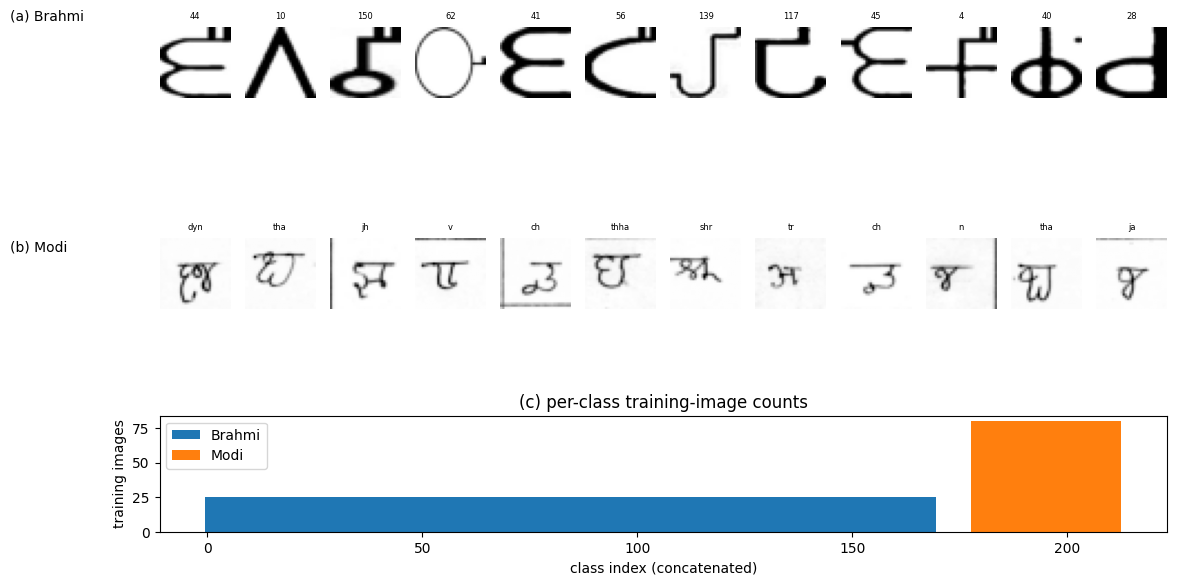

The cell below regenerates per-class sample sheets from the
partitions of the current run and saves them as
`fig_dataset_samples_Brahmi.png` and `fig_dataset_samples_Modi.png`.

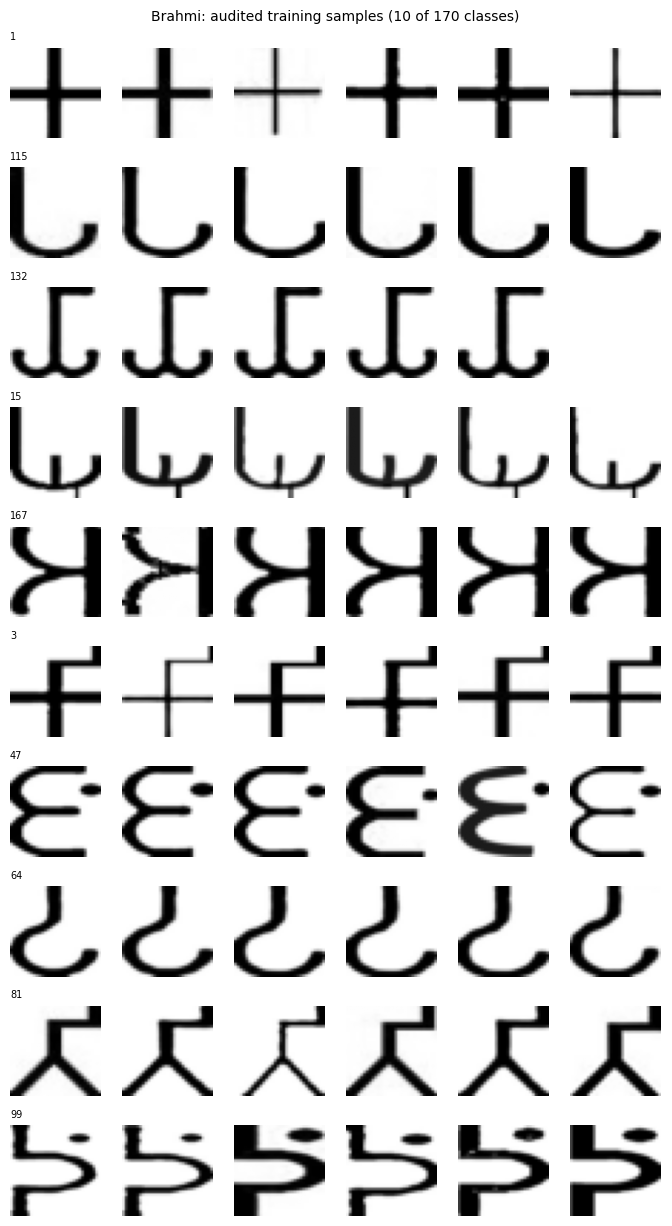

[samples Brahmi] saved fig_dataset_samples_Brahmi.png


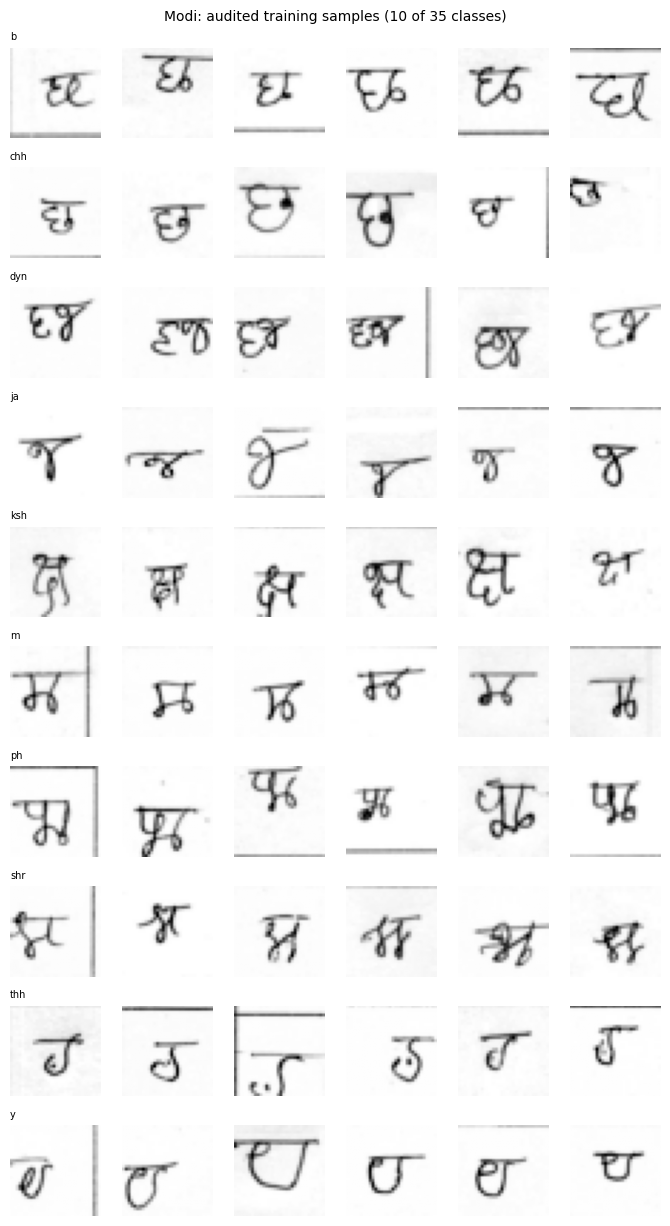

[samples Modi] saved fig_dataset_samples_Modi.png


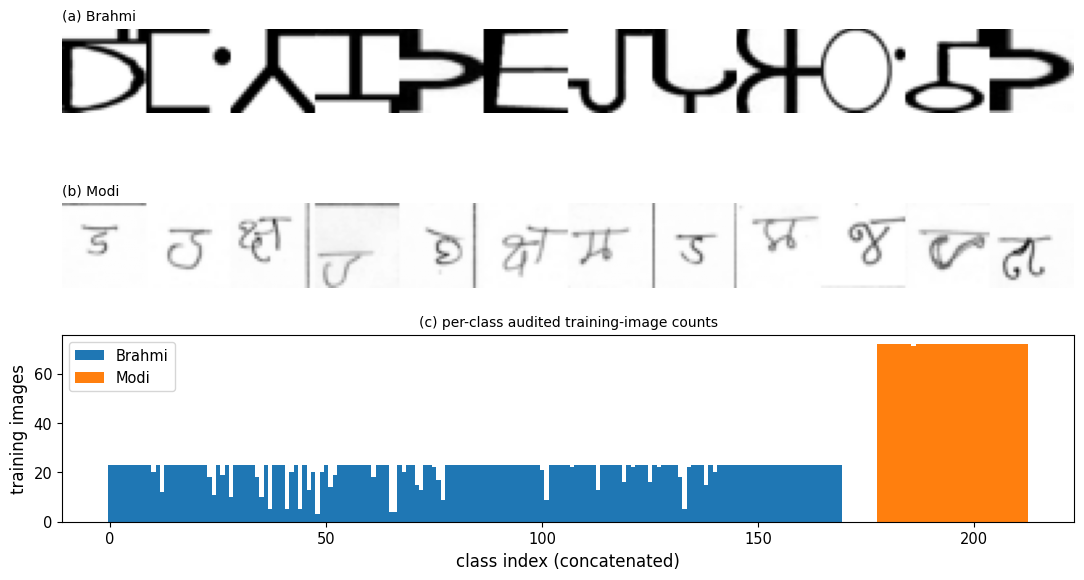

[samples] saved fig_datasets.png


In [7]:
# ---- Audited dataset samples: one row per class (subset of classes) ----
for name, a in AUD.items():
    classes = a["classes"]
    Xtr, ytr = a["Xtr"], a["ytr"]
    y = ytr.numpy() if hasattr(ytr, "numpy") else np.asarray(ytr)
    n_rows = min(10, len(classes))
    row_classes = np.unique(np.linspace(0, len(classes) - 1, n_rows).astype(int))
    n_cols = 6
    rng = np.random.default_rng(0)
    fig, axes = plt.subplots(len(row_classes), n_cols,
                             figsize=(1.15 * n_cols, 1.25 * len(row_classes)))
    axes = np.atleast_2d(axes)
    for r, c_id in enumerate(row_classes):
        idx = np.flatnonzero(y == c_id)
        pick = (rng.choice(idx, size=min(n_cols, len(idx)), replace=False)
                if len(idx) else np.array([], dtype=int))
        for k in range(n_cols):
            ax = axes[r, k]
            ax.axis("off")
            if k < len(pick):
                img = Xtr[int(pick[k])]
                img = img.numpy() if hasattr(img, "numpy") else np.asarray(img)
                ax.imshow(img[0] if img.ndim == 3 else img, cmap="gray")
        axes[r, 0].set_title(str(classes[int(c_id)]), fontsize=7, loc="left")
    fig.suptitle(f"{name}: audited training samples "
                 f"({len(row_classes)} of {len(classes)} classes)", fontsize=10)
    fig.tight_layout()
    fig.savefig(f"fig_dataset_samples_{name}.png", dpi=200, bbox_inches="tight")
    plt.show()
    print(f"[samples {name}] saved fig_dataset_samples_{name}.png")

# the paper's dataset overview: one sample strip per dataset and the
# per-class training-image counts (saved as fig_datasets.png)
fig, axes = plt.subplots(3, 1, figsize=(11, 6.2),
                         gridspec_kw={"height_ratios": [1, 1, 1.1]})
rng = np.random.default_rng(1)
for ax, (name, a) in zip(axes[:2], AUD.items()):
    y = a["ytr"].numpy() if hasattr(a["ytr"], "numpy") else np.asarray(a["ytr"])
    picks = rng.choice(len(y), size=12, replace=False)
    strip = []
    for j in picks:
        img = a["Xtr"][int(j)]
        img = img.numpy() if hasattr(img, "numpy") else np.asarray(img)
        strip.append(img[0] if img.ndim == 3 else img)
    ax.imshow(np.concatenate(strip, axis=1), cmap="gray")
    ax.set_title(f"({'ab'[list(AUD).index(name)]}) {name}", loc="left", fontsize=10)
    ax.axis("off")
ax = axes[2]
offset = 0
for name, a in AUD.items():
    y = a["ytr"].numpy() if hasattr(a["ytr"], "numpy") else np.asarray(a["ytr"])
    counts = np.bincount(y)
    ax.bar(np.arange(len(counts)) + offset, counts, width=1.0, label=name)
    offset += len(counts) + 8
ax.set_xlabel("class index (concatenated)"); ax.set_ylabel("training images")
ax.set_title("(c) per-class audited training-image counts", fontsize=10)
ax.legend()
fig.tight_layout()
fig.savefig("fig_datasets.png", dpi=200, bbox_inches="tight")
plt.show()
print("[samples] saved fig_datasets.png")


## U2: Validation-only selection of depth and augmentation
Depth grid over three circuit seeds, heads trained on the training set,
selection by mean validation accuracy alone; the test set is untouched.
Augmentation (cyclic vs zero-padded) is then selected the same way at the chosen
depth. The selections fix the protocol for every later section.

[18:35:30] U2 Brahmi depth 1: val 0.9908 +- 0.0031
[18:36:17] U2 Brahmi depth 2: val 0.9877 +- 0.0000
[18:37:06] U2 Brahmi depth 3: val 0.9897 +- 0.0036
[18:38:05] U2 Brahmi depth 4: val 0.9856 +- 0.0018
[18:39:09] U2 Brahmi depth 6: val 0.9846 +- 0.0031
[18:40:08] U2 Brahmi depth 8: val 0.9877 +- 0.0000
[U2 Brahmi] selected depth 1 | augmentation 'cyclic' (val cyclic 0.9938 vs padded 0.9877)
[18:41:22] U2 Modi depth 1: val 0.3214 +- 0.0199
[18:41:52] U2 Modi depth 2: val 0.2988 +- 0.0115
[18:42:22] U2 Modi depth 3: val 0.2500 +- 0.0258
[18:43:09] U2 Modi depth 4: val 0.2452 +- 0.0183
[18:43:57] U2 Modi depth 6: val 0.2417 +- 0.0358
[18:44:45] U2 Modi depth 8: val 0.2048 +- 0.0251
[U2 Modi] selected depth 1 | augmentation 'cyclic' (val cyclic 0.3429 vs padded 0.2464)


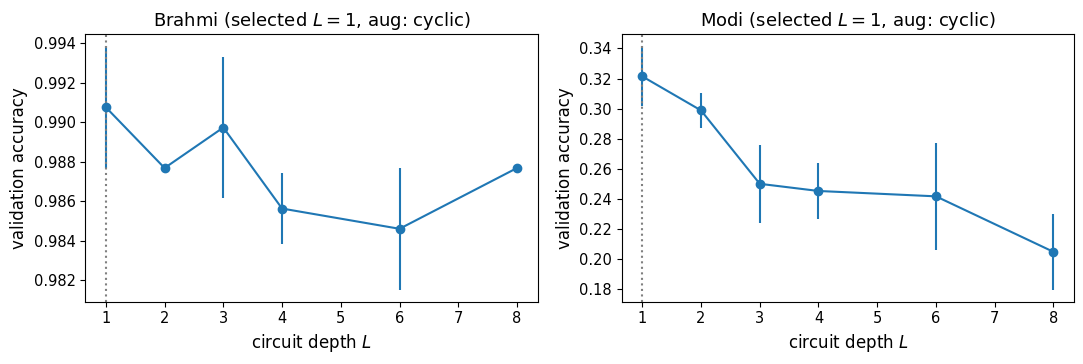

In [8]:
SEL = {}
if RUN_U2_SELECT:
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for ax, (name, a) in zip(axes, AUD.items()):
        n_classes = len(a["classes"])
        X1, y1 = aug_trainval(name)
        va_means, va_sds = [], []
        for depth in DEPTH_GRID:
            accs = []
            for cs in SEL_SEEDS:
                key = f"U2/{name}/d{depth}/c{cs}"
                if key in DONE: accs.append(DONE[key]); continue
                fx = QuantumMushroomBody(depth=depth, seed=cs)
                Z1, Z2, _, _ = standardize(fx.features(X1), fx.features(a["Xva"]))
                torch.manual_seed(SEED)
                h = MBONHead(fx.n_features, n_classes)
                _, _, va, _ = train_model(h, Z1, y1, Z2, a["yva"], n_classes, key)
                mark(key, va); accs.append(va)
                del fx, Z1, Z2, h; gc.collect()
            m, sdev = msd(accs); va_means.append(m); va_sds.append(sdev)
            log(f"U2 {name} depth {depth}: val {m:.4f} +- {sdev:.4f}")
        best = DEPTH_GRID[int(np.argmax(va_means))]
        # augmentation selection at the chosen depth (validation only)
        aug_acc = {}
        for label, fn in [("cyclic", augment), ("padded", augment_padded)]:
            key = f"U2/{name}/aug-{label}"
            if key in DONE: aug_acc[label] = DONE[key]; continue
            Xf, yf = aug_trainval(name, fn=fn)
            fx = QuantumMushroomBody(depth=best, seed=SEL_SEEDS[0])
            Z1, Z2, _, _ = standardize(fx.features(Xf), fx.features(a["Xva"]))
            torch.manual_seed(SEED)
            h = MBONHead(fx.n_features, n_classes)
            _, _, va, _ = train_model(h, Z1, yf, Z2, a["yva"], n_classes, key)
            mark(key, va); aug_acc[label] = va
            del fx, Z1, Z2, h; gc.collect()
        aug_sel = max(aug_acc, key=aug_acc.get)
        SEL[name] = {"depth": best, "aug": aug_sel, "val_curve": va_means,
                     "aug_val": aug_acc}
        save_result("U2", name, SEL[name])
        print(f"[U2 {name}] selected depth {best} | augmentation '{aug_sel}' "
              f"(val cyclic {aug_acc['cyclic']:.4f} vs padded {aug_acc['padded']:.4f})")
        ax.errorbar(DEPTH_GRID, va_means, yerr=va_sds, fmt="o-")
        ax.axvline(best, ls=":", color="gray")
        ax.set_xlabel("circuit depth $L$"); ax.set_ylabel("validation accuracy")
        ax.set_title(f"{name} (selected $L={best}$, aug: {aug_sel})")
    plt.tight_layout(); plt.savefig("fig_u_depth.png", dpi=200); plt.show(); plt.close("all")
else:
    for name in AUD: SEL[name] = {"depth": 4, "aug": "cyclic"}
AUG_FN = {name: (augment if SEL[name]["aug"] == "cyclic" else augment_padded)
          for name in AUD}

## U3: Unified main comparison (primary table)
Five runs; in each run every stochastic feature map is independently reseeded
(circuit, product unitaries, RandQuad matrices, Nystr\u00f6m landmarks, teacher and
FlyMB projections) together with the head seed. Final models train on the
development set (train+val) under the selected augmentation and are evaluated once
on the test set. Per-run test predictions for every model are kept in
memory for the paired analyses of Part 2.

[18:46:09] U3 Brahmi r0 QMB: acc 0.9805
[18:46:51] U3 Brahmi r0 Identity (L=0): acc 0.9473
[18:47:35] U3 Brahmi r0 Product U(2): acc 0.9766
[18:50:46] U3 Brahmi r0 RandQuad-525: acc 0.9707
[18:51:27] U3 Brahmi r0 Nystrom poly-2: acc 0.9766
[18:52:15] U3 Brahmi r0 Nystrom RBF: acc 0.9688
[18:52:59] U3 Brahmi r0 FlyMB-525: acc 0.9180
[18:59:16] U3 Brahmi r0 Teacher 0.9668 | QMB+KD 0.9785
[19:06:18] U3 Brahmi r0 CNN (small): acc 0.9844
[19:06:58] U3 Brahmi r0 HOG + linear head: acc 0.9766
[19:07:29] U3 Brahmi r0 RBF-SVC (subsample 5000): acc 0.9766
[19:08:14] U3 Brahmi r1 QMB: acc 0.9883
[19:08:56] U3 Brahmi r1 Identity (L=0): acc 0.9629
[19:09:36] U3 Brahmi r1 Product U(2): acc 0.9824
[19:12:36] U3 Brahmi r1 RandQuad-525: acc 0.9668
[19:13:18] U3 Brahmi r1 Nystrom poly-2: acc 0.9668
[19:13:56] U3 Brahmi r1 Nystrom RBF: acc 0.9727
[19:14:37] U3 Brahmi r1 FlyMB-525: acc 0.9219
[19:22:00] U3 Brahmi r1 Teacher 0.9609 | QMB+KD 0.9824
[19:31:28] U3 Brahmi r1 CNN (small): acc 0.9805
[19:32:20] 

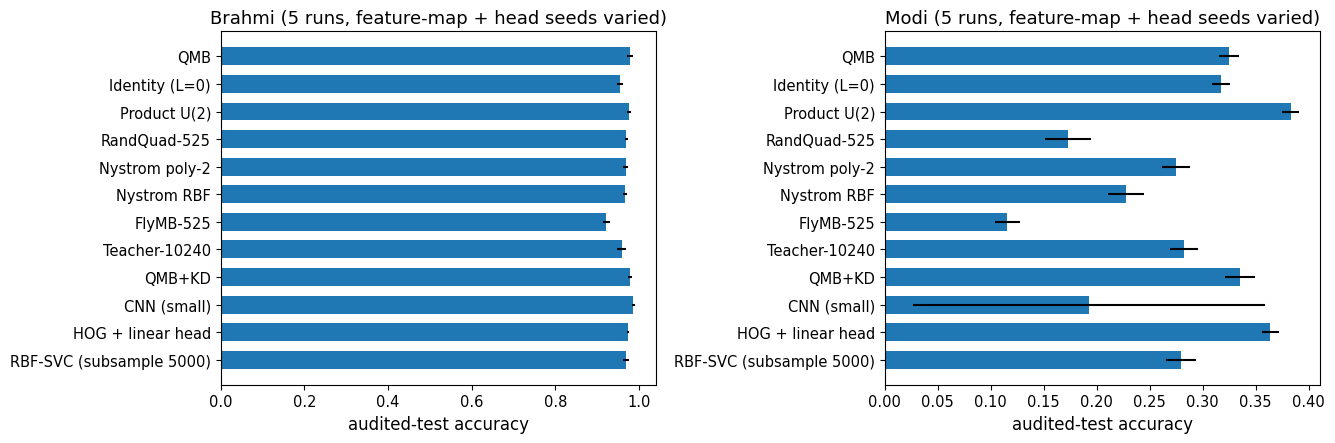

In [9]:
if RUN_U3_MAIN:
    import matplotlib.pyplot as plt
    try:
        from sklearn.svm import SVC
        HAVE_SK = True
    except ImportError:
        HAVE_SK = False
        if RUN_SVC: print("scikit-learn not installed; RBF-SVC row skipped "
                          "(pip install scikit-learn)")

    def stratified_pick_train(y, k, seed):
        g = torch.Generator().manual_seed(seed)
        order = torch.randperm(len(y), generator=g)
        per = max(1, k // len(set(y.tolist())))
        chosen, seen = [], {}
        for i in order:
            c = int(y[i])
            if seen.get(c, 0) < per and len(chosen) < k:
                chosen.append(int(i)); seen[c] = seen.get(c, 0) + 1
        for i in order:
            if len(chosen) == k: break
            if int(i) not in chosen: chosen.append(int(i))
        return torch.tensor(chosen[:k])

    class NystromRBF:
        def __init__(self, X_land, gamma=None, eps=1e-6):
            self.U = pn_normalize(X_land)
            d2 = torch.cdist(self.U, self.U) ** 2
            if gamma is None:
                med = d2[d2 > 0].median()
                gamma = 1.0 / med.clamp(min=1e-6)
            self.g = float(gamma)
            K = torch.exp(-self.g * d2)
            lam, V = torch.linalg.eigh(K.double())
            keep = lam > eps * lam.max()
            self.W = (V[:, keep] * lam[keep].rsqrt()).float()
            self.n_features = self.W.shape[1]
        def features(self, X, batch=512):
            out = torch.empty(len(X), self.n_features)
            for i in range(0, len(X), batch):
                K = torch.exp(-self.g * torch.cdist(pn_normalize(X[i:i+batch]), self.U) ** 2)
                out[i:i + batch] = K @ self.W
            return out

    U3 = {}; PREDS = {}
    for name, a in AUD.items():
        n_classes = len(a["classes"]); yte = a["yte"]
        Xdev_a, ydev_a = augmented(a["Xdev"], a["ydev"], fn=AUG_FN[name])
        rows = {}
        def add(model_lab, run, acc, f1, preds):
            rows.setdefault(model_lab, {"acc": [], "f1": []})
            rows[model_lab]["acc"].append(acc); rows[model_lab]["f1"].append(f1)
            PREDS[f"{name}/{model_lab}/r{run}"] = preds.numpy()

        for r in range(N_RUNS):
            hs = SEED + r                                  # head seed
            def head_fit(Ftr, Fte, tag, Ttr=None):
                torch.manual_seed(hs)
                h = MBONHead(Ftr.shape[1], n_classes)
                _, preds, acc, f1 = train_model_kd(h, Ftr, ydev_a, Fte, yte,
                                                   n_classes, tag, Ttr=Ttr)
                del h; gc.collect()
                return preds, acc, f1

            def run_model(lab, fn):
                key = f"U3/{name}/{lab}/r{r}"
                if key in DONE:
                    acc, f1, pl = DONE[key]
                    add(lab, r, acc, f1, torch.tensor(pl)); return
                preds, acc, f1 = fn()
                mark(key, (acc, f1, preds.tolist())); add(lab, r, acc, f1, preds)
                log(f"U3 {name} r{r} {lab}: acc {acc:.4f}")

            # quantum / quadratic / kernel feature maps (standardized + head)
            def fm(fx):
                Z1, Z2, _, _ = standardize(fx.features(Xdev_a), fx.features(a["Xte"]))
                out = head_fit(Z1, Z2, "fm")
                del Z1, Z2; gc.collect()
                return out
            run_model("QMB", lambda: fm(QuantumMushroomBody(
                depth=SEL[name]["depth"], seed=QMB_SEED + r)))
            run_model("Identity (L=0)", lambda: fm(QuantumMushroomBody(depth=0)))
            run_model("Product U(2)", lambda: fm(product_circuit_mb(seed=QMB_SEED + r)))
            run_model("RandQuad-525", lambda: fm(RandomQuadraticFeatures(D_IN, seed=1234 + r)))
            run_model("Nystrom poly-2", lambda: fm(NystromPoly2Features(
                Xdev_a[stratified_pick_train(ydev_a, N_FEAT, seed=SEED + r)])))
            run_model("Nystrom RBF", lambda: fm(NystromRBF(
                Xdev_a[stratified_pick_train(ydev_a, N_FEAT, seed=SEED + r)])))
            run_model("FlyMB-525", lambda: fm(FlyFeatures(
                D_IN, N_FEAT, FAN_IN, max(1, round(KC_SPARSITY * N_FEAT)), seed=SEED + r)))

            # teacher (10,240) + KD student, memory-lean path
            def teacher_and_kd():
                fxT = FlyFeatures(D_IN, N_KC, FAN_IN, K_ACTIVE, seed=SEED + r)
                Z1, muT, sdT = feats_std_inplace(fxT, Xdev_a)
                Z2, _, _ = feats_std_inplace(fxT, a["Xte"], muT, sdT)
                torch.manual_seed(hs)
                hT = MBONHead(N_KC, n_classes)
                hT, predsT, accT, f1T = train_model_kd(hT, Z1, ydev_a, Z2, yte,
                                                       n_classes, "T")
                hT = hT.cpu().eval()
                with torch.no_grad():
                    Ttr = torch.cat([hT(Z1[i:i + 512]) for i in range(0, len(Z1), 512)])
                del Z1, Z2; gc.collect()
                fxQ = QuantumMushroomBody(depth=SEL[name]["depth"], seed=QMB_SEED + r)
                Q1, Q2, _, _ = standardize(fxQ.features(Xdev_a), fxQ.features(a["Xte"]))
                predsK, accK, f1K = head_fit(Q1, Q2, "KD", Ttr=Ttr)
                del Q1, Q2, Ttr, hT, fxT, fxQ; gc.collect()
                return (predsT, accT, f1T), (predsK, accK, f1K)
            keyT = f"U3/{name}/Teacher-10240/r{r}"; keyK = f"U3/{name}/QMB+KD/r{r}"
            if keyT in DONE and keyK in DONE:
                aT, fT, pT = DONE[keyT]; add("Teacher-10240", r, aT, fT, torch.tensor(pT))
                aK, fK, pK = DONE[keyK]; add("QMB+KD", r, aK, fK, torch.tensor(pK))
            else:
                (pT, aT, fT), (pK, aK, fK) = teacher_and_kd()
                mark(keyT, (aT, fT, pT.tolist())); add("Teacher-10240", r, aT, fT, pT)
                mark(keyK, (aK, fK, pK.tolist())); add("QMB+KD", r, aK, fK, pK)
                log(f"U3 {name} r{r} Teacher {aT:.4f} | QMB+KD {aK:.4f}")

            # external baselines
            def cnn_fit():
                torch.manual_seed(hs)
                net = SmallCNN(n_classes)
                _, preds, acc, f1 = train_model_kd(net, Xdev_a, ydev_a,
                                                   a["Xte"], yte, n_classes,
                                                   "CNN", epochs=EPOCHS_CNN)
                del net; gc.collect()
                return preds, acc, f1
            run_model("CNN (small)", cnn_fit)

            def hog_fit():
                H1 = hog_features(Xdev_a); H2 = hog_features(a["Xte"])
                Z1, Z2, _, _ = standardize(H1, H2)
                out = head_fit(Z1, Z2, "HOG")
                del H1, H2, Z1, Z2; gc.collect()
                return out
            run_model("HOG + linear head", hog_fit)

            if RUN_SVC and HAVE_SK:
                def svc_fit():
                    sub = stratified_pick_train(ydev_a, min(SVC_SUBSAMPLE, len(ydev_a)),
                                                seed=SEED + r)
                    Xs = pn_normalize(Xdev_a[sub]).numpy()
                    clf = SVC(C=10.0, gamma="scale")
                    clf.fit(Xs, ydev_a[sub].numpy())
                    preds = torch.tensor(clf.predict(pn_normalize(a["Xte"]).numpy()))
                    acc = (preds == yte).float().mean().item()
                    return preds, acc, macro_f1(yte, preds, n_classes)
                run_model(f"RBF-SVC (subsample {SVC_SUBSAMPLE})", svc_fit)

        U3[name] = rows
        print(f"\n[U3 {name}] unified comparison over {N_RUNS} runs "
              f"(audited test, mean \u00b1 sample std):")
        qmb_acc = rows["QMB"]["acc"]
        print(f"    {'model':<26s} {'accuracy':>18s} {'macro-F1':>18s} "
              f"{'paired vs QMB':>16s}")
        for lab, v in rows.items():
            (ma, sa), (mf, sf) = msd(v["acc"]), msd(v["f1"])
            diffs = [x - q for x, q in zip(v["acc"], qmb_acc)]
            md_, sd_ = msd(diffs)
            print(f"    {lab:<26s} {ma:.4f} \u00b1 {sa:.4f}   {mf:.4f} \u00b1 {sf:.4f} "
                  f"  {md_:+.4f} \u00b1 {sd_:.4f}")
        save_result("U3", name, {lab: {"acc": v["acc"], "f1": v["f1"]}
                                 for lab, v in rows.items()})

    # keep the per-run predictions in memory for the audit sections
    P_U3 = {**{k: v for k, v in PREDS.items()},
            **{f"ytest/{n}": AUD[n]["yte"].numpy() for n in AUD}}

    # ---- figure: unified comparison ----
    fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))
    for ax, (name, rows) in zip(axes, U3.items()):
        labs = list(rows.keys())
        means = [msd(rows[l]["acc"])[0] for l in labs]
        sds   = [msd(rows[l]["acc"])[1] for l in labs]
        ypos = np.arange(len(labs))
        ax.barh(ypos, means, xerr=sds, height=0.65)
        ax.set_yticks(ypos); ax.set_yticklabels(labs, fontsize=10.5)
        ax.invert_yaxis()
        ax.set_xlabel("audited-test accuracy")
        ax.set_title(f"{name} ({N_RUNS} runs, feature-map + head seeds varied)")
    plt.tight_layout(); plt.savefig("fig_u_main.png", dpi=200); plt.show(); plt.close("all")

## U4: Readout-family ablation
Encoding, circuits, head protocol, and (where applicable) feature count are held
fixed; only the measurement family varies: the standard three-setting $X/Y/Z$
weight-$\leq3$ family, a single-setting $Z$-only family at the same feature count,
three random product-axis settings, and weight-restricted variants. Evaluated for
the identity, product, and selected-depth QMB circuits (exact features, three head
seeds).

[21:51:50] U4 Brahmi identity | XYZ w<=3 (525): 0.9564
[21:53:34] U4 Brahmi identity | Z-only 525: 0.9199
[21:55:20] U4 Brahmi identity | 3 random axes w<=3 (525): 0.9733
[21:56:32] U4 Brahmi identity | XYZ w<=2 (165): 0.9616
[21:57:25] U4 Brahmi identity | XYZ w=1 (30): 0.8125
[21:58:47] U4 Brahmi product | XYZ w<=3 (525): 0.9818
[22:00:19] U4 Brahmi product | Z-only 525: 0.9590
[22:01:52] U4 Brahmi product | 3 random axes w<=3 (525): 0.9811
[22:02:55] U4 Brahmi product | XYZ w<=2 (165): 0.9766
[22:03:54] U4 Brahmi product | XYZ w=1 (30): 0.8490
[22:05:28] U4 Brahmi QMB L=1 | XYZ w<=3 (525): 0.9818
[22:06:50] U4 Brahmi QMB L=1 | Z-only 525: 0.9688
[22:08:20] U4 Brahmi QMB L=1 | 3 random axes w<=3 (525): 0.9785
[22:09:24] U4 Brahmi QMB L=1 | XYZ w<=2 (165): 0.9727
[22:10:19] U4 Brahmi QMB L=1 | XYZ w=1 (30): 0.8939

[U4 Brahmi] readout-family ablation (mean ± sd, 3 head seeds):
    circuit      | XYZ w<=3 (525)           | Z-only 525               | 3 random axes w<=3 (525) | XYZ w<=2 

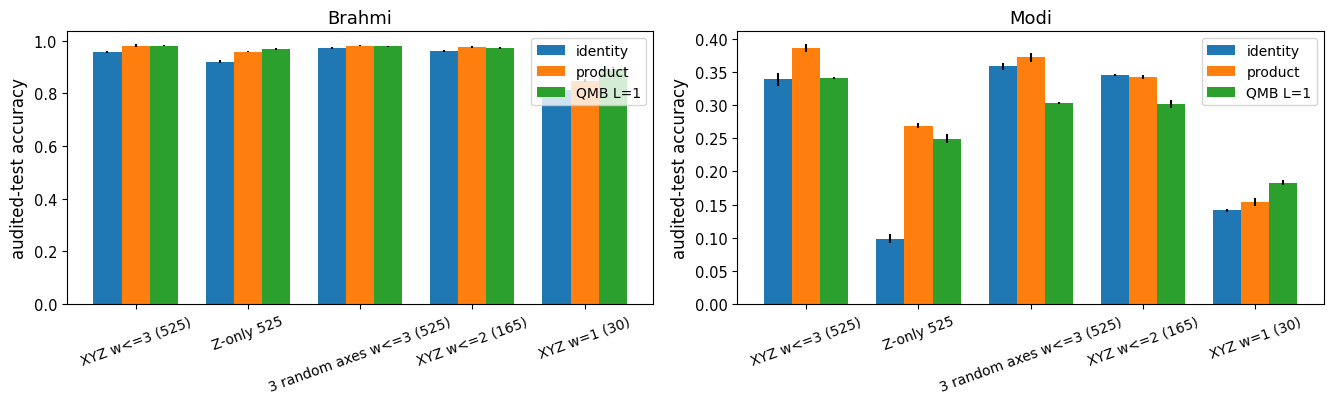

In [10]:
if RUN_U4_READOUT:
    import matplotlib.pyplot as plt
    g_ax = torch.Generator().manual_seed(99)
    RAND_SETTINGS = [[random_axis_rotation(g_ax) for _ in range(N_QUBITS)]
                     for _ in range(3)]
    I2 = torch.eye(2, dtype=torch.complex64)
    Z_SET  = [None]; XYZ = [[H_1] * N_QUBITS, [HSd] * N_QUBITS]
    sub_w3 = subsets_by_weight(N_QUBITS, 3); m_w3 = masks_of(sub_w3)
    sub_w2 = subsets_by_weight(N_QUBITS, 2); m_w2 = masks_of(sub_w2)
    sub_w1 = subsets_by_weight(N_QUBITS, 1); m_w1 = masks_of(sub_w1)
    sub_all = subsets_by_weight(N_QUBITS, N_QUBITS)
    m_z525 = masks_of(sub_all[:N_FEAT])      # lowest-weight 525 parities, Z only

    def families():
        yield "XYZ w<=3 (525)",   [None] + XYZ, [m_w3, m_w3, m_w3]
        yield "Z-only 525",       [None],       [m_z525]
        yield "3 random axes w<=3 (525)", RAND_SETTINGS, [m_w3, m_w3, m_w3]
        yield "XYZ w<=2 (165)",   [None] + XYZ, [m_w2, m_w2, m_w2]
        yield "XYZ w=1 (30)",     [None] + XYZ, [m_w1, m_w1, m_w1]

    U4 = {}
    for name, a in AUD.items():
        n_classes = len(a["classes"])
        Xdev_a, ydev_a = augmented(a["Xdev"], a["ydev"], fn=AUG_FN[name])
        circuits = {"identity": torch.eye(D_IN, dtype=torch.complex64),
                    "product":  product_circuit_mb(seed=QMB_SEED).U,
                    f"QMB L={SEL[name]['depth']}":
                        QuantumMushroomBody(depth=SEL[name]["depth"],
                                            seed=QMB_SEED).U}
        res = {}
        for cl, Uc in circuits.items():
            for fl, settings, masks in families():
                key = f"U4/{name}/{cl}/{fl}"
                if key in DONE:
                    res[(cl, fl)] = tuple(DONE[key]); continue
                ro = GeneralReadout(Uc, settings, masks)
                Z1, Z2, _, _ = standardize(ro.features(Xdev_a), ro.features(a["Xte"]))
                accs = []
                for s in [42, 43, 44]:
                    torch.manual_seed(s)
                    h = MBONHead(ro.n_features, n_classes)
                    _, _, acc, _ = train_model(h, Z1, ydev_a, Z2, a["yte"],
                                               n_classes, key)
                    accs.append(acc); del h
                del ro, Z1, Z2; gc.collect()
                res[(cl, fl)] = msd(accs)
                mark(key, res[(cl, fl)])
                log(f"U4 {name} {cl} | {fl}: {res[(cl,fl)][0]:.4f}")
        U4[name] = res
        print(f"\n[U4 {name}] readout-family ablation (mean \u00b1 sd, 3 head seeds):")
        fam_names = [f for f, _, _ in families()]
        print("    " + " | ".join([f"{'circuit':<12s}"] + [f"{f:<24s}" for f in fam_names]))
        for cl in circuits:
            row = [f"{cl:<12s}"] + [f"{res[(cl,f)][0]:.4f} \u00b1 {res[(cl,f)][1]:.4f}      "
                                    for f in fam_names]
            print("    " + " | ".join(row))
        save_result("U4", name, {f"{cl}|{f}": list(v) for (cl, f), v in res.items()})

    fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.2))
    fam_names = [f for f, _, _ in families()]
    for ax, (name, res) in zip(axes, U4.items()):
        width = 0.25
        xs = np.arange(len(fam_names))
        for k, cl in enumerate(["identity", "product",
                                f"QMB L={SEL[name]['depth']}"]):
            m = [res[(cl, f)][0] for f in fam_names]
            e = [res[(cl, f)][1] for f in fam_names]
            ax.bar(xs + (k - 1) * width, m, width, yerr=e, label=cl)
        ax.set_xticks(xs); ax.set_xticklabels(fam_names, rotation=20, fontsize=10)
        ax.set_ylabel("audited-test accuracy"); ax.set_title(name); ax.legend(fontsize=10)
    plt.tight_layout(); plt.savefig("fig_u_readout.png", dpi=200); plt.show(); plt.close("all")

## U5: Feature-space diagnostics
Per feature map: number of (near-)zero-variance training coordinates, the
analytically predicted 130 identically-zero odd-weight $Y$ coordinates of the
identity circuit, and effective rank (99\% eigen-energy) of the standardized
training features.

[U5 Brahmi] identity: |odd-weight Y features| max = 4.77e-07 over 130 coordinates (analytic prediction: exactly 0)
[U5 Brahmi] identity       zero-variance coords  130 / 525 | effective rank (99%) 365
[U5 Brahmi] product        zero-variance coords    0 / 525 | effective rank (99%) 301
[U5 Brahmi] QMB L=1        zero-variance coords    0 / 525 | effective rank (99%) 357
[U5 Brahmi] RandQuad-525   zero-variance coords    0 / 525 | effective rank (99%) 491
[U5 Modi] identity: |odd-weight Y features| max = 3.73e-07 over 130 coordinates (analytic prediction: exactly 0)
[U5 Modi] identity       zero-variance coords  130 / 525 | effective rank (99%) 413
[U5 Modi] product        zero-variance coords    0 / 525 | effective rank (99%) 389
[U5 Modi] QMB L=1        zero-variance coords    0 / 525 | effective rank (99%) 430
[U5 Modi] RandQuad-525   zero-variance coords    0 / 525 | effective rank (99%) 511


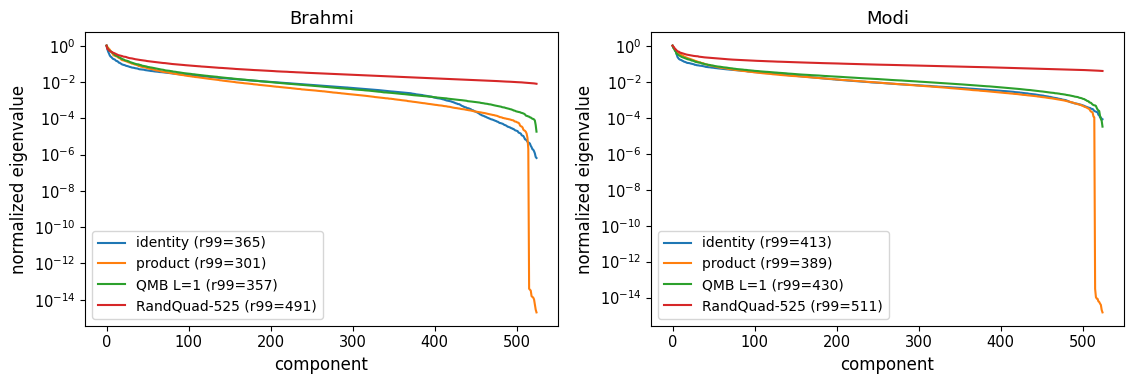

In [11]:
if RUN_U5_DIAG:
    import matplotlib.pyplot as plt
    sub_w3 = subsets_by_weight(N_QUBITS, 3)
    n_sub = len(sub_w3)
    odd_y = torch.tensor([2 * n_sub + j for j, S in enumerate(sub_w3)
                          if len(S) % 2 == 1])
    U5 = {}
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
    for ax, (name, a) in zip(axes, AUD.items()):
        Xdev_a, _ = augmented(a["Xdev"], a["ydev"], fn=AUG_FN[name])
        maps = {"identity": QuantumMushroomBody(depth=0),
                "product": product_circuit_mb(seed=QMB_SEED),
                f"QMB L={SEL[name]['depth']}":
                    QuantumMushroomBody(depth=SEL[name]["depth"], seed=QMB_SEED),
                "RandQuad-525": RandomQuadraticFeatures(D_IN)}
        rep = {}
        for lab, fx in maps.items():
            Fraw = fx.features(Xdev_a)
            sdv = Fraw.std(0)
            n_zero = int((sdv < 1e-6).sum())
            Z = (Fraw - Fraw.mean(0)) / (sdv + 1e-8)
            cov_e = torch.linalg.svdvals(Z / math.sqrt(len(Z))) ** 2
            energy = torch.cumsum(cov_e, 0) / cov_e.sum()
            r99 = int((energy < 0.99).sum()) + 1
            rep[lab] = {"zero_coords": n_zero, "rank99": r99,
                        "n_features": Fraw.shape[1]}
            if lab == "identity":
                max_odd_y = float(Fraw[:, odd_y].abs().max())
                rep[lab]["max_abs_oddY"] = max_odd_y
                print(f"[U5 {name}] identity: |odd-weight Y features| max = "
                      f"{max_odd_y:.2e} over {len(odd_y)} coordinates "
                      f"(analytic prediction: exactly 0)")
            ax.semilogy(cov_e.numpy() / cov_e[0].item(), label=f"{lab} (r99={r99})")
            del Fraw, Z; gc.collect()
            print(f"[U5 {name}] {lab:<14s} zero-variance coords {rep[lab]['zero_coords']:>4d}"
                  f" / {rep[lab]['n_features']} | effective rank (99%) {rep[lab]['rank99']}")
        U5[name] = rep; save_result("U5", name, rep)
        ax.set_xlabel("component"); ax.set_ylabel("normalized eigenvalue")
        ax.set_title(name); ax.legend(fontsize=10)
    plt.tight_layout(); plt.savefig("fig_u_rank.png", dpi=200); plt.show(); plt.close("all")

## U6: Shot-budget predictor ablation
Fixed heads under the unified protocol; ten sampling realizations per budget. Three
predictors are compared so that covariance and multiclass effects are separated:
(i) diagonal covariance with top-two margins, (ii) diagonal covariance with full
multiclass Monte Carlo, (iii) full shared-shot covariance with multiclass Monte
Carlo. Monte-Carlo uncertainty is reported from two MC seeds. Covariances use
exact simulator probabilities, so all three are offline diagnostics. The analysis
is run for the QMB and repeated for the product circuit.

[22:26:17] U6 Brahmi/QMB: building per-sample covariances
[U6 Brahmi/QMB] M=   512: fixed 0.9182±0.0089 | diag-top2 0.9420 | diag-MC 0.9396 (±0.0001 MC) | full-MC 0.9193 (±0.0000 MC)
[U6 Brahmi/QMB] M=  1024: fixed 0.9545±0.0059 | diag-top2 0.9572 | diag-MC 0.9595 (±0.0001 MC) | full-MC 0.9517 (±0.0002 MC)
[U6 Brahmi/QMB] M=  4096: fixed 0.9697±0.0053 | diag-top2 0.9685 | diag-MC 0.9716 (±0.0000 MC) | full-MC 0.9703 (±0.0001 MC)
[U6 Brahmi/QMB] M= 16384: fixed 0.9754±0.0043 | diag-top2 0.9734 | diag-MC 0.9756 (±0.0000 MC) | full-MC 0.9747 (±0.0001 MC)
[22:28:28] U6 Brahmi/product: building per-sample covariances
[U6 Brahmi/product] M=   512: fixed 0.9154±0.0115 | diag-top2 0.9414 | diag-MC 0.9425 (±0.0002 MC) | full-MC 0.9203 (±0.0002 MC)
[U6 Brahmi/product] M=  1024: fixed 0.9553±0.0072 | diag-top2 0.9566 | diag-MC 0.9610 (±0.0000 MC) | full-MC 0.9520 (±0.0000 MC)
[U6 Brahmi/product] M=  4096: fixed 0.9713±0.0057 | diag-top2 0.9685 | diag-MC 0.9728 (±0.0001 MC) | full-MC 0.9711 (±0.00

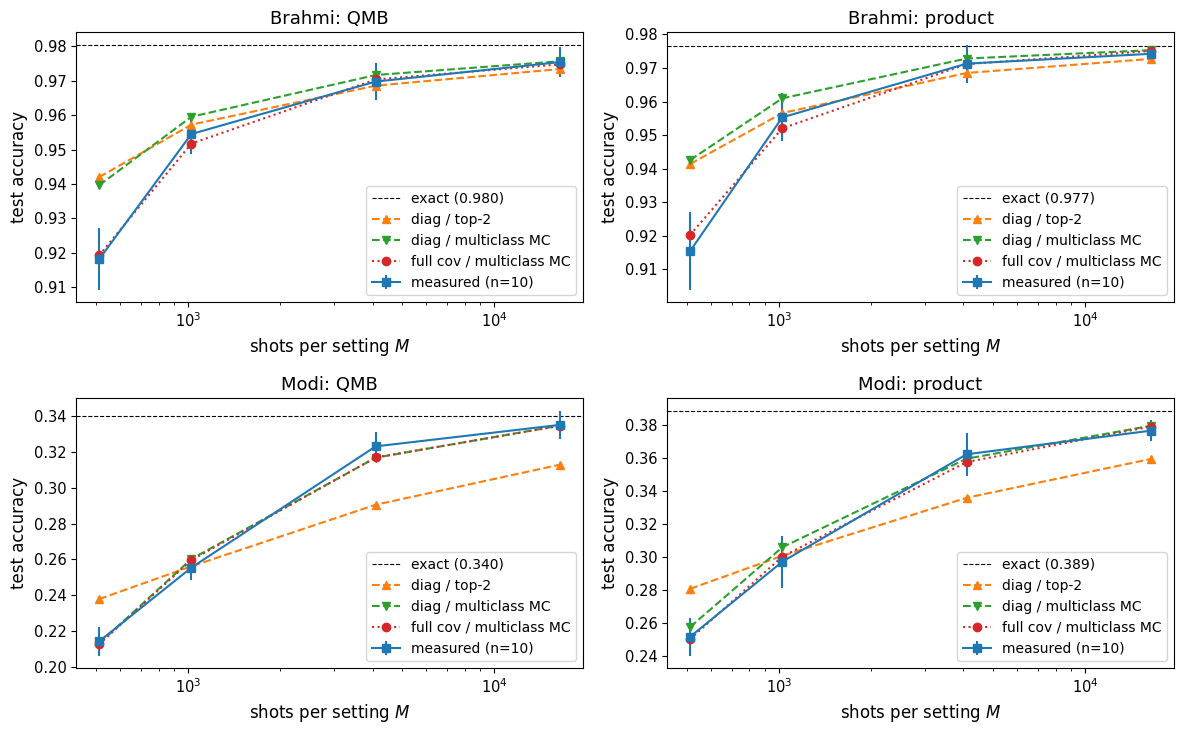

In [12]:
if RUN_U6_PREDICTOR:
    import matplotlib.pyplot as plt
    from math import erf, sqrt
    Phi = lambda t: 0.5 * (1 + torch.erf(t / math.sqrt(2.0)))
    sub_w3 = subsets_by_weight(N_QUBITS, 3)
    masks_w3 = masks_of(sub_w3)
    XORm = masks_w3.unsqueeze(0) ^ masks_w3.unsqueeze(1)
    n_sub = len(sub_w3)

    def predictor_suite(name, fx, tag):
        a = AUD[name]; n_classes = len(a["classes"]); yte = a["yte"]
        Xdev_a, ydev_a = augmented(a["Xdev"], a["ydev"], fn=AUG_FN[name])
        F1r, F2r = fx.features(Xdev_a), fx.features(a["Xte"])
        Z1, Z2, mu, sd = standardize(F1r, F2r)
        torch.manual_seed(SEED)
        head = MBONHead(fx.n_features, n_classes)
        head, _, a_ex, _ = train_model(head, Z1, ydev_a, Z2, yte, n_classes, tag)
        W = head.net[1].weight.detach().cpu(); b = head.net[1].bias.detach().cpu()
        logits = Z2 @ W.T + b
        top2 = logits.topk(2, dim=1)
        c1, c2 = top2.indices[:, 0], top2.indices[:, 1]
        margin = top2.values[:, 0] - top2.values[:, 1]
        correct = (c1 == yte)
        var_raw = (1 - F2r ** 2).clamp(min=0) / (sd ** 2)
        dW = W[c1] - W[c2]
        Dinv = (1.0 / sd[0])

        log(f"U6 {name}/{tag}: building per-sample covariances")
        Vb_full, Vb_diag = [], []
        with torch.no_grad():
            for sl, P in fx.probs(a["Xte"]):
                for i in range(P["Z"].shape[0]):
                    blocks = []
                    for bi, basis in enumerate(("Z", "X", "Y")):
                        par = fwht(P[basis][i])
                        phiT = par[masks_w3]
                        cov = par[XORm] - phiT.unsqueeze(1) * phiT.unsqueeze(0)
                        blocks.append(cov)
                    S = torch.zeros(fx.n_features, fx.n_features)
                    for bi in range(3):
                        s0 = bi * n_sub
                        S[s0:s0+n_sub, s0:s0+n_sub] = blocks[bi]
                    S = Dinv.unsqueeze(1) * S * Dinv.unsqueeze(0)
                    Vb_full.append(W @ S @ W.T)
                    Sd = torch.diag(torch.diagonal(S))
                    Vb_diag.append(W @ Sd @ W.T)
        Vb_full = torch.stack(Vb_full); Vb_diag = torch.stack(Vb_diag)

        def mc_acc(Vb, M, mc_seed):
            g = torch.Generator().manual_seed(mc_seed)
            hits = 0.0
            for i in range(len(yte)):
                A = Vb[i] / M
                try:
                    Lc = torch.linalg.cholesky(A + 1e-9 * torch.eye(A.shape[0]))
                except Exception:
                    Lc = torch.linalg.cholesky(
                        A + 1e-6 * A.diagonal().mean().clamp(min=1e-12)
                        * torch.eye(A.shape[0]))
                eta = torch.randn(U6_MC_DRAWS, Vb.shape[1], generator=g) @ Lc.T
                pred = (logits[i].unsqueeze(0) + eta).argmax(1)
                hits += (pred == yte[i]).float().mean().item()
            return hits / len(yte)

        out = {"exact": a_ex, "budgets": {}}
        for M in U6_BUDGETS:
            key = f"U6/{name}/{tag}/M{M}"
            if key in DONE:
                out["budgets"][M] = DONE[key]
                continue
            fixed = []
            for rr in range(U6_REPEATS):
                gen = torch.Generator().manual_seed(1000 + rr)
                Sh = fx.features(a["Xte"], shots=M, gen=gen)
                acc, _ = eval_batched(head, (Sh - mu) / sd, yte)
                fixed.append(acc)
            mf, sf = msd(fixed)
            s_diag = torch.sqrt((dW ** 2 * var_raw).sum(1) / M) + 1e-12
            p_d2  = (Phi(margin / s_diag) * correct.float()).mean().item()
            p_dmc = [mc_acc(Vb_diag, M, ms) for ms in U6_MC_SEEDS]
            p_fmc = [mc_acc(Vb_full, M, ms) for ms in U6_MC_SEEDS]
            rec = {"fixed_mean": mf, "fixed_sd": sf,
                   "pred_diag_top2": p_d2,
                   "pred_diag_mc": p_dmc, "pred_full_mc": p_fmc}
            mark(key, rec); out["budgets"][M] = rec
            print(f"[U6 {name}/{tag}] M={M:>6}: fixed {mf:.4f}\u00b1{sf:.4f} | "
                  f"diag-top2 {p_d2:.4f} | diag-MC {np.mean(p_dmc):.4f} "
                  f"(\u00b1{np.std(p_dmc):.4f} MC) | full-MC {np.mean(p_fmc):.4f} "
                  f"(\u00b1{np.std(p_fmc):.4f} MC)")
        save_result("U6", f"{name}/{tag}", {str(k): v for k, v in out["budgets"].items()}
                    | {"exact": a_ex})
        del Vb_full, Vb_diag, F1r, F2r, Z1, Z2; gc.collect()
        return out

    U6 = {}
    for name in AUD:
        U6[(name, "QMB")] = predictor_suite(
            name, QuantumMushroomBody(depth=SEL[name]["depth"], seed=QMB_SEED), "QMB")
        U6[(name, "product")] = predictor_suite(
            name, product_circuit_mb(seed=QMB_SEED), "product")

    fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
    for ax, ((name, tag), out) in zip(axes.flat, U6.items()):
        xs = U6_BUDGETS
        B = out["budgets"]
        ax.axhline(out["exact"], ls="--", color="k", lw=0.8,
                   label=f"exact ({out['exact']:.3f})")
        ax.errorbar(xs, [B[M]["fixed_mean"] for M in xs],
                    yerr=[B[M]["fixed_sd"] for M in xs], fmt="s-",
                    label=f"measured (n={U6_REPEATS})")
        ax.plot(xs, [B[M]["pred_diag_top2"] for M in xs], "^--",
                label="diag / top-2")
        ax.plot(xs, [np.mean(B[M]["pred_diag_mc"]) for M in xs], "v--",
                label="diag / multiclass MC")
        ax.plot(xs, [np.mean(B[M]["pred_full_mc"]) for M in xs], "o:",
                label="full cov / multiclass MC")
        ax.set_xscale("log"); ax.set_xlabel("shots per setting $M$")
        ax.set_ylabel("test accuracy"); ax.set_title(f"{name}: {tag}")
        ax.legend(fontsize=10)
    plt.tight_layout(); plt.savefig("fig_u_predictor.png", dpi=200); plt.show(); plt.close("all")

## U7: Optional hardware circuit-family control (`ibm_fez`, $n{=}8$)
Executes the *same* encoded inputs under identity, product, and brickwork
processing with common compilation settings, so the attenuation attributable to
amplitude preparation alone (identity) can be separated from the circuit
contribution. Automatic submit and retrieve; roughly 60--90 s of QPU time in total.

The outputs below are retained from the executed campaign of 12
October 2026 (job records in `qpu_jobs_unified.json`), since a third party cannot regenerate
physical-device results; the cell itself is off by default.

In [ ]:
if RUN_U7_HARDWARE:
    try:
        import numpy as _np
        from qiskit import QuantumCircuit
        from qiskit.circuit.library import UnitaryGate
        IS_QISKIT = True
    except ImportError:
        IS_QISKIT = False
        print("qiskit not installed; U7 skipped.")
    if IS_QISKIT:
        def _service():
            from qiskit_ibm_runtime import QiskitRuntimeService
            tok = IBM_TOKEN or os.environ.get("IBM_QUANTUM_TOKEN", "")
            if tok:
                kw = dict(channel=IBM_CHANNEL, token=tok)
                if IBM_INSTANCE: kw["instance"] = IBM_INSTANCE
                return QiskitRuntimeService(**kw)
            return QiskitRuntimeService()

        def _jobs():
            return _json.load(open(QPU_JOBS_FILE)) if os.path.exists(QPU_JOBS_FILE) else {}

        n8 = int(math.log2(U7_IMG_SIZE ** 2))
        d16 = build_dataset("Brahmi16u", DATA_ROOTS["Brahmi"], img_size=U7_IMG_SIZE)
        g = torch.Generator().manual_seed(31)
        order = torch.randperm(len(d16["yte"]), generator=g)[:U7_IMAGES]
        XB = d16["Xte"][order]

        gen8 = torch.Generator().manual_seed(QMB_SEED)
        U_prod8 = kron_n_list([random_u2(gen8) for _ in range(n8)])
        fam = {
            "identity":  QuantumMushroomBody(n_qubits=n8, depth=0),
            "product":   QuantumMushroomBody(n_qubits=n8, U=U_prod8),
            "brickwork": QuantumMushroomBody(n_qubits=n8, depth=SEL["Brahmi"]["depth"],
                                             seed=QMB_SEED),
        }

        def circuits_for(qobj, x):
            n = qobj.n
            psi = pn_normalize(x.unsqueeze(0))[0].numpy().astype(_np.complex128)
            psi = psi / _np.linalg.norm(psi)
            out = {}
            for basis in ("Z", "X", "Y"):
                qc = QuantumCircuit(n)
                qc.initialize(psi)
                for (q0, q1), Mg in qobj.gates:
                    M64 = Mg.numpy().astype(_np.complex128)
                    uu, _, vh = _np.linalg.svd(M64)
                    qc.append(UnitaryGate(uu @ vh), [n-1-q1, n-1-q0])
                for q in range(n):
                    if basis == "X": qc.h(q)
                    elif basis == "Y": qc.sdg(q); qc.h(q)
                qc.measure_all()
                out[basis] = qc
            return out

        def circuits_for_product(x):
            n = n8
            psi = pn_normalize(x.unsqueeze(0))[0].numpy().astype(_np.complex128)
            psi = psi / _np.linalg.norm(psi)
            gen = torch.Generator().manual_seed(QMB_SEED)
            su2s = [random_u2(gen) for _ in range(n)]
            out = {}
            for basis in ("Z", "X", "Y"):
                qc = QuantumCircuit(n)
                qc.initialize(psi)
                for q_log, M in enumerate(su2s):
                    M64 = M.numpy().astype(_np.complex128)
                    uu, _, vh = _np.linalg.svd(M64)
                    qc.append(UnitaryGate(uu @ vh), [n - 1 - q_log])
                for q in range(n):
                    if basis == "X": qc.h(q)
                    elif basis == "Y": qc.sdg(q); qc.h(q)
                qc.measure_all()
                out[basis] = qc
            return out

        def counts_to_features8(qobj, cb):
            fs = []
            for basis in ("Z", "X", "Y"):
                p = torch.zeros(2 ** qobj.n)
                tot = sum(cb[basis].values())
                for bstr, c in cb[basis].items():
                    p[int(bstr.replace(" ", ""), 2)] = c / tot
                fs.append(qobj.C @ p)
            return torch.cat(fs)

        def submit_or_retrieve(tag, build_flat):
            import time as _t
            store = _jobs()
            if tag not in store:
                from qiskit_ibm_runtime import SamplerV2
                from qiskit.transpiler.preset_passmanagers import \
                    generate_preset_pass_manager
                service = _service()
                backend = service.least_busy(operational=True, simulator=False,
                                             min_num_qubits=n8)
                pm = generate_preset_pass_manager(optimization_level=3,
                                                  backend=backend)
                isa = [pm.run(qc) for qc in build_flat()]
                twoq = [sum(1 for inst in qc.data
                            if inst.operation.num_qubits == 2) for qc in isa]
                sampler = SamplerV2(mode=backend)
                sampler.options.dynamical_decoupling.enable = True
                sampler.options.twirling.enable_measure = True
                job = sampler.run(isa, shots=QPU_SHOTS)
                store[tag] = {"job_id": job.job_id(), "backend": backend.name,
                              "twoq_mean": float(_np.mean(twoq)),
                              "twoq_max": int(max(twoq)),
                              "cfg": {"shots": QPU_SHOTS, "n_qubits": n8,
                                      "n_images": U7_IMAGES,
                                      "img_size": U7_IMG_SIZE,
                                      "image_seed": 31,
                                      "depth": SEL["Brahmi"]["depth"],
                                      "circuit_seed": QMB_SEED,
                                      "sample_md5": hashlib.md5(
                                          XB.numpy().tobytes()).hexdigest()}}
                _json.dump(store, open(QPU_JOBS_FILE, "w"), indent=1)
                print(f"[U7 submit] {tag}: {store[tag]}")
            rec = store[tag]
            cfg_now = {"shots": QPU_SHOTS, "n_qubits": n8,
                       "n_images": U7_IMAGES, "img_size": U7_IMG_SIZE,
                       "image_seed": 31,
                       "depth": SEL["Brahmi"]["depth"],
                       "circuit_seed": QMB_SEED,
                       "sample_md5": hashlib.md5(
                           XB.numpy().tobytes()).hexdigest()}
            if rec.get("cfg") is None:
                print(f"[U7] {tag}: record has no configuration metadata "
                      "(pre-metadata submission); treat as unverified.")
            elif rec["cfg"] != cfg_now:
                raise RuntimeError(
                    f"{tag}: stored job configuration {rec['cfg']} does not "
                    f"match the current settings {cfg_now}; delete the "
                    "record to resubmit under the new settings.")
            service = _service()
            job = service.job(rec["job_id"])
            t0 = _t.time()
            while WAIT_FOR_JOBS:
                st = str(job.status()).upper()
                if "DONE" in st or "COMPLETED" in st: break
                if any(k in st for k in ("ERROR", "CANCEL", "FAIL")):
                    raise RuntimeError(f"{tag}: job status {st}")
                if (_t.time() - t0) / 60 > QPU_WAIT_MAX_MIN:
                    print(f"[U7] {tag} still {st}; rerun later."); return None, rec
                log(f"U7 {tag}: {st}; polling in 60 s"); _t.sleep(60)
            counts = [r.data.meas.get_counts() for r in job.result()]
            return counts, rec

        for fname, qobj in fam.items():
            def _build(fn=fname, qo=qobj):
                flat = []
                for i in range(len(XB)):
                    cs = (circuits_for_product(XB[i]) if fn == "product"
                          else circuits_for(qo, XB[i]))
                    flat += [cs["Z"], cs["X"], cs["Y"]]
                return flat
            counts, rec = submit_or_retrieve(f"u7_{fname}", _build)
            if counts is None: continue
            F_hw = torch.stack([counts_to_features8(
                qobj, {b: counts[3*i+j] for j, b in enumerate(("Z", "X", "Y"))})
                for i in range(len(XB))])
            F_ex = qobj.features(XB)
            alpha = float((F_hw * F_ex).sum() / (F_ex * F_ex).sum())
            r = float(torch.corrcoef(torch.stack(
                (F_hw.flatten(), F_ex.flatten())))[0, 1])
            mae = float((F_hw - F_ex).abs().mean())
            print(f"[U7 {fname:<9s}] backend {rec['backend']} | 2q gates "
                  f"mean {rec['twoq_mean']:.0f} (max {rec['twoq_max']}) | "
                  f"alpha {alpha:+.3f} | r {r:+.3f} | feature MAE {mae:.4f}")
            save_result("U7", fname, {**rec, "alpha": alpha, "pearson_r": r,
                                      "feature_mae": mae})

[Brahmi16u@16px] 170 classes | train 4250 | test 850 | existing split (train/test)


c:\users\ashis\pycharmprojects\pythonproject2\venv\Lib\site-packages\qiskit\utils\lazy_tester.py:328: OptionalDependencyImportWarning: While trying to import 'Qiskit Aer', some components were located but raised other errors during import. You might have an incompatible version installed. Qiskit will continue as if the optional is not available.
 - module 'qiskit_aer' failed to import with: ImportError("cannot import name 'convert_to_target' from 'qiskit.providers' (c:\\users\\ashis\\pycharmprojects\\pythonproject2\\venv\\Lib\\site-packages\\qiskit\\providers\\__init__.py)")
  warnings.warn(message, category=OptionalDependencyImportWarning)
qiskit_runtime_service.__init__:WARNING:2026-10-12 22:52:23,999: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open, pay-as-you-go), the available account instances are: ibmqpu, ibmqpu1, ibm_qpu, Qiskit Runt

[U7 submit] u7_identity: {'job_id': 'db6kh7klf4us73c5gtqg', 'backend': 'ibm_fez', 'twoq_mean': 453.8833333333333, 'twoq_max': 491}


qiskit_runtime_service.__init__:WARNING:2026-10-12 22:52:58,378: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open, pay-as-you-go), the available account instances are: ibmqpu, ibmqpu1, ibm_qpu, Qiskit Runtime-0b. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


[22:53:00] U7 u7_identity: RUNNING; polling in 60 s | 0.23 GB free
[22:54:01] U7 u7_identity: RUNNING; polling in 60 s | 0.14 GB free
[U7 identity ] backend ibm_fez | 2q gates mean 454 (max 491) | alpha +0.147 | r +0.474 | feature MAE 0.0997


qiskit_runtime_service.__init__:WARNING:2026-10-12 22:55:15,759: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open, pay-as-you-go), the available account instances are: ibmqpu, ibmqpu1, ibm_qpu, Qiskit Runtime-0b. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-10-12 22:55:17,390: Loading instance: ibmqpu, plan: open
qiskit_runtime_service.backends:WARNING:2026-10-12 22:55:18,685: Loading instance: ibmqpu1, plan: pay-as-you-go
qiskit_runtime_service.backends:WARNING:2026-10-12 22:55:19,598: Loading instance: ibm_qpu, plan: pay-as-you-go
qiskit_runtime_service.backends:WARNING:2026-10-12 

... (3 outputs left out)

qiskit_runtime_service.__init__:WARNING:2026-10-12 22:57:05,595: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open, pay-as-you-go), the available account instances are: ibmqpu, ibmqpu1, ibm_qpu, Qiskit Runtime-0b. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-10-12 22:57:07,643: Loading instance: ibmqpu, plan: open
qiskit_runtime_service.backends:WARNING:2026-10-12 22:57:09,383: Loading instance: ibmqpu1, plan: pay-as-you-go
qiskit_runtime_service.backends:WARNING:2026-10-12 22:57:10,337: Loading instance: ibm_qpu, plan: pay-as-you-go
qiskit_runtime_service.backends:WARNING:2026-10-12 

[U7 submit] u7_brickwork: {'job_id': 'db6kjdqmb58s738bvcgg', 'backend': 'ibm_marrakesh', 'twoq_mean': 496.0833333333333, 'twoq_max': 531}


qiskit_runtime_service.__init__:WARNING:2026-10-12 22:57:38,877: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open, pay-as-you-go), the available account instances are: ibmqpu, ibmqpu1, ibm_qpu, Qiskit Runtime-0b. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


[22:57:41] U7 u7_brickwork: RUNNING; polling in 60 s | 0.17 GB free
[U7 brickwork] backend ibm_marrakesh | 2q gates mean 496 (max 531) | alpha +0.103 | r +0.255 | feature MAE 0.0775


## U8: Physical-device evaluation (`ibm_fez`): Tiers A and B + signal analysis
The complete QPU program under the unified protocol. Tier A executes the
reference $n{=}10$ pipeline on `QPU_A_IMAGES` test glyphs (feature error,
attenuation $\alpha$, correlation $r$, prediction agreement). Tier B executes the
reduced $n{=}8$ register ($16\times16$) on `QPU_B_IMAGES` glyphs (hardware
classification against ideal finite-shot and exact references, with the
$\alpha$-rescaled figure labeled as an oracle-assisted diagnostic). `QPU_MODE="aer"`
runs the identical path on the local noiseless simulator; `"ibm"` auto-submits any
tier absent from `qpu_jobs_unified.json` and retrieves the rest.

As with U7, the outputs below are retained from the executed campaign
of 12 October 2026; set `QPU_MODE = "aer"` for a local rehearsal of
the identical path, or `"ibm"` with credentials to submit.

qiskit_runtime_service.__init__:WARNING:2026-10-12 22:59:18,250: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open, pay-as-you-go), the available account instances are: ibmqpu, ibmqpu1, ibm_qpu, Qiskit Runtime-0b. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-10-12 22:59:20,209: Loading instance: ibmqpu, plan: open
qiskit_runtime_service.backends:WARNING:2026-10-12 22:59:21,502: Loading instance: ibmqpu1, plan: pay-as-you-go
qiskit_runtime_service.backends:WARNING:2026-10-12 22:59:22,908: Loading instance: ibm_qpu, plan: pay-as-you-go
qiskit_runtime_service.backends:WARNING:2026-10-12 

[U8 submit] u8_tierA_n10: job db6kkicvf2bc73d1ckq0 on ibm_marrakesh | 2q mean 1942 (max 2267)


qiskit_runtime_service.__init__:WARNING:2026-10-12 23:00:05,390: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open, pay-as-you-go), the available account instances are: ibmqpu, ibmqpu1, ibm_qpu, Qiskit Runtime-0b. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


[23:00:08] U8 u8_tierA_n10: RUNNING; polling in 60 s | 0.15 GB free
[U8 Tier A] backend ibm_marrakesh | images 10 | MAE 0.0635 (max 0.6995; floor 0.0312) | alpha +0.027 | r +0.073 | agreement 0.000
[Brahmi16q@16px] 170 classes | train 4250 | test 850 | existing split (train/test)
[U8 Tier B] audited 16px partitions: dev 3900 | test 512
[U8 Tier B] exact-feature reference accuracy @16px (audited): 0.9766


qiskit_runtime_service.__init__:WARNING:2026-10-12 23:01:49,197: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open, pay-as-you-go), the available account instances are: ibmqpu, ibmqpu1, ibm_qpu, Qiskit Runtime-0b. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-10-12 23:01:50,733: Loading instance: ibmqpu, plan: open
qiskit_runtime_service.backends:WARNING:2026-10-12 23:01:52,357: Loading instance: ibmqpu1, plan: pay-as-you-go
qiskit_runtime_service.backends:WARNING:2026-10-12 23:01:53,698: Loading instance: ibm_qpu, plan: pay-as-you-go
qiskit_runtime_service.backends:WARNING:2026-10-12 

[U8 submit] u8_tierB_n8: job db6klq4vf2bc73d1cmu0 on ibm_kingston | 2q mean 495 (max 531)


qiskit_runtime_service.__init__:WARNING:2026-10-12 23:02:45,516: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open, pay-as-you-go), the available account instances are: ibmqpu, ibmqpu1, ibm_qpu, Qiskit Runtime-0b. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


[23:02:48] U8 u8_tierB_n8: RUNNING; polling in 60 s | 0.19 GB free
[23:03:48] U8 u8_tierB_n8: RUNNING; polling in 60 s | 0.24 GB free
[23:04:49] U8 u8_tierB_n8: RUNNING; polling in 60 s | 0.25 GB free
[23:05:50] U8 u8_tierB_n8: RUNNING; polling in 60 s | 0.24 GB free
[23:06:51] U8 u8_tierB_n8: RUNNING; polling in 60 s | 0.10 GB free
[23:07:51] U8 u8_tierB_n8: RUNNING; polling in 60 s | 0.26 GB free
[U8 Tier B] backend ibm_kingston | images 50 | acc hw 0.020 (rescaled, oracle: 0.020) | ideal-shot 0.920 | alpha +0.090 | r +0.206 | shots total 153,600


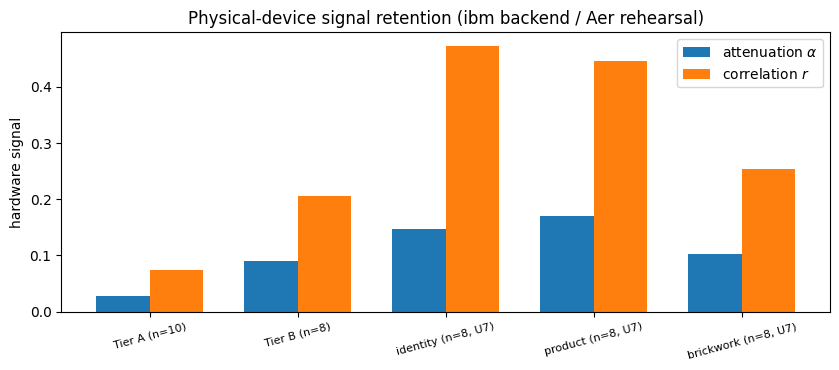

In [ ]:
if RUN_U8_QPU and QPU_MODE in ("ibm", "aer"):
    try:
        import numpy as _np
        from qiskit import QuantumCircuit
        from qiskit.circuit.library import UnitaryGate
        IS_QISKIT = True
    except ImportError:
        IS_QISKIT = False
        print("qiskit not installed; U8 skipped.")
else:
    IS_QISKIT = False

if IS_QISKIT:
    import matplotlib.pyplot as plt

    def _service8():
        from qiskit_ibm_runtime import QiskitRuntimeService
        tok = IBM_TOKEN or os.environ.get("IBM_QUANTUM_TOKEN", "")
        if tok:
            kw = dict(channel=IBM_CHANNEL, token=tok)
            if IBM_INSTANCE: kw["instance"] = IBM_INSTANCE
            return QiskitRuntimeService(**kw)
        return QiskitRuntimeService()

    def _jobs8():
        return _json.load(open(QPU_JOBS_FILE)) if os.path.exists(QPU_JOBS_FILE) else {}

    def circuits_for8(qobj, x):
        n = qobj.n
        psi = pn_normalize(x.unsqueeze(0))[0].numpy().astype(_np.complex128)
        psi = psi / _np.linalg.norm(psi)
        out = {}
        for basis in ("Z", "X", "Y"):
            qc = QuantumCircuit(n)
            qc.initialize(psi)
            for (q0, q1), Mg in qobj.gates:
                M64 = Mg.numpy().astype(_np.complex128)
                uu, _, vh = _np.linalg.svd(M64)
                qc.append(UnitaryGate(uu @ vh), [n - 1 - q1, n - 1 - q0])
            for q in range(n):
                if basis == "X": qc.h(q)
                elif basis == "Y": qc.sdg(q); qc.h(q)
            qc.measure_all()
            out[basis] = qc
        return out

    def counts_to_features8(qobj, cb):
        fs = []
        for basis in ("Z", "X", "Y"):
            p = torch.zeros(2 ** qobj.n)
            tot = sum(cb[basis].values())
            for bstr, c in cb[basis].items():
                p[int(bstr.replace(" ", ""), 2)] = c / tot
            fs.append(qobj.C @ p)
        return torch.cat(fs)

    def counts_for8(tag, build_flat):
        import time as _t
        if QPU_MODE == "aer":
            from qiskit_aer import AerSimulator
            job = AerSimulator().run(build_flat(), shots=QPU_SHOTS)
            counts = job.result().get_counts()
            if isinstance(counts, dict): counts = [counts]
            return counts, {"backend": "AerSimulator (local, noiseless)"}
        store = _jobs8()
        if tag not in store:
            from qiskit_ibm_runtime import SamplerV2
            from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
            service = _service8()
            circs = build_flat()
            backend = service.least_busy(operational=True, simulator=False,
                                         min_num_qubits=max(c.num_qubits
                                                            for c in circs))
            pm = generate_preset_pass_manager(optimization_level=3, backend=backend)
            isa = [pm.run(qc) for qc in circs]
            depths = [qc.depth() for qc in isa]
            twoq = [sum(1 for inst in qc.data
                        if inst.operation.num_qubits == 2) for qc in isa]
            sampler = SamplerV2(mode=backend)
            sampler.options.dynamical_decoupling.enable = True
            sampler.options.twirling.enable_measure = True
            job = sampler.run(isa, shots=QPU_SHOTS)
            store[tag] = {"job_id": job.job_id(), "backend": backend.name,
                          "shots": QPU_SHOTS, "n_circuits": len(isa),
                          "mitigation": "dynamical decoupling + measurement twirling",
                          "transpiled_depth_mean": float(_np.mean(depths)),
                          "transpiled_depth_max": int(max(depths)),
                          "transpiled_2q_mean": float(_np.mean(twoq)),
                          "transpiled_2q_max": int(max(twoq)),
                          "image_seeds": {"tierA": 11, "tierB": 12}}
            _json.dump(store, open(QPU_JOBS_FILE, "w"), indent=1)
            print(f"[U8 submit] {tag}: job {store[tag]['job_id']} on "
                  f"{store[tag]['backend']} | 2q mean "
                  f"{store[tag]['transpiled_2q_mean']:.0f} "
                  f"(max {store[tag]['transpiled_2q_max']})")
        rec = _jobs8()[tag]
        if rec.get("shots") is None:
            print(f"[U8] {tag}: record has no configuration metadata "
                  "(pre-metadata submission); treat as unverified.")
        elif rec["shots"] != QPU_SHOTS:
            raise RuntimeError(
                f"{tag}: stored job used shots={rec['shots']}, current "
                f"setting is {QPU_SHOTS}; delete the record to resubmit.")
        job = _service8().job(rec["job_id"])
        t0 = _t.time()
        while WAIT_FOR_JOBS:
            st = str(job.status()).upper()
            if "DONE" in st or "COMPLETED" in st: break
            if any(k in st for k in ("ERROR", "CANCEL", "FAIL")):
                raise RuntimeError(f"{tag}: job status {st}")
            if (_t.time() - t0) / 60 > QPU_WAIT_MAX_MIN:
                print(f"[U8] {tag} still {st}; rerun the notebook later to retrieve.")
                return None, rec
            log(f"U8 {tag}: {st}; polling in 60 s"); _t.sleep(60)
        result = job.result()
        try: rec["qpu_usage_seconds"] = job.usage()
        except Exception: rec["qpu_usage_seconds"] = "see dashboard"
        try:
            rec["execution_date"] = str(getattr(job, "creation_date", None))
        except Exception:
            rec["execution_date"] = "see dashboard"
        store = _jobs8(); store[tag] = rec
        _json.dump(store, open(QPU_JOBS_FILE, "w"), indent=1)
        return [r.data.meas.get_counts() for r in result], rec

    def signal(F_hw, F_ex):
        alpha = float((F_hw * F_ex).sum() / (F_ex * F_ex).sum())
        r = float(torch.corrcoef(torch.stack((F_hw.flatten(),
                                              F_ex.flatten())))[0, 1])
        return alpha, r

    # note: the per-class quota test below is inoperative (the or-branch
    # accepts any example until k are chosen), so this returns a seeded
    # uniform draw, not a stratified one; retained exactly as executed
    # for the recorded hardware jobs, which are reproducible from the seed
    def stratified_pick8(y, k, seed):
        g = torch.Generator().manual_seed(seed)
        order = torch.randperm(len(y), generator=g)
        chosen, seen = [], {}
        for i in order:
            c = int(y[i])
            if seen.get(c, 0) < max(1, k // len(set(y.tolist()))) or len(chosen) < k:
                if len(chosen) < k:
                    chosen.append(int(i)); seen[c] = seen.get(c, 0) + 1
            if len(chosen) == k: break
        return torch.tensor(chosen)

    HWFIG = {}

    # ---------------- Tier A: n=10 characterization (audited Brahmi) ----------------
    aB = AUD["Brahmi"]; n_classes = len(aB["classes"])
    qmbA = QuantumMushroomBody(depth=SEL["Brahmi"]["depth"], seed=QMB_SEED)
    XdevA, ydevA = augmented(aB["Xdev"], aB["ydev"], fn=AUG_FN["Brahmi"])
    Z1, Z2, muA, sdA = standardize(qmbA.features(XdevA), qmbA.features(aB["Xte"]))
    torch.manual_seed(SEED)
    headA = MBONHead(qmbA.n_features, n_classes)
    headA, _, accA_ex, _ = train_model(headA, Z1, ydevA, Z2, aB["yte"],
                                       n_classes, "U8/tierA-head")
    headA = headA.cpu().eval()
    del Z1, Z2; gc.collect()
    idxA = stratified_pick8(aB["yte"], QPU_A_IMAGES, seed=11)
    XA, yA = aB["Xte"][idxA], aB["yte"][idxA]
    f_exA = qmbA.features(XA)

    def _buildA():
        flat = []
        for i in range(len(idxA)):
            cs = circuits_for8(qmbA, XA[i])
            flat += [cs["Z"], cs["X"], cs["Y"]]
        return flat
    countsA, recA = counts_for8("u8_tierA_n10", _buildA)
    if countsA is not None:
        F_hw = torch.stack([counts_to_features8(
            qmbA, {b: countsA[3*i+j] for j, b in enumerate(("Z", "X", "Y"))})
            for i in range(len(idxA))])
        alphaA, rA = signal(F_hw, f_exA)
        mae = float((F_hw - f_exA).abs().mean())
        mx = float((F_hw - f_exA).abs().max())
        with torch.no_grad():
            p_id = headA((f_exA - muA) / sdA).argmax(1)
            p_hw = headA((F_hw - muA) / sdA).argmax(1)
            p_rs = headA((F_hw / max(alphaA, 1e-6) - muA) / sdA).argmax(1)
        agree = float((p_hw == p_id).float().mean())
        rec = {**recA, "feature_mae": mae, "feature_max": mx,
               "alpha": alphaA, "pearson_r": rA,
               "acc_hw": float((p_hw == yA).float().mean()),
               "acc_rescaled_oracle": float((p_rs == yA).float().mean()),
               "agreement": agree, "acc_ideal_exact": float((p_id == yA).float().mean()),
               "head_exact_acc_full_test": accA_ex}
        save_result("U8", "tierA_n10", rec)
        HWFIG["Tier A (n=10)"] = (alphaA, rA)
        print(f"[U8 Tier A] backend {recA['backend']} | images {len(idxA)} | "
              f"MAE {mae:.4f} (max {mx:.4f}; floor {1/math.sqrt(QPU_SHOTS):.4f}) | "
              f"alpha {alphaA:+.3f} | r {rA:+.3f} | agreement {agree:.3f}")

    # ---------------- Tier B: n=8 classification (audited Brahmi @16px) -------------
    d16 = build_dataset("Brahmi16q", DATA_ROOTS["Brahmi"], img_size=QPU_B_IMG_SIZE)
    # audit the 16px partitions with the U1 procedure
    h16tr = [arr_hash(d16["Xtr"][i]) for i in range(len(d16["ytr"]))]
    h16te = [arr_hash(d16["Xte"][j]) for j in range(len(d16["yte"]))]
    lab16 = {}
    for i, h in enumerate(h16tr): lab16.setdefault(h, set()).add(int(d16["ytr"][i]))
    for j, h in enumerate(h16te): lab16.setdefault(h, set()).add(int(d16["yte"][j]))
    confl16 = {h for h, L in lab16.items() if len(L) > 1}
    keep_tr, seen = [], set()
    for i, h in enumerate(h16tr):
        if h in confl16 or h in seen: continue
        seen.add(h); keep_tr.append(i)
    trh16 = {h16tr[i] for i in keep_tr}
    keep_te, seente = [], set()
    for j, h in enumerate(h16te):
        if h in confl16 or h in trh16 or h in seente: continue
        seente.add(h); keep_te.append(j)
    X16d, y16d = d16["Xtr"][keep_tr], d16["ytr"][keep_tr]
    X16t, y16t = d16["Xte"][keep_te], d16["yte"][keep_te]
    print(f"[U8 Tier B] audited 16px partitions: dev {len(y16d)} | test {len(y16t)}")

    n8 = int(math.log2(QPU_B_IMG_SIZE ** 2))
    qmb8 = QuantumMushroomBody(n_qubits=n8, depth=SEL["Brahmi"]["depth"],
                               seed=QMB_SEED)
    Xa16, ya16 = augmented(X16d, y16d, fn=AUG_FN["Brahmi"])
    Z1, Z2, mu8, sd8 = standardize(qmb8.features(Xa16), qmb8.features(X16t))
    torch.manual_seed(SEED)
    head8 = MBONHead(qmb8.n_features, len(d16["classes"]))
    head8, _, a8_ex, _ = train_model(head8, Z1, ya16, Z2, y16t,
                                     len(d16["classes"]), "U8/tierB-head")
    head8 = head8.cpu().eval()
    del Z1, Z2; gc.collect()
    print(f"[U8 Tier B] exact-feature reference accuracy @16px (audited): {a8_ex:.4f}")

    idxB = stratified_pick8(y16t, QPU_B_IMAGES, seed=12)
    XB, yB = X16t[idxB], y16t[idxB]
    genB = torch.Generator().manual_seed(2024)
    f_idshot = qmb8.features(XB, shots=QPU_SHOTS, gen=genB)
    with torch.no_grad():
        acc_idshot = float((head8((f_idshot - mu8) / sd8).argmax(1) == yB)
                           .float().mean())

    def _buildB():
        flat = []
        for i in range(len(idxB)):
            cs = circuits_for8(qmb8, XB[i])
            flat += [cs["Z"], cs["X"], cs["Y"]]
        return flat
    countsB, recB = counts_for8("u8_tierB_n8", _buildB)
    if countsB is not None:
        F_hw = torch.stack([counts_to_features8(
            qmb8, {b: countsB[3*i+j] for j, b in enumerate(("Z", "X", "Y"))})
            for i in range(len(idxB))])
        f_exB = qmb8.features(XB)
        alphaB, rB = signal(F_hw, f_exB)
        with torch.no_grad():
            p_id = head8((f_exB - mu8) / sd8).argmax(1)
            p_hw = head8((F_hw - mu8) / sd8).argmax(1)
            p_rs = head8((F_hw / max(alphaB, 1e-6) - mu8) / sd8).argmax(1)
        rec = {**recB, "alpha": alphaB, "pearson_r": rB,
               "acc_hw": float((p_hw == yB).float().mean()),
               "macro_f1_hw": macro_f1(yB, p_hw, len(d16["classes"])),
               "acc_rescaled_oracle": float((p_rs == yB).float().mean()),
               "agreement_exact": float((p_hw == p_id).float().mean()),
               "acc_ideal_shots": acc_idshot, "acc_exact_full_test": a8_ex,
               "shots_total": 3 * QPU_SHOTS * len(idxB)}
        save_result("U8", "tierB_n8", rec)
        HWFIG["Tier B (n=8)"] = (alphaB, rB)
        print(f"[U8 Tier B] backend {recB['backend']} | images {len(idxB)} | "
              f"acc hw {rec['acc_hw']:.3f} (rescaled, oracle: "
              f"{rec['acc_rescaled_oracle']:.3f}) | ideal-shot {acc_idshot:.3f} | "
              f"alpha {alphaB:+.3f} | r {rB:+.3f} | "
              f"shots total {rec['shots_total']:,}")

    # ---------------- hardware figure (U8 tiers + U7 families if present) ----------
    if "U7" in RESULTS:
        for fam, v in RESULTS["U7"].items():
            if isinstance(v, dict) and "alpha" in v:
                HWFIG[f"{fam} (n=8, U7)"] = (v["alpha"], v["pearson_r"])
    if HWFIG:
        labs = list(HWFIG.keys())
        al = [HWFIG[k][0] for k in labs]; rr = [HWFIG[k][1] for k in labs]
        xs = np.arange(len(labs))
        fig, ax = plt.subplots(figsize=(8.5, 3.8))
        ax.bar(xs - 0.18, al, 0.36, label="attenuation $\\alpha$")
        ax.bar(xs + 0.18, rr, 0.36, label="correlation $r$")
        ax.set_xticks(xs); ax.set_xticklabels(labs, rotation=15, fontsize=10)
        ax.axhline(0, color="k", lw=0.6)
        ax.set_ylabel("hardware signal"); ax.legend()
        ax.set_title("Hardware measurements against exact reference features")
        plt.tight_layout(); plt.savefig("fig_u_hardware.png", dpi=200)
        plt.show(); plt.close("all")


## The quantum circuit

Every executed circuit has the same shape: amplitude initialization of
the normalized image vector, the fixed feature layer as two-qubit
unitary blocks (none for the identity control, single-qubit blocks for
the product circuit), one measurement-basis rotation, and measurement
of all qubits. The cell below draws the Y-measurement branch at the
selected depth ($L=1$, five blocks) and at the preliminary reference
depth of the paper's circuit figure ($L=4$, 18 blocks).

In [15]:
# Y-measurement branch of the exported circuit: amplitude initialization,
# the fixed brickwork layer(s), the basis rotation, measurement. Drawn at
# the selected depth and at the preliminary reference depth (the paper's
# circuit figure, fig_circuit_n10). The drawing does not depend on the
# image, so a seeded placeholder amplitude vector stands in for a glyph.
try:
    from qiskit import QuantumCircuit
    from qiskit.circuit.library import UnitaryGate
    import numpy as _np

    rng = _np.random.default_rng(0)
    psi = rng.random(D_IN)
    psi = psi / _np.linalg.norm(psi)

    for depth, fname, label, fold in ((SEL["Brahmi"]["depth"],
                                       "fig_circuit_selected.png",
                                       "selected depth", -1),
                                      (4, "fig_circuit_n10.png",
                                       "preliminary reference (L=4)", 24)):
        _, gates = build_brickwork(N_QUBITS, depth, QMB_SEED)
        qc = QuantumCircuit(N_QUBITS)
        qc.initialize(psi.astype(_np.complex128))
        for (q0, q1), Mg in gates:
            M64 = Mg.numpy().astype(_np.complex128)
            uu, _, vh = _np.linalg.svd(M64)
            qc.append(UnitaryGate(uu @ vh),
                      [N_QUBITS - 1 - q1, N_QUBITS - 1 - q0])
        for q in range(N_QUBITS):
            qc.sdg(q); qc.h(q)
        qc.measure_all()
        print(f"L={depth} ({label}): ops {dict(qc.count_ops())} | "
              f"two-qubit unitary blocks "
              f"{sum(1 for inst in qc.data if inst.operation.num_qubits == 2)}")
        fig = qc.draw("mpl", fold=fold, idle_wires=False)
        fig.savefig(fname, dpi=200, bbox_inches="tight")
        plt.show()
except ImportError:
    print("qiskit not installed; circuit drawing skipped.")


L=1 (selected depth): ops {'sdg': 10, 'h': 10, 'measure': 10, 'unitary': 5, 'initialize': 1, 'barrier': 1} | two-qubit unitary blocks 5
L=4 (preliminary reference (L=4)): ops {'unitary': 18, 'sdg': 10, 'h': 10, 'measure': 10, 'initialize': 1, 'barrier': 1} | two-qubit unitary blocks 18


## U9: Summary and artifact inventory
Everything the paper cites from this notebook.

In [16]:
print("=" * 72)
print("PART 1 COMPLETE")
print("=" * 72)
print("""
Each section above prints its results in full:
  U1  audited partitions and the duplicate audit
  U2  depth and augmentation selection (L=1, cyclic, both datasets)
  U3  twelve-model comparison (accuracy, macro-F1, paired differences)
  U4  readout-family ablation
  U5  feature-space diagnostics
  U6  finite-shot study with the three predictors

Every section prints its results in full; the only files written are
the fig_u_*.png figures. The hardware sections (U7, U8) write
qpu_jobs_unified.json job records only when QPU_MODE is set to "ibm".""")


PART 1 COMPLETE

Each section above prints its results in full:
  U1  audited partitions and the duplicate audit
  U2  depth and augmentation selection (L=1, cyclic, both datasets)
  U3  twelve-model comparison (accuracy, macro-F1, paired differences)
  U4  readout-family ablation
  U5  feature-space diagnostics
  U6  finite-shot study with the three predictors

Every section prints its results in full; the only files written are
the fig_u_*.png figures. The hardware sections (U7, U8) write
qpu_jobs_unified.json job records only when QPU_MODE is set to "ibm".


## Part 2: numerical audit and additional experiments

Results from here on are collected in a separate store. The
partitions, selected depth, and augmentation carry over from part 1.

In [17]:
RUN_A1_COVERAGE = True
RUN_A2_RANK     = True
RUN_A3_AXES     = True
RUN_A4_PAIRED   = True
RUN_A5_ZONLY    = True
RUN_B1_IDENTITY = True             # masked identity, five-run replacement (U3 protocol)
RUN_B2_READOUT  = True             # masked identity, canonical readout families (U4)
RUN_B3_FIGURES  = True             # masked-identity main and readout figures
RUN_C_TUNED     = True             # validation-tuned baselines (hours; see cell)
C_DATASETS      = ["Modi", "Brahmi"]   # trim to ["Modi"] for a shorter first pass
RUN_D_SHOTMATCH = True             # single- vs three-setting readout at equal total shots
RUN_E_PREDREP   = True             # predictor replication across runs + small budgets
A3_AXIS_SEEDS   = [99, 199, 299]   # 99 reproduces the unified run's single draw

U_RESULTS = RESULTS            # part 1 results stay readable
RESULTS, DONE = {}, {}         # part 2 fills its own stores

for name in DATASETS:
    if "U2" in U_RESULTS and name in U_RESULTS["U2"]:
        SEL[name] = {"depth": U_RESULTS["U2"][name]["depth"],
                     "aug":   U_RESULTS["U2"][name]["aug"]}
AUG_FN = {name: (augment if SEL[name]["aug"] == "cyclic" else augment_padded)
          for name in DATASETS}
print("selected:", {k: v for k, v in SEL.items()})

selected: {'Brahmi': {'depth': 1, 'aug': 'cyclic'}, 'Modi': {'depth': 1, 'aug': 'cyclic'}}


## A1a: Removal flow and class coverage
Reconstructs the audit step by step with per-step image counts and reports
which classes the partitions actually cover.

In [18]:
if RUN_A1_COVERAGE:
    for name, d in DATA.items():
        key = f"A1flow/{name}"
        if key in DONE:
            flow, cover = DONE[key]["flow"], DONE[key]["coverage"]
            print(f"[A1a {name}] already done; flow: {flow}")
            save_result("A1", name, DONE[key]); continue
        htr = [arr_hash(d["Xtr"][i]) for i in range(len(d["ytr"]))]
        hte = [arr_hash(d["Xte"][i]) for i in range(len(d["yte"]))]
        groups = {}
        for i, h in enumerate(htr):
            groups.setdefault(h, {"train": [], "test": [], "labels": set()})
            groups[h]["train"].append(i); groups[h]["labels"].add(int(d["ytr"][i]))
        for j, h in enumerate(hte):
            groups.setdefault(h, {"train": [], "test": [], "labels": set()})
            groups[h]["test"].append(j); groups[h]["labels"].add(int(d["yte"][j]))
        conflict = {h for h, g in groups.items() if len(g["labels"]) > 1}
        tr_conf = sum(len(groups[h]["train"]) for h in conflict)
        te_conf = sum(len(groups[h]["test"])  for h in conflict)
        keep_tr, seen = [], set()
        for i, h in enumerate(htr):
            if h in conflict or h in seen: continue
            seen.add(h); keep_tr.append(i)
        tr_dup = len(htr) - tr_conf - len(keep_tr)
        tr_hashes = {htr[i] for i in keep_tr}
        keep_te, seen_te, te_cross, te_dup = [], set(), 0, 0
        for j, h in enumerate(hte):
            if h in conflict: continue
            if h in tr_hashes: te_cross += 1; continue
            if h in seen_te:  te_dup += 1; continue
            seen_te.add(h); keep_te.append(j)
        flow = {"train_raw": len(htr), "train_conflict_removed": tr_conf,
                "train_duplicate_removed": tr_dup, "train_kept": len(keep_tr),
                "test_raw": len(hte), "test_conflict_removed": te_conf,
                "test_train_identical_removed": te_cross,
                "test_duplicate_removed": te_dup, "test_kept": len(keep_te)}
        print(f"[A1a {name}] removal flow:")
        for k, v in flow.items(): print(f"    {k:<32s} {v}")
        a = AUD[name]; C = len(a["classes"])
        cover = {}
        for part, y in (("train", a["ytr"]), ("val", a["yva"]), ("test", a["yte"])):
            cnt = np.bincount(y.numpy(), minlength=C)
            nz = int((cnt > 0).sum()); pos = cnt[cnt > 0]
            cover[part] = {"classes_present": nz, "classes_absent": C - nz,
                           "min_support": int(pos.min()),
                           "median_support": float(np.median(pos)),
                           "max_support": int(pos.max())}
            print(f"[A1a {name}] {part:<5s}: {nz}/{C} classes present | per-class "
                  f"support min {int(pos.min())} / median {np.median(pos):.0f} / "
                  f"max {int(pos.max())}"
                  + (f" | ABSENT: {C-nz} classes" if nz < C else ""))
        rec = {"flow": flow, "coverage": cover}
        mark(key, rec); save_result("A1", name, rec)
        del htr, hte, groups; gc.collect()

[A1a Brahmi] removal flow:
    train_raw                        4250
    train_conflict_removed           86
    train_duplicate_removed          264
    train_kept                       3900
    test_raw                         850
    test_conflict_removed            31
    test_train_identical_removed     305
    test_duplicate_removed           2
    test_kept                        512
[A1a Brahmi] train: 170/170 classes present | per-class support min 3 / median 23 / max 23
[A1a Brahmi] val  : 170/170 classes present | per-class support min 1 / median 2 / max 2
[A1a Brahmi] test : 109/170 classes present | per-class support min 2 / median 5 / max 5 | ABSENT: 61 classes
[A1a Modi] removal flow:
    train_raw                        2800
    train_conflict_removed           0
    train_duplicate_removed          1
    train_kept                       2799
    test_raw                         700
    test_conflict_removed            0
    test_train_identical_removed     0
    test_d

## A1b: Support-restricted macro-F1 from the saved predictions
One `bincount` pass per model and run, no per-class loops.

In [19]:
if RUN_A1_COVERAGE and "P_U3" in globals():
    P = P_U3

    def f1_per_class(y, pred, C):
        tp = np.bincount(y[pred == y], minlength=C).astype(float)
        pc = np.bincount(pred, minlength=C).astype(float)
        tc = np.bincount(y, minlength=C).astype(float)
        prec = np.divide(tp, pc, out=np.zeros(C), where=pc > 0)
        rec  = np.divide(tp, tc, out=np.zeros(C), where=tc > 0)
        return np.divide(2 * prec * rec, prec + rec,
                         out=np.zeros(C), where=(prec + rec) > 0)

    for name, a in AUD.items():
        yte = np.asarray(P[f"ytest/{name}"])
        C = len(a["classes"])
        sup = np.bincount(yte, minlength=C) > 0
        labs = sorted({k.split("/")[1] for k in P.keys()
                       if k.startswith(f"{name}/")})
        print(f"\n[A1b {name}] macro-F1 over the {int(sup.sum())} classes with "
              f"positive audited test support (vs full-inventory over {C}):")
        rows = {}
        for lab in labs:
            key = f"A1f1/{name}/{lab}"
            if key in DONE:
                rows[lab] = DONE[key]
            else:
                fs_sup, fs_full = [], []
                for r in range(N_RUNS):
                    pred = np.asarray(P[f"{name}/{lab}/r{r}"])
                    f1 = f1_per_class(yte, pred, C)
                    fs_sup.append(float(f1[sup].mean()))
                    fs_full.append(float(f1.mean()))
                ms, ss = msd(fs_sup); mf, sf = msd(fs_full)
                rows[lab] = {"support_restricted": [ms, ss],
                             "full_inventory": [mf, sf]}
                mark(key, rows[lab])
            sr, fi = rows[lab]["support_restricted"], rows[lab]["full_inventory"]
            print(f"    {lab:<26s} support-restricted {sr[0]:.4f} ± {sr[1]:.4f}"
                  f" | full-inventory {fi[0]:.4f} ± {fi[1]:.4f}")
        save_result("A1_macroF1", name, rows)
elif RUN_A1_COVERAGE:
    print("U3 predictions not in memory; run the U3 cell first.")


[A1b Brahmi] macro-F1 over the 109 classes with positive audited test support (vs full-inventory over 170):
    CNN (small)                support-restricted 0.9880 ± 0.0048 | full-inventory 0.6335 ± 0.0031
    FlyMB-525                  support-restricted 0.9206 ± 0.0104 | full-inventory 0.5903 ± 0.0067
    HOG + linear head          support-restricted 0.9733 ± 0.0027 | full-inventory 0.6240 ± 0.0018
    Identity (L=0)             support-restricted 0.9490 ± 0.0069 | full-inventory 0.6085 ± 0.0044
    Nystrom RBF                support-restricted 0.9647 ± 0.0055 | full-inventory 0.6185 ± 0.0035
    Nystrom poly-2             support-restricted 0.9632 ± 0.0055 | full-inventory 0.6176 ± 0.0035
    Product U(2)               support-restricted 0.9754 ± 0.0067 | full-inventory 0.6254 ± 0.0043
    QMB                        support-restricted 0.9777 ± 0.0091 | full-inventory 0.6269 ± 0.0058
    QMB+KD                     support-restricted 0.9757 ± 0.0066 | full-inventory 0.6256 ± 0.0042


## A2: Identity-rank recomputation with the odd-$Y$ coordinates masked
For real amplitude vectors, the 130 odd-weight same-axis $Y$ parities of the
identity circuit are exactly zero, so the exact identity feature matrix has at
most 395 nonzero columns and rank at most 395. The unified run's spectra were
computed on standardized features whose $10^{-8}$ offset amplifies those
numerically-zero columns into order-one noise. This cell recomputes the
spectra on raw and standardized features with and without masking (same SVD
routine as U5), checks whether identity-model predictions change under
masking, and draws the rank figure (`fig_a_rank_masked.png`).

[A2 Brahmi] identity       raw r99 176 | masked-raw r99 176 | masked-std r99 250 | columns 395
[A2 Brahmi] product        raw r99 249 | masked-raw r99 249 | masked-std r99 301 | columns 525
[A2 Brahmi] QMB L=1        raw r99 316 | masked-raw r99 316 | masked-std r99 357 | columns 525
[A2 Brahmi] RandQuad-525   raw r99 491 | masked-raw r99 491 | masked-std r99 491 | columns 525
[A2 Brahmi] identity head: unmasked 0.9473 | masked 0.9707 | prediction agreement 0.9766
[A2 Modi] identity       raw r99 262 | masked-raw r99 262 | masked-std r99 291 | columns 395
[A2 Modi] product        raw r99 355 | masked-raw r99 355 | masked-std r99 389 | columns 525
[A2 Modi] QMB L=1        raw r99 417 | masked-raw r99 417 | masked-std r99 430 | columns 525
[A2 Modi] RandQuad-525   raw r99 511 | masked-raw r99 511 | masked-std r99 511 | columns 525
[A2 Modi] identity head: unmasked 0.3243 | masked 0.3543 | prediction agreement 0.6829


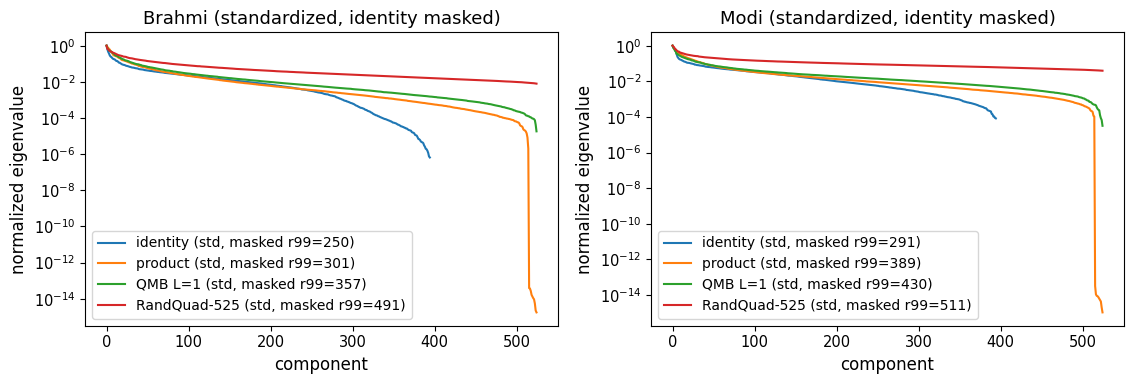

In [20]:
if RUN_A2_RANK:
    import matplotlib.pyplot as plt
    sub_w3 = subsets_by_weight(N_QUBITS, 3); n_sub = len(sub_w3)
    odd_y = torch.tensor([2 * n_sub + j for j, S in enumerate(sub_w3)
                          if len(S) % 2 == 1])
    keep_mask = torch.ones(N_FEAT, dtype=torch.bool); keep_mask[odd_y] = False

    def spectrum_r99(F):
        # same float32 SVD routine as U5:
        # singular values of the centered matrix in float32
        Z = F - F.mean(0)
        ev = torch.linalg.svdvals(Z / math.sqrt(len(Z))) ** 2
        del Z; gc.collect()
        energy = torch.cumsum(ev, 0) / ev.sum()
        return ev, int((energy < 0.99).sum()) + 1

    MAP_LABS = {}
    for name, a in AUD.items():
        MAP_LABS[name] = ["identity", "product",
                          f"QMB L={SEL[name]['depth']}", "RandQuad-525"]
        n_classes = len(a["classes"]); yte = a["yte"]
        Xdev_a = ydev_a = None   # built lazily only if something is missing

        def need_dev():
            global Xdev_a, ydev_a
            if Xdev_a is None:
                Xdev_a, ydev_a = augmented(a["Xdev"], a["ydev"], fn=AUG_FN[name])
            return Xdev_a, ydev_a

        def make_map(lab):
            if lab == "identity": return QuantumMushroomBody(depth=0)
            if lab == "product":  return product_circuit_mb(seed=QMB_SEED)
            if lab.startswith("QMB"):
                return QuantumMushroomBody(depth=SEL[name]["depth"], seed=QMB_SEED)
            return RandomQuadraticFeatures(D_IN)

        for lab in MAP_LABS[name]:
            key = f"A2spec/{name}/{lab}"
            if key in DONE:
                print(f"[A2 {name}] {lab:<14s} already done; "
                      f"masked-std r99 {DONE[key]['r99_std_masked']}")
                continue
            Xd, _ = need_dev()
            fx = make_map(lab)
            Fraw = fx.features(Xd)
            is_id = lab == "identity"
            Fm = Fraw[:, keep_mask] if is_id else Fraw
            _, r99_raw = spectrum_r99(Fraw)
            if is_id:
                _, r99_rawmask = spectrum_r99(Fm)
            else:
                r99_rawmask = r99_raw
            sdv = Fm.std(0)
            Zs = (Fm - Fm.mean(0)) / (sdv + 1e-8)
            ev_s, r99_stdmask = spectrum_r99(Zs)
            rec = {"r99_raw": r99_raw, "r99_raw_masked": r99_rawmask,
                   "r99_std_masked": r99_stdmask, "n_cols": int(Fm.shape[1]),
                   "spectrum_std": (ev_s / ev_s[0]).tolist()}
            if is_id:
                assert r99_rawmask <= 395 and r99_stdmask <= 395
            mark(key, rec); save_result("A2", f"{name}/{lab}",
                                        {k: v for k, v in rec.items()
                                         if k != "spectrum_std"})
            print(f"[A2 {name}] {lab:<14s} raw r99 {r99_raw:>3d} | "
                  f"masked-raw r99 {r99_rawmask:>3d} | "
                  f"masked-std r99 {r99_stdmask:>3d} | columns {Fm.shape[1]}")
            del Fraw, Fm, Zs, ev_s, fx; gc.collect()

        # ---- identity prediction check: masked vs unmasked standardized ----
        key = f"A2pred/{name}"
        if key in DONE:
            chk = DONE[key]
        else:
            Xd, yd = need_dev()
            fx = QuantumMushroomBody(depth=0)
            F1r, F2r = fx.features(Xd), fx.features(a["Xte"])
            accs, preds = {}, {}
            for tag, km in (("unmasked", None), ("masked", keep_mask)):
                A1_ = F1r if km is None else F1r[:, km]
                A2_ = F2r if km is None else F2r[:, km]
                Z1, Z2, _, _ = standardize(A1_, A2_)
                torch.manual_seed(SEED)
                h = MBONHead(Z1.shape[1], n_classes)
                _, pr, acc, _ = train_model(h, Z1, yd, Z2, yte, n_classes,
                                            f"A2 {name} {tag}")
                accs[tag] = acc; preds[tag] = pr
                del h, Z1, Z2, A1_, A2_; gc.collect()
            agree = float((preds["masked"] == preds["unmasked"]).float().mean())
            chk = {"acc_unmasked": accs["unmasked"], "acc_masked": accs["masked"],
                   "prediction_agreement": agree}
            mark(key, chk); del F1r, F2r, fx; gc.collect()
        print(f"[A2 {name}] identity head: unmasked {chk['acc_unmasked']:.4f} | "
              f"masked {chk['acc_masked']:.4f} | prediction agreement "
              f"{chk['prediction_agreement']:.4f}")
        save_result("A2_predcheck", name, chk)
        Xdev_a = ydev_a = None; gc.collect()

    # ---- rank figure from the computed spectra ----
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
    for ax, name in zip(axes, AUD):
        for lab in MAP_LABS[name]:
            rec = DONE.get(f"A2spec/{name}/{lab}")
            if rec is None: continue
            ax.semilogy(rec["spectrum_std"],
                        label=f"{lab} (std, masked r99={rec['r99_std_masked']})")
        ax.set_xlabel("component"); ax.set_ylabel("normalized eigenvalue")
        ax.set_title(f"{name} (standardized, identity masked)")
        ax.legend(fontsize=10)
    plt.tight_layout(); plt.savefig("fig_a_rank_masked.png", dpi=200)
    plt.show(); plt.close("all")

## A3: Random-measurement-axis replication
The unified run evaluated a single draw of three Haar-random product
measurement bases (generator seed 99). This cell replicates that family over
three independent axis seeds, for the identity, product, and selected-depth
brickwork circuits on both datasets (three head seeds each), so that the
random-basis comparison carries uncertainty over the measurement axes rather
than only over head initialization.

In [21]:
if RUN_A3_AXES:
    sub_w3 = subsets_by_weight(N_QUBITS, 3); m_w3 = masks_of(sub_w3)
    A3 = {}
    for name, a in AUD.items():
        n_classes = len(a["classes"])
        Xdev_a, ydev_a = augmented(a["Xdev"], a["ydev"], fn=AUG_FN[name])
        circuits = {"identity": torch.eye(D_IN, dtype=torch.complex64),
                    "product":  product_circuit_mb(seed=QMB_SEED).U,
                    f"QMB L={SEL[name]['depth']}":
                        QuantumMushroomBody(depth=SEL[name]["depth"],
                                            seed=QMB_SEED).U}
        res = {}
        for ax_seed in A3_AXIS_SEEDS:
            g_ax = torch.Generator().manual_seed(ax_seed)
            settings = [[random_axis_rotation(g_ax) for _ in range(N_QUBITS)]
                        for _ in range(3)]
            for cl, Uc in circuits.items():
                key = f"A3/{name}/{cl}/axes{ax_seed}"
                if key in DONE:
                    res[(cl, ax_seed)] = tuple(DONE[key]); continue
                ro = GeneralReadout(Uc, settings, [m_w3, m_w3, m_w3])
                Z1, Z2, _, _ = standardize(ro.features(Xdev_a),
                                           ro.features(a["Xte"]))
                accs = []
                for s in C_SEEDS:
                    torch.manual_seed(s)
                    h = MBONHead(ro.n_features, n_classes)
                    _, _, acc, _ = train_model(h, Z1, ydev_a, Z2, a["yte"],
                                               n_classes, key)
                    accs.append(acc); del h
                del ro, Z1, Z2; gc.collect()
                res[(cl, ax_seed)] = msd(accs)
                mark(key, list(res[(cl, ax_seed)]))
                log(f"A3 {name} {cl} axes{ax_seed}: {res[(cl, ax_seed)][0]:.4f}")
        A3[name] = res
        print(f"\n[A3 {name}] random-axis replication "
              f"(mean \u00b1 sd over {len(C_SEEDS)} head seeds):")
        print("    " + " | ".join([f"{'circuit':<12s}"] +
                                  [f"axes seed {sd:<16d}" for sd in A3_AXIS_SEEDS] +
                                  ["across-seed mean \u00b1 sd"]))
        for cl in circuits:
            means = [res[(cl, sd)][0] for sd in A3_AXIS_SEEDS]
            m_, s_ = msd(means)
            row = [f"{cl:<12s}"] + [f"{res[(cl, sd)][0]:.4f} \u00b1 {res[(cl, sd)][1]:.4f}  "
                                    for sd in A3_AXIS_SEEDS] + [f"{m_:.4f} \u00b1 {s_:.4f}"]
            print("    " + " | ".join(row))
        save_result("A3", name, {f"{cl}|axes{sd}": list(v)
                                 for (cl, sd), v in res.items()})

[22:41:51] A3 Brahmi identity axes99: 0.9733
[22:43:07] A3 Brahmi product axes99: 0.9811
[22:44:04] A3 Brahmi QMB L=1 axes99: 0.9785
[22:45:02] A3 Brahmi identity axes199: 0.9798
[22:45:56] A3 Brahmi product axes199: 0.9779
[22:46:52] A3 Brahmi QMB L=1 axes199: 0.9824
[22:47:46] A3 Brahmi identity axes299: 0.9805
[22:49:21] A3 Brahmi product axes299: 0.9772
[22:51:23] A3 Brahmi QMB L=1 axes299: 0.9746

[A3 Brahmi] random-axis replication (mean ± sd over 3 head seeds):
    circuit      | axes seed 99               | axes seed 199              | axes seed 299              | across-seed mean ± sd
    identity     | 0.9733 ± 0.0041   | 0.9798 ± 0.0049   | 0.9805 ± 0.0034   | 0.9779 ± 0.0040
    product      | 0.9811 ± 0.0023   | 0.9779 ± 0.0045   | 0.9772 ± 0.0060   | 0.9787 ± 0.0021
    QMB L=1      | 0.9785 ± 0.0020   | 0.9824 ± 0.0020   | 0.9746 ± 0.0020   | 0.9785 ± 0.0039
[22:52:15] A3 Modi identity axes99: 0.3586
[22:53:06] A3 Modi product axes99: 0.3719
[22:54:01] A3 Modi QMB L=1 ax

## A4: Paired baseline statistics from the saved predictions
Per-run paired accuracy differences on identical test images, with exact
two-sided sign-flip $p$-values ($2^5=32$ sign assignments; the smallest
attainable two-sided value at $n=5$ is $1/16=0.0625$).

In [22]:
if RUN_A4_PAIRED and "P_U3" in globals():
    P = P_U3
    def exact_signflip_p(diffs):
        d = np.asarray(diffs, dtype=float); T = abs(d.sum()); cnt = 0
        from itertools import product as _prod
        for signs in _prod([-1, 1], repeat=len(d)):
            if abs((d * np.array(signs)).sum()) >= T - 1e-12: cnt += 1
        return cnt / 2 ** len(d)
    PAIRS = [("Product U(2)", "HOG + linear head"),
             ("QMB", "RandQuad-525"),
             ("CNN (small)", "QMB"),
             ("Product U(2)", "QMB")]
    for name in AUD:
        yte = np.array(P[f"ytest/{name}"])
        print(f"\n[A4 {name}] paired per-run accuracy differences (A minus B):")
        out = {}
        for A, B in PAIRS:
            try:
                dif = [float((P[f"{name}/{A}/r{r}"] == yte).mean()
                             - (P[f"{name}/{B}/r{r}"] == yte).mean())
                       for r in range(N_RUNS)]
            except KeyError:
                print(f"    {A} vs {B}: predictions missing"); continue
            m_, s_ = msd(dif); p_ = exact_signflip_p(dif)
            pos = sum(x > 0 for x in dif)
            out[f"{A} - {B}"] = {"per_run": dif, "mean": m_, "sd": s_,
                                 "positive_runs": pos, "signflip_p": p_}
            print(f"    {A:<14s} - {B:<22s}: {m_:+.4f} \u00b1 {s_:.4f} | "
                  f"positive {pos}/5 | exact p {p_:.4f} | per-run "
                  + " ".join(f"{x:+.4f}" for x in dif))
        save_result("A4", name, out)
elif RUN_A4_PAIRED:
    print("U3 predictions not in memory; run the U3 cell first.")


[A4 Brahmi] paired per-run accuracy differences (A minus B):
    Product U(2)   - HOG + linear head     : +0.0027 ± 0.0055 | positive 2/5 | exact p 0.5000 | per-run +0.0000 +0.0117 -0.0020 +0.0000 +0.0039
    QMB            - RandQuad-525          : +0.0094 ± 0.0090 | positive 4/5 | exact p 0.1250 | per-run +0.0098 +0.0215 +0.0137 +0.0039 -0.0020
    CNN (small)    - QMB                   : +0.0074 ± 0.0106 | positive 4/5 | exact p 0.2500 | per-run +0.0039 -0.0078 +0.0059 +0.0176 +0.0176
    Product U(2)   - QMB                   : -0.0035 ± 0.0077 | positive 1/5 | exact p 0.4375 | per-run -0.0039 -0.0059 -0.0137 -0.0020 +0.0078

[A4 Modi] paired per-run accuracy differences (A minus B):
    Product U(2)   - HOG + linear head     : +0.0191 ± 0.0099 | positive 5/5 | exact p 0.0625 | per-run +0.0157 +0.0257 +0.0129 +0.0086 +0.0329
    QMB            - RandQuad-525          : +0.1523 ± 0.0151 | positive 5/5 | exact p 0.0625 | per-run +0.1329 +0.1543 +0.1543 +0.1457 +0.1743
    CNN (small

## A5: Composition of the Z-only 525 family
The matched-count single-setting family takes the 525 lowest-weight
$Z$-parities in weight order, ties broken lexicographically; since
$\sum_{r=1}^{4}\binom{10}{r}=385$, it necessarily includes 140 weight-5
parities. This cell prints the exact weight histogram and the boundary
strings so the family is fully specified.

In [23]:
if RUN_A5_ZONLY:
    sub_all = subsets_by_weight(N_QUBITS, N_QUBITS)
    fam = sub_all[:N_FEAT]
    from collections import Counter
    hist = Counter(len(S) for S in fam)
    print(f"[A5] Z-only family of {len(fam)} parities, weight histogram: "
          f"{dict(sorted(hist.items()))}")
    w5 = [S for S in fam if len(S) == 5]
    print(f"[A5] weight-5 members: {len(w5)} of {math.comb(N_QUBITS,5)} "
          f"(lexicographic order)")
    print(f"[A5] first included w5: {w5[0]} ... last included w5: {w5[-1]}")
    nxt = [S for S in sub_all if len(S) == 5][len(w5)]
    print(f"[A5] first EXCLUDED  w5: {nxt}")
    save_result("A5", "zonly", {"weight_histogram": dict(sorted(hist.items())),
                                "last_included_w5": list(w5[-1]),
                                "first_excluded_w5": list(nxt)})

[A5] Z-only family of 525 parities, weight histogram: {1: 10, 2: 45, 3: 120, 4: 210, 5: 140}
[A5] weight-5 members: 140 of 252 (lexicographic order)
[A5] first included w5: (0, 1, 2, 3, 4) ... last included w5: (1, 2, 3, 7, 9)
[A5] first EXCLUDED  w5: (1, 2, 3, 8, 9)


## B1: Masked identity baseline, five-run replacement
Reruns the identity circuit in the exact U3 protocol (head seeds $42{+}r$;
the identity map has no feature-map seed) with the 130 identically-zero
odd-$Y$ coordinates removed before standardization. Reports accuracy, both
macro-F1 conventions, and paired per-run differences against the saved QMB,
product, RandQuad, and original-identity predictions.

In [24]:
if RUN_B1_IDENTITY:
    sub_w3 = subsets_by_weight(N_QUBITS, 3); n_sub = len(sub_w3)
    odd_y = torch.tensor([2 * n_sub + j for j, S in enumerate(sub_w3)
                          if len(S) % 2 == 1])
    keep_mask = torch.ones(N_FEAT, dtype=torch.bool); keep_mask[odd_y] = False

    def f1_vec(y, pred, C):
        tp = np.bincount(y[pred == y], minlength=C).astype(float)
        pc = np.bincount(pred, minlength=C).astype(float)
        tc = np.bincount(y, minlength=C).astype(float)
        prec = np.divide(tp, pc, out=np.zeros(C), where=pc > 0)
        rec  = np.divide(tp, tc, out=np.zeros(C), where=tc > 0)
        return np.divide(2 * prec * rec, prec + rec,
                         out=np.zeros(C), where=(prec + rec) > 0)

    HAVE_P = "P_U3" in globals()
    P = P_U3 if HAVE_P else None
    B1_PREDS = {}
    for name, a in AUD.items():
        n_classes = len(a["classes"]); yte = a["yte"]
        Xdev_a, ydev_a = augmented(a["Xdev"], a["ydev"], fn=AUG_FN[name])
        fx = QuantumMushroomBody(depth=0)
        Z1, Z2, _, _ = standardize(fx.features(Xdev_a)[:, keep_mask],
                                   fx.features(a["Xte"])[:, keep_mask])
        del Xdev_a; gc.collect()
        accs, f1s, preds_all = [], [], []
        for r in range(N_RUNS):
            key = f"B1/{name}/r{r}"
            if key in DONE:
                acc, f1, pl = DONE[key]; preds = torch.tensor(pl)
            else:
                torch.manual_seed(SEED + r)
                h = MBONHead(Z1.shape[1], n_classes)
                _, preds, acc, f1 = train_model(h, Z1, ydev_a, Z2, yte,
                                                n_classes, key)
                mark(key, (acc, f1, preds.tolist())); del h; gc.collect()
                log(f"B1 {name} r{r}: acc {acc:.4f}")
            accs.append(acc); f1s.append(f1); preds_all.append(preds)
            B1_PREDS[f"{name}/Identity-masked/r{r}"] = preds.numpy()
        del Z1, Z2; gc.collect()
        ma, sa = msd(accs); mf, sf = msd(f1s)
        supC = np.bincount(yte.numpy(), minlength=n_classes) > 0
        fs_sup = [float(f1_vec(yte.numpy(), pr.numpy(), n_classes)[supC].mean())
                  for pr in preds_all]
        msup, ssup = msd(fs_sup)
        out = {"acc": accs, "acc_mean_sd": [ma, sa],
               "f1_full_mean_sd": [mf, sf],
               "f1_support_mean_sd": [msup, ssup]}
        print(f"\n[B1 {name}] identity, masked, five head seeds:")
        print(f"    accuracy {ma:.4f} ± {sa:.4f} | full-inventory F1 "
              f"{mf:.4f} ± {sf:.4f} | support-restricted F1 "
              f"{msup:.4f} ± {ssup:.4f}")
        if HAVE_P:
            yte_np = np.asarray(P[f"ytest/{name}"])
            for other in ("QMB", "Product U(2)", "RandQuad-525",
                          "Identity (L=0)"):
                try:
                    dif = [float((preds_all[r].numpy() == yte_np).mean()
                                 - (np.asarray(P[f"{name}/{other}/r{r}"])
                                    == yte_np).mean())
                           for r in range(N_RUNS)]
                except KeyError:
                    continue
                md_, sd_ = msd(dif)
                out[f"paired_vs_{other}"] = {
                    "per_run": dif, "mean": md_, "sd": sd_,
                    "positive_runs": int(sum(x > 0 for x in dif))}
                print(f"    paired vs {other:<16s}: {md_:+.4f} ± "
                      f"{sd_:.4f} | positive "
                      f"{sum(x > 0 for x in dif)}/{N_RUNS} | per-run "
                      + " ".join(f"{x:+.4f}" for x in dif))
        save_result("B1", name, out)
    pass

[22:57:35] B1 Brahmi r0: acc 0.9707
[22:57:52] B1 Brahmi r1: acc 0.9668
[22:58:10] B1 Brahmi r2: acc 0.9629
[22:58:29] B1 Brahmi r3: acc 0.9590
[22:58:47] B1 Brahmi r4: acc 0.9688

[B1 Brahmi] identity, masked, five head seeds:
    accuracy 0.9656 ± 0.0047 | full-inventory F1 0.6169 ± 0.0035 | support-restricted F1 0.9622 ± 0.0055
    paired vs QMB             : -0.0141 ± 0.0076 | positive 0/5 | per-run -0.0098 -0.0215 -0.0215 -0.0137 -0.0039
    paired vs Product U(2)    : -0.0105 ± 0.0038 | positive 0/5 | per-run -0.0059 -0.0156 -0.0078 -0.0117 -0.0117
    paired vs RandQuad-525    : -0.0047 ± 0.0045 | positive 0/5 | per-run +0.0000 +0.0000 -0.0078 -0.0098 -0.0059
    paired vs Identity (L=0)  : +0.0102 ± 0.0108 | positive 4/5 | per-run +0.0234 +0.0039 +0.0098 -0.0039 +0.0176
[22:59:00] B1 Modi r0: acc 0.3543
[22:59:09] B1 Modi r1: acc 0.3543
[22:59:19] B1 Modi r2: acc 0.3586
[22:59:28] B1 Modi r3: acc 0.3443
[22:59:37] B1 Modi r4: acc 0.3500

[B1 Modi] identity, masked, five head se

## B2: Masked identity under the canonical readout families
The weight-one and weight-up-to-two canonical families also contain
identically-zero odd-$Y$ coordinates for the identity circuit (10 of 30 and
10 of 165 respectively; the $Z$-only and random-axis families contain none).
This cell reruns the identity row of the readout ablation with each family's
own degenerate coordinates masked (three head seeds, as in U4).

In [25]:
if RUN_B2_READOUT:
    XYZ = [[H_1] * N_QUBITS, [HSd] * N_QUBITS]
    fam_subs = {"XYZ w<=3 (525)": subsets_by_weight(N_QUBITS, 3),
                "XYZ w<=2 (165)": subsets_by_weight(N_QUBITS, 2),
                "XYZ w=1 (30)":  subsets_by_weight(N_QUBITS, 1)}
    B2 = {}
    for name, a in AUD.items():
        n_classes = len(a["classes"]); yte = a["yte"]
        Xdev_a, ydev_a = augmented(a["Xdev"], a["ydev"], fn=AUG_FN[name])
        Uc = torch.eye(D_IN, dtype=torch.complex64)
        for fl, subs in fam_subs.items():
            key = f"B2/{name}/{fl}"
            if key in DONE:
                B2[(name, fl)] = tuple(DONE[key]); continue
            m = masks_of(subs); nsub = len(subs)
            oy = torch.tensor([2 * nsub + j for j, S in enumerate(subs)
                               if len(S) % 2 == 1])
            km = torch.ones(3 * nsub, dtype=torch.bool); km[oy] = False
            ro = GeneralReadout(Uc, [None] + XYZ, [m, m, m])
            Z1, Z2, _, _ = standardize(ro.features(Xdev_a)[:, km],
                                       ro.features(a["Xte"])[:, km])
            accs = []
            for s in C_SEEDS:
                torch.manual_seed(s)
                h = MBONHead(Z1.shape[1], n_classes)
                _, _, acc, _ = train_model(h, Z1, ydev_a, Z2, yte,
                                           n_classes, key)
                accs.append(acc); del h
            del ro, Z1, Z2; gc.collect()
            B2[(name, fl)] = msd(accs); mark(key, list(B2[(name, fl)]))
            log(f"B2 {name} identity/{fl} masked: {B2[(name, fl)][0]:.4f}")
        del Xdev_a; gc.collect()
        print(f"\n[B2 {name}] identity row, degenerate coordinates masked "
              f"(mean ± sd, 3 head seeds):")
        for fl in fam_subs:
            m_, s_ = B2[(name, fl)]
            print(f"    {fl:<18s} {m_:.4f} ± {s_:.4f}")
        save_result("B2", name, {fl: list(B2[(name, fl)]) for fl in fam_subs})

[23:00:32] B2 Brahmi identity/XYZ w<=3 (525) masked: 0.9668
[23:01:29] B2 Brahmi identity/XYZ w<=2 (165) masked: 0.9681
[23:02:22] B2 Brahmi identity/XYZ w=1 (30) masked: 0.8314

[B2 Brahmi] identity row, degenerate coordinates masked (mean ± sd, 3 head seeds):
    XYZ w<=3 (525)     0.9668 ± 0.0039
    XYZ w<=2 (165)     0.9681 ± 0.0030
    XYZ w=1 (30)       0.8314 ± 0.0023
[23:03:08] B2 Modi identity/XYZ w<=3 (525) masked: 0.3557
[23:03:39] B2 Modi identity/XYZ w<=2 (165) masked: 0.3462
[23:04:03] B2 Modi identity/XYZ w=1 (30) masked: 0.1471

[B2 Modi] identity row, degenerate coordinates masked (mean ± sd, 3 head seeds):
    XYZ w<=3 (525)     0.3557 ± 0.0025
    XYZ w<=2 (165)     0.3462 ± 0.0030
    XYZ w=1 (30)       0.1471 ± 0.0000


## B3: Primary figures with the masked identity baseline
Redraws the twelve-model comparison and the readout-ablation figure from the
unified run's saved results with the masked identity entries
substituted, and prints the masked canonical identity against the
random-axis identity replication of A3.

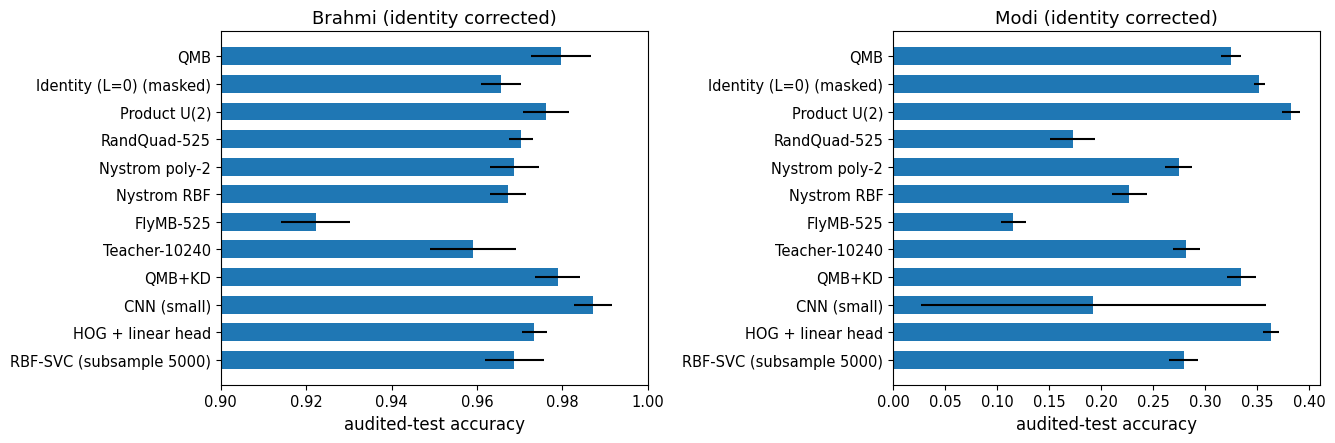

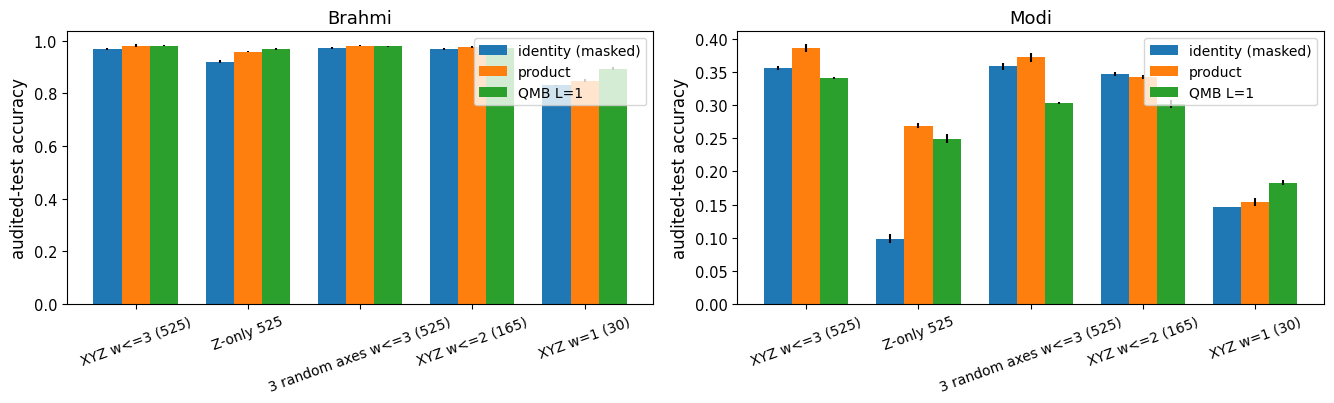

[B3 Brahmi] masked canonical identity 0.9668 ± 0.0039 | random-axis identity across draws 0.9779 ± 0.0040
[B3 Modi] masked canonical identity 0.3557 ± 0.0025 | random-axis identity across draws 0.3714 ± 0.0113


In [26]:
if RUN_B3_FIGURES:
    import matplotlib.pyplot as plt
    U = U_RESULTS

    # twelve-model figure, masked identity
    fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))
    for ax, name in zip(axes, AUD):
        rows = U["U3"][name]
        labs = list(rows.keys())
        means, sds = [], []
        for lab in labs:
            if lab == "Identity (L=0)" and "B1" in RESULTS and name in RESULTS["B1"]:
                m_, s_ = RESULTS["B1"][name]["acc_mean_sd"]
            else:
                m_, s_ = msd(rows[lab]["acc"])
            means.append(m_); sds.append(s_)
        ypos = np.arange(len(labs))
        ax.barh(ypos, means, xerr=sds, height=0.65)
        ax.set_yticks(ypos)
        ax.set_yticklabels([l + " (masked)" if l == "Identity (L=0)" else l
                            for l in labs], fontsize=10.5)
        ax.invert_yaxis(); ax.set_xlabel("audited-test accuracy")
        if name == "Brahmi":
            ax.set_xlim(0.90, 1.00)   # make the sub-percentage gaps visible
        ax.set_title(f"{name} (identity masked)")
    plt.tight_layout(); plt.savefig("fig_u_main_corrected.png", dpi=200)
    plt.show(); plt.close("all")

    # readout-ablation figure, masked identity
    fam_names = ["XYZ w<=3 (525)", "Z-only 525", "3 random axes w<=3 (525)",
                 "XYZ w<=2 (165)", "XYZ w=1 (30)"]
    fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.2))
    for ax, name in zip(axes, AUD):
        u4 = U["U4"][name]
        cls = ["identity", "product", f"QMB L={SEL[name]['depth']}"]
        width = 0.25; xs = np.arange(len(fam_names))
        for k, cl in enumerate(cls):
            m, e = [], []
            for fl in fam_names:
                if (cl == "identity" and "B2" in RESULTS
                        and name in RESULTS["B2"]
                        and fl in RESULTS["B2"][name]):
                    v = RESULTS["B2"][name][fl]
                else:
                    v = u4[f"{cl}|{fl}"]
                m.append(v[0]); e.append(v[1])
            ax.bar(xs + (k - 1) * width, m, width, yerr=e,
                   label=cl + (" (masked)" if cl == "identity" else ""))
        ax.set_xticks(xs); ax.set_xticklabels(fam_names, rotation=20, fontsize=10)
        ax.set_ylabel("audited-test accuracy"); ax.set_title(name)
        ax.legend(fontsize=10)
    plt.tight_layout(); plt.savefig("fig_u_readout_corrected.png", dpi=200)
    plt.show(); plt.close("all")

    # masked canonical identity vs random-axis identity
    for name in AUD:
        if "B2" in RESULTS and name in RESULTS["B2"]:
            can = RESULTS["B2"][name]["XYZ w<=3 (525)"]
            print(f"[B3 {name}] masked canonical identity "
                  f"{can[0]:.4f} ± {can[1]:.4f}", end="")
            if "A3" in RESULTS and name in RESULTS["A3"]:
                rnd = [RESULTS["A3"][name][f"identity|axes{sd_}"][0]
                       for sd_ in A3_AXIS_SEEDS
                       if f"identity|axes{sd_}" in RESULTS["A3"][name]]
                if rnd:
                    m_, s_ = msd(rnd)
                    print(f" | random-axis identity across draws "
                          f"{m_:.4f} ± {s_:.4f}", end="")
            print()

## C: Validation-tuned baselines
Each family is tuned on the validation split under the documented
grid below (selection never sees test data), then retrained on the full
development split with the chosen configuration and evaluated once on test
(three head seeds). The shared-protocol numbers of U3 remain the separate
controlled comparison. Approximate runtime: one to two hours for Modi,
three to five more for Brahmi (the CNN grid dominates); trim `C_DATASETS`
or the grids to shorten.

In [27]:
if RUN_C_TUNED:
    import itertools
    HP = dict(LR=LR, WD=WEIGHT_DECAY, DO=DROPOUT)   # originals, restored at the end

    def set_hp(lr, wd, do=None):
        global LR, WEIGHT_DECAY, DROPOUT
        LR, WEIGHT_DECAY = lr, wd
        if do is not None: DROPOUT = do

    def head_eval(Ztr, ytr, Zev, yev, n_classes, seed, tag, ep=EPOCHS):
        torch.manual_seed(seed)
        h = MBONHead(Ztr.shape[1], n_classes)
        _, preds, acc, f1 = train_model_kd(h, Ztr, ytr, Zev, yev, n_classes,
                                           tag, epochs=ep)
        del h; gc.collect()
        return acc, f1

    CNN_GRID  = list(itertools.product([1e-3, 3e-4], [1e-4, 1e-3], [20, 40]))
    HEAD_GRID = list(itertools.product([1e-3, 3e-4], [1e-4, 1e-3], [0.0, 0.1]))
    SVC_GRID  = list(itertools.product([1.0, 10.0, 100.0], ["scale", "auto"]))

    for name in C_DATASETS:
        a = AUD[name]; n_classes = len(a["classes"]); yte = a["yte"]
        Xtr_a, ytr_a = augmented(a["Xtr"], a["ytr"], fn=AUG_FN[name])
        Xdev_a, ydev_a = augmented(a["Xdev"], a["ydev"], fn=AUG_FN[name])
        yva = a["yva"]
        C_OUT = {}

        # ---------------- CNN ----------------
        sel = []
        for lr, wd, ep in CNN_GRID:
            key = f"C/{name}/cnn_sel/{lr}_{wd}_{ep}"
            if key in DONE:
                accs = DONE[key]
            else:
                set_hp(lr, wd)
                accs = []
                for s in (42, 43):
                    torch.manual_seed(s)
                    net = SmallCNN(n_classes)
                    _, _, acc, _ = train_model_kd(net, Xtr_a, ytr_a,
                                                  a["Xva"], yva, n_classes,
                                                  "C cnn sel", epochs=ep)
                    accs.append(acc); del net; gc.collect()
                mark(key, accs)
            sel.append(((lr, wd, ep), float(np.mean(accs)), accs))
            log(f"C {name} CNN lr={lr} wd={wd} ep={ep}: "
                f"val {np.mean(accs):.4f} (runs {accs})")
        (lr, wd, ep), vbest, _ = max(sel, key=lambda t: t[1])
        key = f"C/{name}/cnn_final"
        if key in DONE:
            accs = DONE[key]
        else:
            set_hp(lr, wd)
            accs = []
            for s in (42, 43, 44):
                torch.manual_seed(s)
                net = SmallCNN(n_classes)
                _, _, acc, _ = train_model_kd(net, Xdev_a, ydev_a,
                                              a["Xte"], yte, n_classes,
                                              "C cnn final", epochs=ep)
                accs.append(acc); del net; gc.collect()
            mark(key, accs)
        m_, s_ = msd(accs)
        C_OUT["CNN"] = {"config": [lr, wd, ep], "val": vbest,
                        "test": accs, "test_mean_sd": [m_, s_],
                        "search_budget": f"{len(CNN_GRID)} configs x 2 seeds"}
        print(f"[C {name}] CNN tuned (lr={lr}, wd={wd}, ep={ep}): "
              f"test {m_:.4f} ± {s_:.4f} (shared protocol: see U3)")

        # ---------------- feature heads: HOG, product, QMB ----------------
        def feat_sets(tag):
            if tag == "HOG":
                return (hog_features(Xtr_a), hog_features(a["Xva"]),
                        hog_features(Xdev_a), hog_features(a["Xte"]))
            fx = (product_circuit_mb(seed=QMB_SEED) if tag == "product"
                  else QuantumMushroomBody(depth=SEL[name]["depth"],
                                           seed=QMB_SEED))
            return (fx.features(Xtr_a), fx.features(a["Xva"]),
                    fx.features(Xdev_a), fx.features(a["Xte"]))

        for tag in ("HOG", "product", "QMB"):
            Ftr, Fva, Fdev, Fte = feat_sets(tag)
            Ztr, Zva, _, _ = standardize(Ftr, Fva)
            sel = []
            for lr, wd, do in HEAD_GRID:
                key = f"C/{name}/{tag}_sel/{lr}_{wd}_{do}"
                if key in DONE:
                    acc = DONE[key]
                else:
                    set_hp(lr, wd, do)
                    acc, _ = head_eval(Ztr, ytr_a, Zva, yva, n_classes, 42,
                                       f"C {tag} sel")
                    mark(key, acc)
                sel.append(((lr, wd, do), acc))
                log(f"C {name} {tag} lr={lr} wd={wd} do={do}: val {acc:.4f}")
            (lr, wd, do), vbest = max(sel, key=lambda t: t[1])
            key = f"C/{name}/{tag}_final"
            if key in DONE:
                accs = DONE[key]
            else:
                set_hp(lr, wd, do)
                Zdev, Zte, _, _ = standardize(Fdev, Fte)
                accs = [head_eval(Zdev, ydev_a, Zte, yte, n_classes, s,
                                  f"C {tag} final")[0] for s in (42, 43, 44)]
                mark(key, accs); del Zdev, Zte
            m_, s_ = msd(accs)
            C_OUT[tag] = {"config": [lr, wd, do], "val": vbest,
                          "test": accs, "test_mean_sd": [m_, s_],
                          "search_budget": f"{len(HEAD_GRID)} configs x 1 seed"}
            print(f"[C {name}] {tag} tuned (lr={lr}, wd={wd}, dropout={do}): "
                  f"test {m_:.4f} ± {s_:.4f}")
            del Ftr, Fva, Fdev, Fte, Ztr, Zva; gc.collect()

        # ---------------- SVC ----------------
        if HAVE_SK:
            from sklearn.svm import SVC as _SVC
            sub = stratified_pick_train(ytr_a, min(SVC_SUBSAMPLE, len(ytr_a)),
                                        seed=SEED)
            Xs, ys = pn_normalize(Xtr_a[sub]).numpy(), ytr_a[sub].numpy()
            Xv = pn_normalize(a["Xva"]).numpy()
            sel = []
            for Cc, gm in SVC_GRID:
                key = f"C/{name}/svc_sel/{Cc}_{gm}"
                if key in DONE:
                    acc = DONE[key]
                else:
                    clf = _SVC(C=Cc, gamma=gm); clf.fit(Xs, ys)
                    acc = float((clf.predict(Xv) == yva.numpy()).mean())
                    mark(key, acc)
                sel.append(((Cc, gm), acc))
                log(f"C {name} SVC C={Cc} gamma={gm}: val {acc:.4f}")
            (Cc, gm), vbest = max(sel, key=lambda t: t[1])
            key = f"C/{name}/svc_final"
            if key in DONE:
                acc = DONE[key]
            else:
                subd = stratified_pick_train(ydev_a,
                                             min(SVC_SUBSAMPLE, len(ydev_a)),
                                             seed=SEED)
                clf = _SVC(C=Cc, gamma=gm)
                clf.fit(pn_normalize(Xdev_a[subd]).numpy(), ydev_a[subd].numpy())
                acc = float((clf.predict(pn_normalize(a["Xte"]).numpy())
                             == yte.numpy()).mean())
                mark(key, acc)
            C_OUT["SVC"] = {"config": [Cc, gm], "val": vbest, "test": acc,
                            "search_budget": f"{len(SVC_GRID)} configs x 1 fit"}
            print(f"[C {name}] SVC tuned (C={Cc}, gamma={gm}): test {acc:.4f}")

        save_result("C", name, C_OUT)
        del Xtr_a, Xdev_a; gc.collect()
    set_hp(HP["LR"], HP["WD"], HP["DO"])

[23:09:46] C Modi CNN lr=0.001 wd=0.0001 ep=20: val 0.1768 (runs [0.3285714387893677, 0.02500000037252903])
[23:28:03] C Modi CNN lr=0.001 wd=0.0001 ep=40: val 0.3179 (runs [0.4214285612106323, 0.2142857164144516])
[23:37:21] C Modi CNN lr=0.001 wd=0.001 ep=20: val 0.0286 (runs [0.02857142873108387, 0.02857142873108387])
[00:10:28] C Modi CNN lr=0.001 wd=0.001 ep=40: val 0.0286 (runs [0.02857142873108387, 0.02857142873108387])
[00:20:25] C Modi CNN lr=0.0003 wd=0.0001 ep=20: val 0.2321 (runs [0.20714285969734192, 0.2571428716182709])
[00:39:07] C Modi CNN lr=0.0003 wd=0.0001 ep=40: val 0.3268 (runs [0.3285714387893677, 0.32499998807907104])
[00:47:03] C Modi CNN lr=0.0003 wd=0.001 ep=20: val 0.2482 (runs [0.2678571343421936, 0.22857142984867096])
[01:10:58] C Modi CNN lr=0.0003 wd=0.001 ep=40: val 0.3339 (runs [0.3642857074737549, 0.3035714328289032])
[C Modi] CNN tuned (lr=0.0003, wd=0.001, ep=40): test 0.3100 ± 0.0642 (shared protocol: see U3)
[01:50:40] C Modi HOG lr=0.001 wd=0.0001

## D: Single-setting versus three-setting readout at equal total shots
The exact-feature ablation of U4 compares readout families at matched nominal
observable counts but not at matched measurement cost. This cell samples
finite-shot features and compares the canonical three-setting $w\le3$ family
(M shots per setting) against the single-setting Z family of 525 parities
(3M shots on its one setting), so both use exactly 3M shots per image. Fixed
heads are trained once on exact features; five sampling realizations per
budget.

In [28]:
if RUN_D_SHOTMATCH:
    sub_w3 = subsets_by_weight(N_QUBITS, 3); m_w3 = masks_of(sub_w3)
    sub_all = subsets_by_weight(N_QUBITS, N_QUBITS)
    m_z525 = masks_of(sub_all[:N_FEAT])
    BUDGETS_D = [512, 4096]            # M per setting; Z-only gets 3M
    REAL_D = 5

    def z_probs(Uc, X, batch=256):
        for i in range(0, len(X), batch):
            psi = pn_normalize(X[i:i + batch]).to(torch.complex64) @ Uc.T
            yield slice(i, i + psi.shape[0]), psi.abs() ** 2

    def z_features(Uc, X, shots=None, gen=None):
        out = torch.empty(len(X), len(m_z525))
        for sl, p in z_probs(Uc, X):
            if shots is not None:
                p = sample_dist(p, shots, gen)
            out[sl] = fwht(p)[:, m_z525]
        return out

    for name, a in AUD.items():
        n_classes = len(a["classes"]); yte = a["yte"]
        Xdev_a, ydev_a = augmented(a["Xdev"], a["ydev"], fn=AUG_FN[name])
        circuits = {"identity": torch.eye(D_IN, dtype=torch.complex64),
                    "product":  product_circuit_mb(seed=QMB_SEED).U,
                    f"QMB L={SEL[name]['depth']}":
                        QuantumMushroomBody(depth=SEL[name]["depth"],
                                            seed=QMB_SEED).U}
        rows = {}
        for cl, Uc in circuits.items():
            fx = QuantumMushroomBody(depth=SEL[name]["depth"], seed=QMB_SEED,
                                     U=Uc)
            # fixed heads on exact features (seed 42)
            Fd3, Ft3 = fx.features(Xdev_a), fx.features(a["Xte"])
            Z1, _, mu3, sd3 = standardize(Fd3, Ft3)
            torch.manual_seed(SEED)
            h3 = MBONHead(N_FEAT, n_classes)
            h3, _, _, _ = train_model_kd(h3, Z1, ydev_a,
                                         (Ft3 - mu3) / sd3, yte, n_classes,
                                         f"D xyz {name}/{cl}")
            del Z1; gc.collect()
            FdZ, FtZ = z_features(Uc, Xdev_a), z_features(Uc, a["Xte"])
            Z1z, _, muz, sdz = standardize(FdZ, FtZ)
            torch.manual_seed(SEED)
            hz = MBONHead(len(m_z525), n_classes)
            hz, _, _, _ = train_model_kd(hz, Z1z, ydev_a,
                                         (FtZ - muz) / sdz, yte, n_classes,
                                         f"D zonly {name}/{cl}")
            del Z1z, Fd3, FdZ; gc.collect()
            for M in BUDGETS_D:
                key = f"D/{name}/{cl}/M{M}"
                if key in DONE:
                    rows[(cl, M)] = DONE[key]; continue
                a3, az = [], []
                for rr in range(REAL_D):
                    gen = torch.Generator().manual_seed(1000 + rr)
                    Fh = fx.features(a["Xte"], shots=M, gen=gen)
                    acc, _ = eval_batched(h3, (Fh - mu3) / sd3, yte)
                    a3.append(acc)
                    gen = torch.Generator().manual_seed(2000 + rr)
                    Fz = z_features(Uc, a["Xte"], shots=3 * M, gen=gen)
                    acc, _ = eval_batched(hz, (Fz - muz) / sdz, yte)
                    az.append(acc)
                rows[(cl, M)] = {"xyz": msd(a3), "zonly": msd(az),
                                 "exact_xyz": float((eval_batched(
                                     h3, (Ft3 - mu3) / sd3, yte))[0]),
                                 "exact_zonly": float((eval_batched(
                                     hz, (FtZ - muz) / sdz, yte))[0])}
                mark(key, rows[(cl, M)])
                log(f"D {name} {cl} M={M}: xyz {rows[(cl,M)]['xyz'][0]:.4f} "
                    f"| z-only(3M) {rows[(cl,M)]['zonly'][0]:.4f}")
            del h3, hz, Ft3, FtZ; gc.collect()
        print(f"\n[D {name}] matched total shots (3M per image; "
              f"mean \u00b1 sd over {REAL_D} realizations):")
        for (cl, M), v in rows.items():
            print(f"    {cl:<12s} M={M:<5d}: XYZ w<=3 {v['xyz'][0]:.4f} "
                  f"\u00b1 {v['xyz'][1]:.4f} (exact {v['exact_xyz']:.4f}) | "
                  f"Z-only 3M {v['zonly'][0]:.4f} \u00b1 {v['zonly'][1]:.4f} "
                  f"(exact {v['exact_zonly']:.4f})")
        save_result("D", name, {f"{cl}|M{M}": v for (cl, M), v in rows.items()})
        del Xdev_a; gc.collect()

[05:12:05] D Brahmi identity M=512: xyz 0.0039 | z-only(3M) 0.6391
[05:12:11] D Brahmi identity M=4096: xyz 0.0043 | z-only(3M) 0.8605
[05:12:35] D Brahmi product M=512: xyz 0.9187 | z-only(3M) 0.9008
[05:12:41] D Brahmi product M=4096: xyz 0.9688 | z-only(3M) 0.9551
[05:13:05] D Brahmi QMB L=1 M=512: xyz 0.9207 | z-only(3M) 0.9410
[05:13:11] D Brahmi QMB L=1 M=4096: xyz 0.9730 | z-only(3M) 0.9633

[D Brahmi] matched total shots (3M per image; mean ± sd over 5 realizations):
    identity     M=512  : XYZ w<=3 0.0039 ± 0.0031 (exact 0.9473) | Z-only 3M 0.6391 ± 0.0164 (exact 0.9199)
    identity     M=4096 : XYZ w<=3 0.0043 ± 0.0029 (exact 0.9473) | Z-only 3M 0.8605 ± 0.0174 (exact 0.9199)
    product      M=512  : XYZ w<=3 0.9187 ± 0.0120 (exact 0.9766) | Z-only 3M 0.9008 ± 0.0054 (exact 0.9609)
    product      M=4096 : XYZ w<=3 0.9688 ± 0.0065 (exact 0.9766) | Z-only 3M 0.9551 ± 0.0037 (exact 0.9609)
    QMB L=1      M=512  : XYZ w<=3 0.9207 ± 0.0075 (exact 0.9805) | Z-only 3M 0.9410

## E: Predictor replication across fitted models and smaller budgets
Replicates the full-covariance multiclass predictor of U6 across the five
independently seeded feature maps and heads of the unified protocol, and
extends the budget grid down to M = 64 to expose the regime where the
Gaussian approximation degrades. Reports the prediction error (predicted
minus measured fixed-head accuracy) per run and its mean and standard
deviation across runs.

In [29]:
if RUN_E_PREDREP:
    sub_w3 = subsets_by_weight(N_QUBITS, 3); m_w3 = masks_of(sub_w3)
    npar = len(sub_w3)
    XORm = (m_w3.unsqueeze(0) ^ m_w3.unsqueeze(1))      # (175,175) parity xor
    BUDGETS_E = [64, 256, 1024, 4096]
    REAL_E, MC_DRAWS, MC_SEED = 5, 500, 7

    for name, a in AUD.items():
        n_classes = len(a["classes"]); yte = a["yte"]
        Xdev_a, ydev_a = augmented(a["Xdev"], a["ydev"], fn=AUG_FN[name])
        errs = {M: [] for M in BUDGETS_E}
        for r in range(N_RUNS):
            fx = QuantumMushroomBody(depth=SEL[name]["depth"],
                                     seed=QMB_SEED + r)
            F1r, F2r = fx.features(Xdev_a), fx.features(a["Xte"])
            Z1, Z2, mu, sd = standardize(F1r, F2r)
            torch.manual_seed(SEED + r)
            h = MBONHead(N_FEAT, n_classes)
            h, _, _, _ = train_model_kd(h, Z1, ydev_a, Z2, yte, n_classes,
                                        f"E head {name}/r{r}")
            W = h.net[1].weight.detach().cpu(); b = h.net[1].bias.detach().cpu()
            logits = Z2 @ W.T + b
            A = W / sd[0]                                  # (C, 525)
            Ab = [A[:, k * npar:(k + 1) * npar] for k in range(3)]
            # exact full parity vectors per basis for covariance lookup
            for M in BUDGETS_E:
                key = f"E/{name}/r{r}/M{M}"
                if key in DONE:
                    rec = DONE[key]
                else:
                    # measured fixed-head accuracy
                    meas = []
                    for rr in range(REAL_E):
                        gen = torch.Generator().manual_seed(3000 + rr)
                        Fh = fx.features(a["Xte"], shots=M, gen=gen)
                        acc, _ = eval_batched(h, (Fh - mu) / sd, yte)
                        meas.append(acc)
                    mm, ms = msd(meas)
                    # full-covariance multiclass MC prediction
                    gmc = torch.Generator().manual_seed(MC_SEED)
                    correct = 0.0
                    i0 = 0
                    for sl, P in fx.probs(a["Xte"]):
                        phiF = {bI: fwht(P[bI]) for bI in ("Z", "X", "Y")}
                        nb = P["Z"].shape[0]
                        for j in range(nb):
                            SL = torch.zeros(n_classes, n_classes)
                            for k, bI in enumerate(("Z", "X", "Y")):
                                full = phiF[bI][j]
                                ph = full[m_w3]
                                Cov = (full[XORm] - torch.outer(ph, ph)) / M
                                SL += Ab[k] @ Cov @ Ab[k].T
                            SL = 0.5 * (SL + SL.T)
                            SL += 1e-9 * torch.eye(n_classes)
                            Lc = torch.linalg.cholesky(SL)
                            z = torch.randn(n_classes, MC_DRAWS, generator=gmc)
                            draws = logits[i0 + j].unsqueeze(1) + Lc @ z
                            correct += float((draws.argmax(0)
                                              == yte[i0 + j]).float().mean())
                        i0 += nb
                    pred = correct / len(yte)
                    rec = {"measured": [mm, ms], "predicted": pred,
                           "error": pred - mm}
                    mark(key, rec)
                errs[M].append(rec["error"])
                log(f"E {name} r{r} M={M}: measured {rec['measured'][0]:.4f} "
                    f"| predicted {rec['predicted']:.4f} "
                    f"| error {rec['error']:+.4f}")
            del fx, F1r, F2r, Z1, Z2, h; gc.collect()
        print(f"\n[E {name}] full-covariance predictor error across "
              f"{N_RUNS} independently fitted models (predicted minus "
              f"measured, percentage points):")
        out = {}
        for M in BUDGETS_E:
            e = [100 * x for x in errs[M]]
            me, se = msd(e)
            out[f"M{M}"] = {"errors_pp": e, "mean_sd_pp": [me, se]}
            print(f"    M={M:<5d}: {me:+.2f} \u00b1 {se:.2f} | per-run "
                  + " ".join(f"{x:+.2f}" for x in e))
        save_result("E", name, out)
        del Xdev_a; gc.collect()

[05:14:40] E Brahmi r0 M=64: measured 0.4121 | predicted 0.4021 | error -0.0100
[05:14:43] E Brahmi r0 M=256: measured 0.8328 | predicted 0.8373 | error +0.0045
[05:14:45] E Brahmi r0 M=1024: measured 0.9551 | predicted 0.9519 | error -0.0032
[05:14:50] E Brahmi r0 M=4096: measured 0.9703 | predicted 0.9702 | error -0.0001
[05:15:04] E Brahmi r1 M=64: measured 0.4867 | predicted 0.4886 | error +0.0019
[05:15:07] E Brahmi r1 M=256: measured 0.8801 | predicted 0.8792 | error -0.0009
[05:15:09] E Brahmi r1 M=1024: measured 0.9637 | predicted 0.9622 | error -0.0015
[05:15:14] E Brahmi r1 M=4096: measured 0.9805 | predicted 0.9794 | error -0.0011
[05:15:29] E Brahmi r2 M=64: measured 0.4543 | predicted 0.4499 | error -0.0044
[05:15:31] E Brahmi r2 M=256: measured 0.8590 | predicted 0.8604 | error +0.0014
[05:15:34] E Brahmi r2 M=1024: measured 0.9555 | predicted 0.9566 | error +0.0011
[05:15:39] E Brahmi r2 M=4096: measured 0.9754 | predicted 0.9768 | error +0.0014
[05:15:53] E Brahmi r3 M=

## Part 3: matched-budget control experiments (F1-F8)

The compact-readout, setting-diversity, parity-order, equal-shot,
mechanism, replication, and weight-group experiments of the paper's
Section 7.5, run on the same partitions, seeds, and training
protocol as Parts 1-2.

In [ ]:
# ---- Part 3 bridge: constants for the following sections ----
SEL_DEPTH = SEL["Brahmi"]["depth"]
assert all(SEL[n]["depth"] == SEL_DEPTH for n in SEL)
F1_BUDGETS   = [30, 60, 120, 165]
F_DRAW_SEEDS = [0, 1, 2]
F2_AX_SEEDS  = [99, 199, 299]
F4_BUDGETS   = [64, 256, 1024, 4096, 16384]
F4_REALIZ    = 5
F4_LOSS_PP   = 1.0
print(f"Part 3 at the validation-selected depth L={SEL_DEPTH}")

In [7]:
# shared objects for the F sections
AUG_FN = {name: augment for name in AUD}   # cyclic: the validation-selected augmentation

U_ID  = torch.eye(D_IN, dtype=torch.complex64)
U_PR  = product_circuit_mb(seed=QMB_SEED).U
U_QMB = QuantumMushroomBody(depth=SEL_DEPTH, seed=QMB_SEED).U
CIRCS = {"identity": U_ID, "product": U_PR, f"QMB L={SEL_DEPTH}": U_QMB}
XYZ_SETTINGS = [None, [H_1] * N_QUBITS, [HSd] * N_QUBITS]   # Z, X, Y
AXES_CANON   = ("Z", "X", "Y")
SUBS_W = {w: list(combinations(range(N_QUBITS), w)) for w in (1, 2, 3)}

def identity_keep_mask(subsets_per_setting, axes=AXES_CANON):
    """Under the canonical settings the identity circuit's odd-weight Y
    parities vanish identically; drop them (masked identity) before
    standardization. Under generic random axes no coordinate vanishes
    analytically, so no mask is applied there."""
    keep = []
    for ax, subs in zip(axes, subsets_per_setting):
        keep += [not (ax == "Y" and len(S) % 2 == 1) for S in subs]
    return torch.tensor(keep)

def draw_per_setting(comp, gen):
    """One subset list per setting: comp = {weight: count per setting}."""
    out = []
    for _ in range(3):
        subs = []
        for w, k in comp.items():
            pool = SUBS_W[w]
            idx = torch.randperm(len(pool), generator=gen)[:k]
            subs += [pool[i] for i in idx.tolist()]
        out.append(subs)
    return out

def dev_test_features(ro, name):
    a = AUD[name]
    Xdev_a, ydev_a = augmented(a["Xdev"], a["ydev"], fn=AUG_FN[name])
    return ro.features(Xdev_a), ydev_a, ro.features(a["Xte"]), a["yte"]

def run_heads(Ftr, ytr, Fte, yte, n_classes, head_seeds=C_SEEDS):
    accs, f1s = [], []
    for s in head_seeds:
        torch.manual_seed(s)
        h = MBONHead(Ftr.shape[1], n_classes)
        _, _, a, f1 = train_model(h, Ftr, ytr, Fte, yte, n_classes, "")
        accs.append(a); f1s.append(f1); del h
    gc.collect()
    return accs, f1s

def effective_rank(Fs, thresh=0.99):
    """Smallest r capturing `thresh` of the centred spectrum (as in U5/A2)."""
    Fc = Fs - Fs.mean(0, keepdim=True)
    s = torch.linalg.svdvals(Fc.double())
    c = (s ** 2).cumsum(0) / (s ** 2).sum()
    return int((c < thresh).sum().item() + 1)

print("circuits:", {k: ("0 blocks" if k == "identity" else
                        ("10 single-qubit U(2)" if k == "product" else
                         "5 two-qubit U(4) blocks")) for k in CIRCS})

circuits: {'identity': '0 blocks', 'product': '10 single-qubit U(2)', 'QMB L=1': '5 two-qubit U(4) blocks'}


## F1: Compact readouts at budgets 30, 60, 120, 165

Identical observable selections for all three circuits under the
canonical three settings. Budgets 30 and 165 are the deterministic
canonical w=1 and w<=2 families; budgets 60 and 120 are stratified
draws (weight composition proportional to the canonical family,
identical across circuits, repeated over three draw seeds). Identity
rows are masked (analytically zero coordinates removed before
standardization); nominal and effective counts are both reported.

In [8]:
F1 = {}
def f1_configs(budget):
    if budget == 30:
        return [("canonical w=1", [SUBS_W[1], SUBS_W[1], SUBS_W[1]])]
    if budget == 165:
        w12 = SUBS_W[1] + SUBS_W[2]
        return [("canonical w<=2", [w12, w12, w12])]
    per = budget // 3
    comp = {1: max(1, round(per * 10 / 175)), 2: max(1, round(per * 45 / 175))}
    comp[3] = per - comp[1] - comp[2]
    out = []
    for ds in F_DRAW_SEEDS:
        gen = torch.Generator().manual_seed(1000 * budget + ds)
        out.append((f"draw {ds} ({comp[1]}/{comp[2]}/{comp[3]} w1/w2/w3 per setting)",
                    draw_per_setting(comp, gen)))
    return out

for name, a in AUD.items():
    n_classes = len(a["classes"])
    F1[name] = {}
    for budget in F1_BUDGETS:
        for cl, Uc in CIRCS.items():
            per_cfg = []
            for cfg_name, subsets in f1_configs(budget):
                masks = [masks_of(s) for s in subsets]
                ro = GeneralReadout(Uc, XYZ_SETTINGS, masks)
                Ftr, ytr, Fte, yte = dev_test_features(ro, name)
                eff = budget
                if cl == "identity":
                    keep = identity_keep_mask(subsets)
                    Ftr, Fte = Ftr[:, keep], Fte[:, keep]
                    eff = int(keep.sum())
                Z1, Z2, _, _ = standardize(Ftr, Fte)
                r99 = effective_rank(Z1[: min(len(Z1), 4000)])
                accs, f1s = run_heads(Z1, ytr, Z2, yte, n_classes)
                per_cfg.append((accs, f1s, eff, r99))
                log(f"F1 {name} B={budget} {cl} [{cfg_name}]: "
                    f"acc {msd(accs)[0]:.4f} | F1 {msd(f1s)[0]:.4f} | "
                    f"kept {eff} | r99 {r99}")
                del ro, Ftr, Fte, Z1, Z2; gc.collect()
            accs = [x for c in per_cfg for x in c[0]]
            f1s  = [x for c in per_cfg for x in c[1]]
            F1[name][(budget, cl)] = (msd(accs), msd(f1s),
                                      per_cfg[0][2], per_cfg[0][3])
    print(f"\n[F1 {name}] compact readouts "
          f"(mean +/- sd over head seeds x draws; kept = identity-masked count):")
    print(f"    {'budget':>6s}  " + " | ".join(f"{cl:^30s}" for cl in CIRCS))
    for budget in F1_BUDGETS:
        row = []
        for cl in CIRCS:
            (am, asd), (fm, fsd), eff, r99 = F1[name][(budget, cl)]
            row.append(f"{am:.4f}+/-{asd:.4f} F1 {fm:.4f} k{eff:>3d} r{r99:>3d}")
        print(f"    {budget:>6d}  " + " | ".join(f"{r:<30s}" for r in row))

[19:37:43] F1 Brahmi B=30 identity [canonical w=1]: acc 0.8314 | F1 0.5277 | kept 20 | r99 20
[19:38:06] F1 Brahmi B=30 product [canonical w=1]: acc 0.8490 | F1 0.5403 | kept 30 | r99 19
[19:38:32] F1 Brahmi B=30 QMB L=1 [canonical w=1]: acc 0.8939 | F1 0.5663 | kept 30 | r99 24
[19:39:17] F1 Brahmi B=60 identity [draw 0 (1/5/14 w1/w2/w3 per setting)]: acc 0.8978 | F1 0.5734 | kept 45 | r99 39
[19:40:02] F1 Brahmi B=60 identity [draw 1 (1/5/14 w1/w2/w3 per setting)]: acc 0.9199 | F1 0.5869 | kept 45 | r99 39
[19:40:35] F1 Brahmi B=60 identity [draw 2 (1/5/14 w1/w2/w3 per setting)]: acc 0.9206 | F1 0.5899 | kept 45 | r99 39
[19:41:03] F1 Brahmi B=60 product [draw 0 (1/5/14 w1/w2/w3 per setting)]: acc 0.9486 | F1 0.6087 | kept 60 | r99 51
[19:41:28] F1 Brahmi B=60 product [draw 1 (1/5/14 w1/w2/w3 per setting)]: acc 0.9427 | F1 0.5989 | kept 60 | r99 53
[19:41:56] F1 Brahmi B=60 product [draw 2 (1/5/14 w1/w2/w3 per setting)]: acc 0.9342 | F1 0.5948 | kept 60 | r99 54
[19:42:36] F1 Brahmi 

## F2: Measurement-setting diversity at a fixed 120-feature budget

One, two, or three generic product-basis settings (Haar-random
single-qubit measurement triads, drawn per axis seed), total feature
count fixed at 120 with the fixed weight composition 6/30/84
(w1/w2/w3), observables distributed evenly across the available
settings. Generic axes carry no analytically zero identity
coordinates, so no masking is applied in this section.

In [9]:
F2 = {}
F2_COMP = {1: 6, 2: 30, 3: 84}            # total counts at budget 120
for name, a in AUD.items():
    n_classes = len(a["classes"])
    F2[name] = {}
    for k_set in (1, 2, 3):
        comp_per = {w: F2_COMP[w] // k_set for w in F2_COMP}
        for cl, Uc in CIRCS.items():
            accs_all, f1s_all, r99s = [], [], []
            for ax_seed in F2_AX_SEEDS:
                g = torch.Generator().manual_seed(ax_seed)
                settings = [[random_axis_rotation(g) for _ in range(N_QUBITS)]
                            for _ in range(k_set)]
                subsets, masks = [], []
                for _ in range(k_set):
                    subs = []
                    for w, kk in comp_per.items():
                        pool = SUBS_W[w]
                        idx = torch.randperm(len(pool), generator=g)[:kk]
                        subs += [pool[i] for i in idx.tolist()]
                    subsets.append(subs); masks.append(masks_of(subs))
                ro = GeneralReadout(Uc, settings, masks)
                Ftr, ytr, Fte, yte = dev_test_features(ro, name)
                Z1, Z2, _, _ = standardize(Ftr, Fte)
                r99s.append(effective_rank(Z1[: min(len(Z1), 4000)]))
                accs, f1s = run_heads(Z1, ytr, Z2, yte, n_classes)
                accs_all += accs; f1s_all += f1s
                log(f"F2 {name} {k_set} setting(s) {cl} axes{ax_seed}: "
                    f"acc {msd(accs)[0]:.4f}")
                del ro, Ftr, Fte, Z1, Z2; gc.collect()
            F2[name][(k_set, cl)] = (msd(accs_all), msd(f1s_all),
                                     float(np.mean(r99s)))
    print(f"\n[F2 {name}] setting diversity at 120 features "
          f"(mean +/- sd over head seeds x axis draws):")
    print(f"    {'settings':>8s}  " + " | ".join(f"{cl:^28s}" for cl in CIRCS))
    for k_set in (1, 2, 3):
        row = []
        for cl in CIRCS:
            (am, asd), (fm, fsd), r99 = F2[name][(k_set, cl)]
            row.append(f"{am:.4f}+/-{asd:.4f} F1 {fm:.4f} r{r99:>5.1f}")
        print(f"    {k_set:>8d}  " + " | ".join(f"{r:<28s}" for r in row))

[20:00:33] F2 Brahmi 1 setting(s) identity axes99: acc 0.9642
[20:01:06] F2 Brahmi 1 setting(s) identity axes199: acc 0.9551
[20:01:38] F2 Brahmi 1 setting(s) identity axes299: acc 0.9479
[20:02:08] F2 Brahmi 1 setting(s) product axes99: acc 0.9766
[20:02:48] F2 Brahmi 1 setting(s) product axes199: acc 0.9655
[20:03:22] F2 Brahmi 1 setting(s) product axes299: acc 0.9583
[20:03:53] F2 Brahmi 1 setting(s) QMB L=1 axes99: acc 0.9740
[20:04:22] F2 Brahmi 1 setting(s) QMB L=1 axes199: acc 0.9635
[20:04:53] F2 Brahmi 1 setting(s) QMB L=1 axes299: acc 0.9583
[20:05:28] F2 Brahmi 2 setting(s) identity axes99: acc 0.9577
[20:06:05] F2 Brahmi 2 setting(s) identity axes199: acc 0.9635
[20:06:41] F2 Brahmi 2 setting(s) identity axes299: acc 0.9583
[20:07:22] F2 Brahmi 2 setting(s) product axes99: acc 0.9727
[20:08:00] F2 Brahmi 2 setting(s) product axes199: acc 0.9681
[20:08:34] F2 Brahmi 2 setting(s) product axes299: acc 0.9674
[20:09:07] F2 Brahmi 2 setting(s) QMB L=1 axes99: acc 0.9701
[20:09:4

## F3: Parity order at a fixed 30-feature budget

Canonical three settings, 10 observables per setting. Weight-one uses
the full canonical w=1 family (deterministic); weight-two and
weight-three use repeated draws from the canonical weight classes.
Identity rows are masked as in F1.

In [10]:
F3 = {}
def f3_configs(w):
    if w == 1:
        return [("canonical", [SUBS_W[1], SUBS_W[1], SUBS_W[1]])]
    out = []
    for ds in F_DRAW_SEEDS:
        gen = torch.Generator().manual_seed(3000 + 10 * w + ds)
        out.append((f"draw {ds}", draw_per_setting({w: 10}, gen)))
    return out

for name, a in AUD.items():
    n_classes = len(a["classes"])
    F3[name] = {}
    for w in (1, 2, 3):
        for cl, Uc in CIRCS.items():
            accs_all, f1s_all, effs = [], [], []
            for cfg_name, subsets in f3_configs(w):
                masks = [masks_of(s) for s in subsets]
                ro = GeneralReadout(Uc, XYZ_SETTINGS, masks)
                Ftr, ytr, Fte, yte = dev_test_features(ro, name)
                eff = 30
                if cl == "identity":
                    keep = identity_keep_mask(subsets)
                    Ftr, Fte = Ftr[:, keep], Fte[:, keep]
                    eff = int(keep.sum())
                Z1, Z2, _, _ = standardize(Ftr, Fte)
                accs, f1s = run_heads(Z1, ytr, Z2, yte, n_classes)
                accs_all += accs; f1s_all += f1s; effs.append(eff)
                log(f"F3 {name} w={w} {cl} [{cfg_name}]: acc {msd(accs)[0]:.4f} "
                    f"| kept {eff}")
                del ro, Ftr, Fte, Z1, Z2; gc.collect()
            F3[name][(w, cl)] = (msd(accs_all), msd(f1s_all), effs[0])
    print(f"\n[F3 {name}] parity order at 30 features "
          f"(mean +/- sd over head seeds x draws; kept = identity-masked count):")
    print(f"    {'weight':>6s}  " + " | ".join(f"{cl:^28s}" for cl in CIRCS))
    for w in (1, 2, 3):
        row = []
        for cl in CIRCS:
            (am, asd), (fm, fsd), eff = F3[name][(w, cl)]
            row.append(f"{am:.4f}+/-{asd:.4f} F1 {fm:.4f} k{eff:>3d}")
        print(f"    {w:>6d}  " + " | ".join(f"{r:<28s}" for r in row))

[20:26:41] F3 Brahmi w=1 identity [canonical]: acc 0.8314 | kept 20
[20:27:17] F3 Brahmi w=1 product [canonical]: acc 0.8490 | kept 30
[20:27:47] F3 Brahmi w=1 QMB L=1 [canonical]: acc 0.8939 | kept 30
[20:28:21] F3 Brahmi w=2 identity [draw 0]: acc 0.9030 | kept 30
[20:28:52] F3 Brahmi w=2 identity [draw 1]: acc 0.8906 | kept 30
[20:29:22] F3 Brahmi w=2 identity [draw 2]: acc 0.9062 | kept 30
[20:29:53] F3 Brahmi w=2 product [draw 0]: acc 0.9115 | kept 30
[20:30:23] F3 Brahmi w=2 product [draw 1]: acc 0.9030 | kept 30
[20:30:58] F3 Brahmi w=2 product [draw 2]: acc 0.9056 | kept 30
[20:31:29] F3 Brahmi w=2 QMB L=1 [draw 0]: acc 0.9141 | kept 30
[20:32:04] F3 Brahmi w=2 QMB L=1 [draw 1]: acc 0.8770 | kept 30
[20:32:32] F3 Brahmi w=2 QMB L=1 [draw 2]: acc 0.9076 | kept 30
[20:33:02] F3 Brahmi w=3 identity [draw 0]: acc 0.7129 | kept 20
[20:33:36] F3 Brahmi w=3 identity [draw 1]: acc 0.7832 | kept 20
[20:34:08] F3 Brahmi w=3 identity [draw 2]: acc 0.6296 | kept 20
[20:34:37] F3 Brahmi w=3

## F4: Finite-shot comparison at equal total shots

Masked identity, product, and QMB under the full canonical 525-feature
readout and the compact canonical 120-feature readout (the F1 budget-120
draw-0 selection, identical across circuits). Heads are trained once on
exact features and frozen; features are then re-estimated from M shots
per setting (total budget 3M for every model, so comparisons are at
equal total shots). Reported: accuracy and macro-F1 at each budget, the
smallest tested budget reaching the common per-dataset target (the
smallest exact-feature accuracy among the three models, fixed before
sampling), the smallest budget within 1.0 percentage point of each
model's own exact accuracy, and gate costs separately.

In [11]:
def sampled_features(ro, X, shots, gen, batch=256):
    out = torch.empty(len(X), ro.n_features)
    for i in range(0, len(X), batch):
        psi = pn_normalize(X[i:i + batch]).to(torch.complex64) @ ro.U.T
        fs = []
        for R, masks in zip(ro.R, ro.masks_list):
            phi = psi if R is None else psi @ R.T
            p = sample_dist(phi.abs() ** 2, shots, gen)
            fs.append(fwht(p)[:, masks])
        out[i:i + batch] = torch.cat(fs, dim=1)
    return out

w3_all = SUBS_W[1] + SUBS_W[2] + SUBS_W[3]
gen120 = torch.Generator().manual_seed(1000 * 120 + F_DRAW_SEEDS[0])
per = 120 // 3
comp120 = {1: max(1, round(per * 10 / 175)), 2: max(1, round(per * 45 / 175))}
comp120[3] = per - comp120[1] - comp120[2]
F4_READOUTS = {
    "full 525":    [w3_all, w3_all, w3_all],
    "compact 120": draw_per_setting(comp120, gen120),
}

F4 = {}
for name, a in AUD.items():
    n_classes = len(a["classes"])
    F4[name] = {}
    for ro_name, subsets in F4_READOUTS.items():
        masks = [masks_of(s) for s in subsets]
        exact_acc, rows = {}, {}
        for cl, Uc in CIRCS.items():
            ro = GeneralReadout(Uc, XYZ_SETTINGS, masks)
            Ftr, ytr, Fte, yte = dev_test_features(ro, name)
            keep = None
            if cl == "identity":
                keep = identity_keep_mask(subsets)
                Ftr, Fte = Ftr[:, keep], Fte[:, keep]
            mu, sd = Ftr.mean(0, keepdim=True), Ftr.std(0, keepdim=True) + 1e-8
            Z1, Z2 = (Ftr - mu) / sd, (Fte - mu) / sd
            torch.manual_seed(C_SEEDS[0])
            head = MBONHead(Z1.shape[1], n_classes)
            head, _, acc_exact, f1_exact = train_model(
                head, Z1, ytr, Z2, yte, n_classes, "")
            exact_acc[cl] = acc_exact
            per_budget = {}
            for M in F4_BUDGETS:
                accs, f1s = [], []
                for r in range(F4_REALIZ):
                    g = torch.Generator().manual_seed(7000 + 97 * M + r)
                    Fs = sampled_features(ro, a["Xte"], M, g)
                    if keep is not None:
                        Fs = Fs[:, keep]
                    acc, preds = eval_batched(head, (Fs - mu) / sd, yte)
                    accs.append(acc); f1s.append(macro_f1(yte, preds, n_classes))
                per_budget[M] = (msd(accs), msd(f1s))
                log(f"F4 {name} {ro_name} {cl} M={M}: "
                    f"{per_budget[M][0][0]:.4f} +/- {per_budget[M][0][1]:.4f} "
                    f"(exact {acc_exact:.4f})")
            rows[cl] = per_budget
            del ro, Ftr, Fte, Z1, Z2, head; gc.collect()
        target = min(exact_acc.values())
        F4[name][ro_name] = (exact_acc, rows, target)
        print(f"\n[F4 {name} | {ro_name}] accuracy at equal total shots 3M "
              f"(mean +/- sd over {F4_REALIZ} realizations); "
              f"common target {target:.4f}:")
        print(f"    {'M':>7s}  " + " | ".join(f"{cl:^24s}" for cl in CIRCS))
        for M in F4_BUDGETS:
            row = [f"{rows[cl][M][0][0]:.4f}+/-{rows[cl][M][0][1]:.4f} "
                   f"F1 {rows[cl][M][1][0]:.4f}" for cl in CIRCS]
            print(f"    {M:>7d}  " + " | ".join(f"{r:<24s}" for r in row))
        for cl in CIRCS:
            hit_t = next((M for M in F4_BUDGETS
                          if rows[cl][M][0][0] >= target), None)
            hit_o = next((M for M in F4_BUDGETS
                          if rows[cl][M][0][0] >= exact_acc[cl] - F4_LOSS_PP / 100),
                         None)
            print(f"    {cl:<12s} exact {exact_acc[cl]:.4f} | "
                  f"smallest M at common target: {hit_t} | "
                  f"within {F4_LOSS_PP:.1f} pp of own exact: {hit_o}")

print("""
Gate costs (per circuit evaluation, before transpilation; identical for
both readouts and all budgets):
    identity   amplitude preparation only, 0 post-encoding blocks
    product    amplitude preparation + 10 single-qubit U(2) gates
    QMB L=1    amplitude preparation + 5 two-qubit U(4) blocks
Each model uses the same three measurement settings, so the total shot
budget 3M, the number of circuit executions, and the state-preparation
cost are matched across models at every budget; on hardware, state
preparation dominates the compiled depth for all three (Section 6.8 of
the manuscript).""")

[20:47:10] F4 Brahmi full 525 identity M=64: 0.2527 +/- 0.0150 (exact 0.9707)
[20:47:11] F4 Brahmi full 525 identity M=256: 0.7246 +/- 0.0287 (exact 0.9707)
[20:47:13] F4 Brahmi full 525 identity M=1024: 0.9223 +/- 0.0074 (exact 0.9707)
[20:47:17] F4 Brahmi full 525 identity M=4096: 0.9555 +/- 0.0064 (exact 0.9707)
[20:47:30] F4 Brahmi full 525 identity M=16384: 0.9641 +/- 0.0011 (exact 0.9707)
[20:47:56] F4 Brahmi full 525 product M=64: 0.4000 +/- 0.0205 (exact 0.9766)
[20:47:58] F4 Brahmi full 525 product M=256: 0.8441 +/- 0.0056 (exact 0.9766)
[20:48:00] F4 Brahmi full 525 product M=1024: 0.9539 +/- 0.0091 (exact 0.9766)
[20:48:04] F4 Brahmi full 525 product M=4096: 0.9727 +/- 0.0050 (exact 0.9766)
[20:48:17] F4 Brahmi full 525 product M=16384: 0.9742 +/- 0.0035 (exact 0.9766)
[20:48:40] F4 Brahmi full 525 QMB L=1 M=64: 0.4047 +/- 0.0276 (exact 0.9805)
[20:48:41] F4 Brahmi full 525 QMB L=1 M=256: 0.8387 +/- 0.0070 (exact 0.9805)
[20:48:43] F4 Brahmi full 525 QMB L=1 M=1024: 0.9559 +

## F5: Mechanism of the weight-one result

(a) Operator support: conjugating a single-qubit Pauli by the product
circuit keeps it single-qubit (a Bloch rotation), while conjugating by
a brickwork block spreads it onto the qubit pair; the two-qubit
coefficient mass is printed per qubit. (b) Affine equivalence: the
product circuit's 30 weight-one features are an affine function of the
masked identity's 20 weight-one features for real inputs, verified by
least squares on the development set and evaluated on the test set;
the brickwork's are not. (c) Converged heads: ridge-regularized
multinomial logistic regression trained to convergence (L-BFGS,
regularization selected on validation) separates representational
differences from head-training effects.

In [12]:
# ---- F5a: Pauli support of conjugated weight-one observables ----
PAULI2 = {"I": torch.eye(2, dtype=torch.complex64),
          "X": torch.tensor([[0, 1], [1, 0]], dtype=torch.complex64),
          "Y": torch.tensor([[0, -1j], [1j, 0]], dtype=torch.complex64),
          "Z": torch.tensor([[1, 0], [0, -1]], dtype=torch.complex64)}

def two_qubit_weight2_mass(M, sigma, first):
    """Conjugate sigma (on the first or second qubit of a pair) by the
    4x4 block M; return the coefficient mass on weight-2 Pauli terms."""
    op = torch.kron(sigma, PAULI2["I"]) if first else torch.kron(PAULI2["I"], sigma)
    conj = M.conj().T @ op @ M
    mass1 = mass2 = 0.0
    for a in "IXYZ":
        for b in "IXYZ":
            if a == "I" and b == "I": continue
            P = torch.kron(PAULI2[a], PAULI2[b])
            cf = (torch.trace(P.conj().T @ conj) / 4).real.item()
            if a != "I" and b != "I": mass2 += cf * cf
            else:                     mass1 += cf * cf
    return mass1, mass2

_, qmb_gates = build_brickwork(N_QUBITS, SEL_DEPTH, QMB_SEED)
gen_p = torch.Generator().manual_seed(QMB_SEED)
prod_blocks = [random_u2(gen_p) for _ in range(N_QUBITS)]

print("F5a: coefficient mass of conjugated single-qubit Z observables")
print("  product circuit: single-qubit rotation, weight-2 mass is zero by")
print("  construction (U_k^dag sigma U_k is a 2x2 operator).")
for (q0, q1), M in qmb_gates:
    for q, first in ((q0, True), (q1, False)):
        m1, m2 = two_qubit_weight2_mass(M.to(torch.complex64), PAULI2["Z"], first)
        print(f"  brickwork block ({q0},{q1}), Z on qubit {q}: "
              f"weight-1 mass {m1:.4f} | weight-2 mass {m2:.4f}")

# ---- F5b: affine equivalence of weight-one features ----
W1_SUBSETS = [SUBS_W[1], SUBS_W[1], SUBS_W[1]]
W1_MASKS = [masks_of(s) for s in W1_SUBSETS]
KEEP_ID_W1 = identity_keep_mask(W1_SUBSETS)
print(f"\nF5b: affine map from masked-identity w1 features "
      f"({int(KEEP_ID_W1.sum())}) to product/brickwork w1 features (30)")
for name, a in AUD.items():
    Xdev_a, _ = augmented(a["Xdev"], a["ydev"], fn=AUG_FN[name])
    ro_id = GeneralReadout(U_ID, XYZ_SETTINGS, W1_MASKS)
    Fid = ro_id.features(Xdev_a).double()[:, KEEP_ID_W1]
    Fid_te = ro_id.features(a["Xte"]).double()[:, KEEP_ID_W1]
    A = torch.cat([Fid, torch.ones(len(Fid), 1, dtype=torch.float64)], 1)
    A_te = torch.cat([Fid_te, torch.ones(len(Fid_te), 1, dtype=torch.float64)], 1)
    for cl, Uc in (("product", U_PR), (f"QMB L={SEL_DEPTH}", U_QMB)):
        ro = GeneralReadout(Uc, XYZ_SETTINGS, W1_MASKS)
        Ft = ro.features(Xdev_a).double()
        Ft_te = ro.features(a["Xte"]).double()
        W = torch.linalg.lstsq(A, Ft).solution
        res_dev = (A @ W - Ft).abs().max().item()
        res_te = (A_te @ W - Ft_te).abs().max().item()
        print(f"  {name} {cl:<10s}: max |residual| dev {res_dev:.2e} | "
              f"test {res_te:.2e}")
print("A residual at numerical precision certifies the affine relation;")
print("a large residual certifies features outside the identity's span.")

F5a: coefficient mass of conjugated single-qubit Z observables
  product circuit: single-qubit rotation, weight-2 mass is zero by
  construction (U_k^dag sigma U_k is a 2x2 operator).
  brickwork block (0,1), Z on qubit 0: weight-1 mass 0.4844 | weight-2 mass 0.5156
  brickwork block (0,1), Z on qubit 1: weight-1 mass 0.4975 | weight-2 mass 0.5025
  brickwork block (2,3), Z on qubit 2: weight-1 mass 0.2636 | weight-2 mass 0.7364
  brickwork block (2,3), Z on qubit 3: weight-1 mass 0.5412 | weight-2 mass 0.4588
  brickwork block (4,5), Z on qubit 4: weight-1 mass 0.6924 | weight-2 mass 0.3076
  brickwork block (4,5), Z on qubit 5: weight-1 mass 0.7130 | weight-2 mass 0.2870
  brickwork block (6,7), Z on qubit 6: weight-1 mass 0.2555 | weight-2 mass 0.7445
  brickwork block (6,7), Z on qubit 7: weight-1 mass 0.4963 | weight-2 mass 0.5037
  brickwork block (8,9), Z on qubit 8: weight-1 mass 0.7103 | weight-2 mass 0.2897
  brickwork block (8,9), Z on qubit 9: weight-1 mass 0.2725 | weight-

In [13]:
# ---- F5c: converged ridge logistic heads on the weight-one readout ----
def converged_logreg(Ftr, ytr, Fva, yva, Fdev, ydev, Fte, yte, n_classes,
                     lams=(1e-4, 1e-3, 1e-2)):
    """Multinomial logistic regression trained to convergence with L-BFGS;
    ridge strength selected on validation, final fit on train+validation."""
    def fit(F, y, lam):
        mu, sd = F.mean(0, keepdim=True), F.std(0, keepdim=True) + 1e-8
        Z = ((F - mu) / sd).double()
        W = torch.zeros(Z.shape[1], n_classes, dtype=torch.float64,
                        requires_grad=True)
        b = torch.zeros(n_classes, dtype=torch.float64, requires_grad=True)
        opt = torch.optim.LBFGS([W, b], max_iter=500,
                                tolerance_grad=1e-9, line_search_fn="strong_wolfe")
        def closure():
            opt.zero_grad()
            loss = F_.cross_entropy(Z @ W + b, y) + lam * (W ** 2).sum()
            loss.backward(); return loss
        opt.step(closure)
        return (W.detach(), b.detach(), mu, sd)
    import torch.nn.functional as F_
    best, best_va = None, -1.0
    for lam in lams:
        W, b, mu, sd = fit(Ftr, ytr, lam)
        acc_va = ((((Fva - mu) / sd).double() @ W + b).argmax(1) == yva).float().mean().item()
        if acc_va > best_va: best, best_va = lam, acc_va
    W, b, mu, sd = fit(Fdev, ydev, best)
    pred = (((Fte - mu) / sd).double() @ W + b).argmax(1)
    return (pred == yte).float().mean().item(), macro_f1(yte, pred, n_classes), best

print("F5c: converged ridge logistic heads, canonical weight-one readout")
for name, a in AUD.items():
    n_classes = len(a["classes"])
    Xtr_a, ytr_a = augmented(a["Xtr"], a["ytr"], fn=AUG_FN[name])
    Xdev_a, ydev_a = augmented(a["Xdev"], a["ydev"], fn=AUG_FN[name])
    for cl, Uc in CIRCS.items():
        ro = GeneralReadout(Uc, XYZ_SETTINGS, W1_MASKS)
        Ftr, Fva = ro.features(Xtr_a), ro.features(a["Xva"])
        Fdev, Fte = ro.features(Xdev_a), ro.features(a["Xte"])
        if cl == "identity":
            Ftr, Fva = Ftr[:, KEEP_ID_W1], Fva[:, KEEP_ID_W1]
            Fdev, Fte = Fdev[:, KEEP_ID_W1], Fte[:, KEEP_ID_W1]
        acc, f1, lam = converged_logreg(Ftr, ytr_a, Fva, a["yva"],
                                        Fdev, ydev_a, Fte, a["yte"], n_classes)
        log(f"F5c {name} {cl:<10s}: converged-head acc {acc:.4f} | "
            f"macro-F1 {f1:.4f} | lambda {lam:g}")

F5c: converged ridge logistic heads, canonical weight-one readout
[20:55:08] F5c Brahmi identity  : converged-head acc 0.8887 | macro-F1 0.5657 | lambda 0.0001
[20:55:38] F5c Brahmi product   : converged-head acc 0.8984 | macro-F1 0.5722 | lambda 0.0001
[20:56:15] F5c Brahmi QMB L=1   : converged-head acc 0.9336 | macro-F1 0.5903 | lambda 0.0001
[20:56:25] F5c Modi identity  : converged-head acc 0.1671 | macro-F1 0.1519 | lambda 0.0001
[20:56:34] F5c Modi product   : converged-head acc 0.1414 | macro-F1 0.1200 | lambda 0.01
[20:56:44] F5c Modi QMB L=1   : converged-head acc 0.1943 | macro-F1 0.1762 | lambda 0.001


## F6: Circuit-map replication of the weight-one comparison

The canonical 30-feature weight-one comparison repeated across five
independently sampled brickwork and product circuits (seeds 7--11; the
identity has no circuit seed and serves as the fixed reference), three
head seeds per circuit, with head-seed and circuit-map variability
reported separately and paired differences with $t$-based 95\%
confidence intervals over circuit seeds. A second group-disjoint Modi
partition (stratified split seed 43, re-audited) repeats the
comparison once at circuit seed 7.

In [14]:
F6_CIRC_SEEDS = [7, 8, 9, 10, 11]
def w1_accs(Uc, name, a, masked=False):
    ro = GeneralReadout(Uc, XYZ_SETTINGS, W1_MASKS)
    Ftr, ytr, Fte, yte = dev_test_features(ro, name)
    if masked: Ftr, Fte = Ftr[:, KEEP_ID_W1], Fte[:, KEEP_ID_W1]
    Z1, Z2, _, _ = standardize(Ftr, Fte)
    accs, _ = run_heads(Z1, ytr, Z2, yte, len(a["classes"]))
    return accs

F6 = {}
for name, a in AUD.items():
    id_accs = w1_accs(U_ID, name, a, masked=True)
    rows = {"identity (masked)": {"per_seed": [np.mean(id_accs)],
                                  "head_sd": np.std(id_accs, ddof=1)}}
    for cl, maker in (("product", lambda s: product_circuit_mb(seed=s).U),
                      ("QMB L=1", lambda s: QuantumMushroomBody(
                          depth=SEL_DEPTH, seed=s).U)):
        per_seed, head_sds = [], []
        for s in F6_CIRC_SEEDS:
            accs = w1_accs(maker(s), name, a)
            per_seed.append(np.mean(accs)); head_sds.append(np.std(accs, ddof=1))
            log(f"F6 {name} {cl} circuit seed {s}: "
                f"{np.mean(accs):.4f} +/- {np.std(accs, ddof=1):.4f} (head seeds)")
        rows[cl] = {"per_seed": per_seed, "head_sd": float(np.mean(head_sds))}
    F6[name] = rows
    print(f"\n[F6 {name}] weight-one (30 features), circuit-map replication:")
    for cl, r in rows.items():
        ps = np.array(r["per_seed"])
        print(f"    {cl:<18s} across circuit seeds {ps.mean():.4f} +/- "
              f"{(ps.std(ddof=1) if len(ps) > 1 else 0.0):.4f} "
              f"(n={len(ps)}) | mean head-seed sd {r['head_sd']:.4f} | "
              f"per-seed " + " ".join(f"{v:.4f}" for v in ps))
    qd = np.array(F6[name]["QMB L=1"]["per_seed"]) - \
         np.array(F6[name]["product"]["per_seed"])
    qi = np.array(F6[name]["QMB L=1"]["per_seed"]) - rows["identity (masked)"]["per_seed"][0]
    for lab, dif in (("QMB - product ", qd), ("QMB - identity", qi)):
        mean, sd = dif.mean(), dif.std(ddof=1)
        half = 2.776 * sd / np.sqrt(len(dif))   # t(0.975, df=4)
        print(f"    paired {lab}: {mean:+.4f} +/- {sd:.4f} | "
              f"95% CI [{mean-half:+.4f}, {mean+half:+.4f}] | "
              f"positive {int((dif > 0).sum())}/{len(dif)}")

[20:58:00] F6 Brahmi product circuit seed 7: 0.8490 +/- 0.0063 (head seeds)
[20:58:32] F6 Brahmi product circuit seed 8: 0.8438 +/- 0.0052 (head seeds)
[20:59:04] F6 Brahmi product circuit seed 9: 0.8581 +/- 0.0011 (head seeds)
[20:59:44] F6 Brahmi product circuit seed 10: 0.8490 +/- 0.0030 (head seeds)
[21:00:13] F6 Brahmi product circuit seed 11: 0.8385 +/- 0.0045 (head seeds)
[21:00:42] F6 Brahmi QMB L=1 circuit seed 7: 0.8939 +/- 0.0049 (head seeds)
[21:01:11] F6 Brahmi QMB L=1 circuit seed 8: 0.9010 +/- 0.0108 (head seeds)
[21:01:43] F6 Brahmi QMB L=1 circuit seed 9: 0.8945 +/- 0.0070 (head seeds)
[21:02:17] F6 Brahmi QMB L=1 circuit seed 10: 0.8919 +/- 0.0023 (head seeds)
[21:02:50] F6 Brahmi QMB L=1 circuit seed 11: 0.8978 +/- 0.0011 (head seeds)

[F6 Brahmi] weight-one (30 features), circuit-map replication:
    identity (masked)  across circuit seeds 0.8314 +/- 0.0000 (n=1) | mean head-seed sd 0.0023 | per-seed 0.8314
    product            across circuit seeds 0.8477 +/- 0.00

In [15]:
# ---- F6b: second group-disjoint Modi partition (split seed 43) ----
dM = DATA["Modi"]
X_all = torch.cat([dM["Xtr"], dM["Xte"]]); y_all = torch.cat([dM["ytr"], dM["yte"]])
tr2, te2 = stratified_indices(y_all, len(dM["classes"]), TEST_FRAC, 43)
h_all = [arr_hash(X_all[i]) for i in range(len(y_all))]
groups2 = {}
for i in tr2.tolist():
    groups2.setdefault(h_all[i], {"tr": [], "te": [], "lab": set()})
    groups2[h_all[i]]["tr"].append(i); groups2[h_all[i]]["lab"].add(int(y_all[i]))
for j in te2.tolist():
    groups2.setdefault(h_all[j], {"tr": [], "te": [], "lab": set()})
    groups2[h_all[j]]["te"].append(j); groups2[h_all[j]]["lab"].add(int(y_all[j]))
conf2 = {h for h, g in groups2.items() if len(g["lab"]) > 1}
keep_tr2, seen = [], set()
for i in tr2.tolist():
    h = h_all[i]
    if h in conf2 or h in seen: continue
    seen.add(h); keep_tr2.append(i)
tr_h2 = {h_all[i] for i in keep_tr2}
keep_te2, seen_te = [], set()
for j in te2.tolist():
    h = h_all[j]
    if h in conf2 or h in tr_h2 or h in seen_te: continue
    seen_te.add(h); keep_te2.append(j)
Xtr2, ytr2 = X_all[keep_tr2], y_all[keep_tr2]
Xte2, yte2 = X_all[keep_te2], y_all[keep_te2]
ti2, vi2 = stratified_indices(ytr2, len(dM["classes"]), VAL_FRAC, SEED)
AUD2 = {"Modi (split 43)": {"Xtr": Xtr2[ti2], "ytr": ytr2[ti2],
        "Xva": Xtr2[vi2], "yva": ytr2[vi2], "Xdev": Xtr2, "ydev": ytr2,
        "Xte": Xte2, "yte": yte2, "classes": dM["classes"]}}
AUG_FN["Modi (split 43)"] = augment
print(f"[F6b] re-audited Modi split 43: train {len(ti2)} | val {len(vi2)} | "
      f"test {len(keep_te2)} | conflict groups {len(conf2)}")
_AUD_SAVE = AUD; AUD = AUD2          # reuse helpers on the new split
name2, a2 = "Modi (split 43)", AUD2["Modi (split 43)"]
res2 = {}
for cl, Uc in CIRCS.items():
    accs = w1_accs(Uc, name2, a2, masked=(cl == "identity"))
    res2[cl] = msd(accs)
    log(f"F6b {name2} {cl}: {res2[cl][0]:.4f} +/- {res2[cl][1]:.4f}")
AUD = _AUD_SAVE
print("\n[F6b] weight-one comparison on the second Modi partition "
      "(circuit seed 7, 3 head seeds):")
for cl, (am, asd) in res2.items():
    print(f"    {cl:<12s} {am:.4f} +/- {asd:.4f}")

[F6b] re-audited Modi split 43: train 2520 | val 280 | test 699 | conflict groups 0
[21:06:42] F6b Modi (split 43) identity: 0.1826 +/- 0.0054
[21:07:04] F6b Modi (split 43) product: 0.1812 +/- 0.0017
[21:07:24] F6b Modi (split 43) QMB L=1: 0.1845 +/- 0.0052

[F6b] weight-one comparison on the second Modi partition (circuit seed 7, 3 head seeds):
    identity     0.1826 +/- 0.0054
    product      0.1812 +/- 0.0017
    QMB L=1      0.1845 +/- 0.0052


## F7: Finite shots at the weight-one readout

The canonical 30-feature weight-one readout added to the equal-shot
comparison: masked identity against brickwork and product circuits at
three circuit seeds, heads trained once on exact features (head seed
42) and frozen, five sampling realizations per budget, equal total
shots $3M$ for every model.

In [16]:
F7_CIRC_SEEDS = [7, 8, 9]
print("F7: weight-one readout at equal total shots "
      f"(mean +/- sd over {F4_REALIZ} realizations x circuit seeds)")
for name, a in AUD.items():
    n_classes = len(a["classes"])
    models = {"identity (masked)": [(U_ID, True)]}
    models["product"] = [(product_circuit_mb(seed=s).U, False) for s in F7_CIRC_SEEDS]
    models["QMB L=1"] = [(QuantumMushroomBody(depth=SEL_DEPTH, seed=s).U, False)
                         for s in F7_CIRC_SEEDS]
    table = {}
    for cl, variants in models.items():
        acc_by_M = {M: [] for M in F4_BUDGETS}; exacts = []
        for Uc, masked in variants:
            ro = GeneralReadout(Uc, XYZ_SETTINGS, W1_MASKS)
            Ftr, ytr, Fte, yte = dev_test_features(ro, name)
            keep = KEEP_ID_W1 if masked else None
            if keep is not None: Ftr, Fte = Ftr[:, keep], Fte[:, keep]
            mu, sd = Ftr.mean(0, keepdim=True), Ftr.std(0, keepdim=True) + 1e-8
            torch.manual_seed(C_SEEDS[0])
            head = MBONHead(Ftr.shape[1], n_classes)
            head, _, acc_exact, _ = train_model(head, (Ftr - mu) / sd, ytr,
                                                (Fte - mu) / sd, yte, n_classes, "")
            exacts.append(acc_exact)
            for M in F4_BUDGETS:
                for r in range(F4_REALIZ):
                    g = torch.Generator().manual_seed(9000 + 97 * M + r)
                    Fs = sampled_features(ro, a["Xte"], M, g)
                    if keep is not None: Fs = Fs[:, keep]
                    acc, _ = eval_batched(head, (Fs - mu) / sd, yte)
                    acc_by_M[M].append(acc)
            del ro, head; gc.collect()
        table[cl] = (msd(exacts), {M: msd(v) for M, v in acc_by_M.items()})
        log(f"F7 {name} {cl}: exact {table[cl][0][0]:.4f}")
    print(f"\n[F7 {name}] weight-one readout, equal total shots 3M:")
    print(f"    {'M':>7s}  " + " | ".join(f"{cl:^24s}" for cl in table))
    for M in F4_BUDGETS:
        row = [f"{table[cl][1][M][0]:.4f}+/-{table[cl][1][M][1]:.4f}"
               for cl in table]
        print(f"    {M:>7d}  " + " | ".join(f"{r:<24s}" for r in row))
    print("    exact     " + " | ".join(
        f"{table[cl][0][0]:.4f}+/-{table[cl][0][1]:.4f}        " for cl in table))

F7: weight-one readout at equal total shots (mean +/- sd over 5 realizations x circuit seeds)
[21:07:57] F7 Brahmi identity (masked): exact 0.8301
[21:09:38] F7 Brahmi product: exact 0.8503
[21:11:23] F7 Brahmi QMB L=1: exact 0.9023

[F7 Brahmi] weight-one readout, equal total shots 3M:
          M     identity (masked)     |         product          |         QMB L=1         
         64  0.3738+/-0.0100          | 0.2424+/-0.0250          | 0.2815+/-0.0369         
        256  0.6594+/-0.0098          | 0.5496+/-0.0245          | 0.6223+/-0.0250         
       1024  0.7770+/-0.0088          | 0.7581+/-0.0172          | 0.8216+/-0.0117         
       4096  0.8133+/-0.0079          | 0.8216+/-0.0092          | 0.8770+/-0.0139         
      16384  0.8234+/-0.0022          | 0.8379+/-0.0116          | 0.8956+/-0.0092         
    exact     0.8301+/-0.0000         | 0.8503+/-0.0079         | 0.9023+/-0.0085        
[21:12:05] F7 Modi identity (masked): exact 0.1471
[21:13:55] F7 Modi 

## F8: Leave-one-weight-out and nested budgets

(a) The full canonical 525-feature family with one parity-weight group
removed at a time (the weight-${\leq}2$ family appears again as the
drop-weight-three row). (b) Nested budgets: one per-weight permutation
per chain seed fixes the observable inclusion order, so each larger
budget contains the smaller one and the composition stays proportional
to the canonical family; this separates feature count from selection
effects when the budget grows.

In [17]:
# ---- F8a: leave-one-weight-out ----
print("F8a: leave-one-weight-out from the full canonical family")
F8A_FAMS = {"full 525": (1, 2, 3), "drop w1 (495)": (2, 3),
            "drop w2 (390)": (1, 3), "drop w3 (165)": (1, 2)}
for name, a in AUD.items():
    n_classes = len(a["classes"])
    print(f"\n[F8a {name}] (mean +/- sd over 3 head seeds; identity masked):")
    print(f"    {'family':<16s}  " + " | ".join(f"{cl:^24s}" for cl in CIRCS))
    for fam, ws in F8A_FAMS.items():
        subs = [s for w in ws for s in SUBS_W[w]]
        subsets = [subs, subs, subs]; masks = [masks_of(subs)] * 3
        row = []
        for cl, Uc in CIRCS.items():
            ro = GeneralReadout(Uc, XYZ_SETTINGS, masks)
            Ftr, ytr, Fte, yte = dev_test_features(ro, name)
            if cl == "identity":
                keep = identity_keep_mask(subsets)
                Ftr, Fte = Ftr[:, keep], Fte[:, keep]
            Z1, Z2, _, _ = standardize(Ftr, Fte)
            accs, _ = run_heads(Z1, ytr, Z2, yte, n_classes)
            row.append(f"{msd(accs)[0]:.4f}+/-{msd(accs)[1]:.4f}")
            del ro, Ftr, Fte, Z1, Z2; gc.collect()
        print(f"    {fam:<16s}  " + " | ".join(f"{r:<24s}" for r in row))
        log(f"F8a {name} {fam} done")

F8a: leave-one-weight-out from the full canonical family

[F8a Brahmi] (mean +/- sd over 3 head seeds; identity masked):
    family                    identity         |         product          |         QMB L=1         
    full 525          0.9668+/-0.0039          | 0.9818+/-0.0045          | 0.9818+/-0.0023         
[21:18:03] F8a Brahmi full 525 done
    drop w1 (495)     0.9642+/-0.0074          | 0.9792+/-0.0011          | 0.9805+/-0.0000         
[21:20:32] F8a Brahmi drop w1 (495) done
    drop w2 (390)     0.9466+/-0.0030          | 0.9837+/-0.0030          | 0.9792+/-0.0045         
[21:23:50] F8a Brahmi drop w2 (390) done
    drop w3 (165)     0.9681+/-0.0030          | 0.9766+/-0.0052          | 0.9727+/-0.0039         
[21:25:35] F8a Brahmi drop w3 (165) done

[F8a Modi] (mean +/- sd over 3 head seeds; identity masked):
    family                    identity         |         product          |         QMB L=1         
    full 525          0.3557+/-0.0025          | 0.3

In [18]:
# ---- F8b: nested budgets with a fixed inclusion order ----
F8B_BUDGETS = [30, 60, 120, 240, 525]
F8B_CHAINS = [0, 1, 2]
def nested_chain(chain_seed):
    gen = torch.Generator().manual_seed(8000 + chain_seed)
    orders = {w: torch.randperm(len(SUBS_W[w]), generator=gen).tolist()
              for w in (1, 2, 3)}
    def subsets_at(budget):
        per = budget // 3
        c1 = max(1, round(per * 10 / 175)); c2 = max(1, round(per * 45 / 175))
        c3 = per - c1 - c2
        counts = {1: min(c1, 10), 2: min(c2, 45), 3: min(c3, 120)}
        counts[3] = per - counts[1] - counts[2]
        subs = [SUBS_W[w][i] for w in (1, 2, 3)
                for i in orders[w][:counts[w]]]
        return [subs, subs, subs]
    return subsets_at

print("F8b: nested budgets, fixed inclusion order "
      f"(mean +/- sd over head seeds x {len(F8B_CHAINS)} chains)")
for name, a in AUD.items():
    n_classes = len(a["classes"])
    res = {}
    for budget in F8B_BUDGETS:
        for cl, Uc in CIRCS.items():
            accs_all = []
            for ch in F8B_CHAINS:
                subsets = nested_chain(ch)(budget)
                masks = [masks_of(s) for s in subsets]
                ro = GeneralReadout(Uc, XYZ_SETTINGS, masks)
                Ftr, ytr, Fte, yte = dev_test_features(ro, name)
                if cl == "identity":
                    keep = identity_keep_mask(subsets)
                    Ftr, Fte = Ftr[:, keep], Fte[:, keep]
                Z1, Z2, _, _ = standardize(Ftr, Fte)
                accs, _ = run_heads(Z1, ytr, Z2, yte, n_classes)
                accs_all += accs
                del ro, Ftr, Fte, Z1, Z2; gc.collect()
            res[(budget, cl)] = msd(accs_all)
            log(f"F8b {name} B={budget} {cl}: {res[(budget, cl)][0]:.4f}")
    print(f"\n[F8b {name}] nested budgets:")
    print(f"    {'budget':>6s}  " + " | ".join(f"{cl:^20s}" for cl in CIRCS))
    for budget in F8B_BUDGETS:
        row = [f"{res[(budget, cl)][0]:.4f}+/-{res[(budget, cl)][1]:.4f}"
               for cl in CIRCS]
        print(f"    {budget:>6d}  " + " | ".join(f"{r:<20s}" for r in row))

F8b: nested budgets, fixed inclusion order (mean +/- sd over head seeds x 3 chains)
[21:32:42] F8b Brahmi B=30 identity: 0.7784
[21:34:34] F8b Brahmi B=30 product: 0.8570
[21:36:10] F8b Brahmi B=30 QMB L=1: 0.8839
[21:37:46] F8b Brahmi B=60 identity: 0.9043
[21:39:29] F8b Brahmi B=60 product: 0.9412
[21:40:57] F8b Brahmi B=60 QMB L=1: 0.9457
[21:42:40] F8b Brahmi B=120 identity: 0.9416
[21:44:24] F8b Brahmi B=120 product: 0.9714
[21:45:53] F8b Brahmi B=120 QMB L=1: 0.9761
[21:47:32] F8b Brahmi B=240 identity: 0.9609
[21:49:13] F8b Brahmi B=240 product: 0.9813
[21:50:46] F8b Brahmi B=240 QMB L=1: 0.9809
[21:52:35] F8b Brahmi B=525 identity: 0.9627
[21:54:32] F8b Brahmi B=525 product: 0.9800
[21:56:27] F8b Brahmi B=525 QMB L=1: 0.9796

[F8b Brahmi] nested budgets:
    budget        identity       |       product        |       QMB L=1       
        30  0.7784+/-0.0394      | 0.8570+/-0.0262      | 0.8839+/-0.0182     
        60  0.9043+/-0.0195      | 0.9412+/-0.0112      | 0.9457+/-0.

In [ ]:
# Figure 11: accuracy against the compact feature budget (from F1)
if "F1" in globals():
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.0))
    styles = {"identity": ("o", "-", "0.45"), "product": ("s", "--", "0.15"),
              f"QMB L={SEL_DEPTH}": ("^", ":", "0.0")}
    ticklabels = ["30\n(w=1)", "60\n(mixed)", "120\n(mixed)", "165\n(w$\\leq$2)"]
    for ax, (name, res) in zip(axes, F1.items()):
        for cl, (mk_, ls, gray) in styles.items():
            mu = [res[(b, cl)][0][0] for b in F1_BUDGETS]
            sd = [res[(b, cl)][0][1] for b in F1_BUDGETS]
            ax.errorbar(F1_BUDGETS, mu, yerr=sd, marker=mk_, linestyle=ls,
                        color=gray, capsize=3, markersize=6, linewidth=1.4,
                        label=("masked identity" if cl == "identity" else cl))
        ax.set_xscale("log"); ax.set_xticks(F1_BUDGETS)
        ax.set_xticklabels(ticklabels); ax.minorticks_off()
        ax.set_xlabel("feature budget (observables; parity composition)")
        ax.set_title(name)
    axes[0].set_ylabel("audited-test accuracy")
    axes[0].legend(loc="lower right", framealpha=0.9)
    plt.tight_layout()
    plt.savefig("fig_compact_budget.png", dpi=300, bbox_inches="tight")
    plt.savefig("fig_compact_budget.pdf", bbox_inches="tight")
    plt.show(); plt.close("all")
else:
    print("run the F1 cell first")

## Part 4: additional controls and robustness experiments (P1--P7, P4b)

Outputs below are retained from the executed campaigns of 2 and 4
November 2026, run under `numpy` 2.3.5 and `torch` 2.15.0+cpu; quantum
feature extraction on CPU. P1 re-executes the five final runs to quantify the
zero-support prediction channel; P2 evaluates a secondary re-stratified
Brahmi split; P3 is the full-training-view RBF-SVC with a logarithmic
bandwidth grid; P4 repeats the converged ridge heads across the five
circuit seeds; P5 is the matched-count masked-identity control; P6 the
one-setting canonical Z-only row at the matched 6/30/84 composition;
P7 the preliminary plug-in pilot-shot budgeting trial; P4b the tuned
circuit refits across the five paired feature-map and head seeds. All
results are printed; nothing is exported.

In [10]:
# ---- shared objects for the P sections ----
# Complex64 feature extraction runs on CPU for portability across GPU
# driver stacks; head training uses the GPU when available.
USE_GPU_FEATURES = False
W1_SUBSETS = [SUBS_W[1], SUBS_W[1], SUBS_W[1]]
W1_MASKS   = [masks_of(s) for s in W1_SUBSETS]
KEEP_ID_W1 = identity_keep_mask(W1_SUBSETS)

P_FINAL_CIRC_SEEDS = [7, 8, 9, 10, 11]   # final-run circuit seeds s+k-1
P_FINAL_HEAD_SEEDS = [42, 43, 44, 45, 46]  # final-run head seeds r_k

RUN_P2_RESTRAT = True     # optional secondary Brahmi split (set False to skip)

P3_C        = 10.0        # SVC regularization, matching the subsampled control
P6_COMP     = {1: 6, 2: 30, 3: 84}   # Z-only composition (120 features total)
P7_PILOT_M  = 256         # pilot shots per setting (validation only)
P7_BUDGETS  = [64, 256, 1024, 4096, 16384]
P7_REALIZ   = 3           # test sampling realizations per budget
P7_LOSS_PP  = 1.0         # frozen budgeting tolerance, percentage points
P7_MC_DRAWS = 500         # Monte-Carlo draws for the plug-in predictor
print("P sections configured")

P sections configured


## P1: Predictions assigned to zero-support classes

The Brahmi test split retains the full 170-head label space
although 61 classes have no test image. This section rebuilds
the five final runs (circuit seed $s{+}k{-}1$, head seed $r_k$) and
reports, per run, the fraction of test predictions whose predicted
class has zero test support. A dataset in which every class
has test support is reported as zero by construction and skipped.

In [11]:
P1 = {}
for name, a in AUD.items():
    ncls = len(a["classes"])
    te_support = torch.bincount(a["yte"], minlength=ncls)
    zero = te_support == 0
    nz_cls = int(zero.sum())
    print(f"[P1 {name}] zero-support classes in the audited test split: "
          f"{nz_cls}/{ncls}")
    if nz_cls == 0:
        P1[name] = {"zero_classes": 0, "fracs": [0.0] * 5}
        print(f"[P1 {name}] every class has test support; the assigned "
              f"fraction is 0 by construction. Skipping the runs.")
        continue
    log(f"P1 {name}: building augmented training views")
    Xdev_a, ydev_a = augmented(a["Xdev"], a["ydev"], fn=AUG_FN[name])
    fracs, counts, accs = [], [], []
    for k, (cs, hs) in enumerate(zip(P_FINAL_CIRC_SEEDS, P_FINAL_HEAD_SEEDS)):
        log(f"P1 {name} run {k+1}: building circuit (seed {cs})")
        ro = QuantumMushroomBody(depth=SEL_DEPTH, seed=cs)
        log(f"P1 {name} run {k+1}: extracting features (CPU)")
        Ftr, Fte = ro.features(Xdev_a), ro.features(a["Xte"])
        log(f"P1 {name} run {k+1}: training head (seed {hs})")
        Z1, Z2, _, _ = standardize(Ftr, Fte)
        torch.manual_seed(hs)
        h = MBONHead(Z1.shape[1], ncls)
        _, preds, acc, _ = train_model(h, Z1, ydev_a, Z2, a["yte"], ncls, "")
        nz = int(zero[preds].sum())
        fracs.append(nz / len(preds)); counts.append(nz); accs.append(acc)
        log(f"P1 {name} run {k+1} (circuit {cs}, head {hs}): acc {acc:.4f} | "
            f"zero-support predictions {nz}/{len(preds)} ({nz/len(preds):.4%})")
        del ro, h, Ftr, Fte, Z1, Z2; gc.collect()
    fm, fs = msd(fracs)
    P1[name] = {"zero_classes": nz_cls, "fracs": fracs, "counts": counts}
    print(f"\n[P1 {name}] fraction of audited-test predictions assigned to "
          f"the {nz_cls} zero-support classes, over the five final runs: "
          f"{fm:.4%} +/- {fs:.4%} (counts {counts}, of {len(a['yte'])} "
          f"test images; run accuracies " +
          " ".join(f"{x:.4f}" for x in accs) + ")")

[P1 Brahmi] zero-support classes in the audited test split: 61/170
[12:25:00] P1 Brahmi: building augmented training views
[12:25:01] P1 Brahmi run 1: building circuit (seed 7)
[12:25:01] P1 Brahmi run 1: extracting features (CPU)
[12:25:03] P1 Brahmi run 1: training head (seed 42)
[12:25:26] P1 Brahmi run 1 (circuit 7, head 42): acc 0.9785 | zero-support predictions 1/512 (0.1953%)
[12:25:26] P1 Brahmi run 2: building circuit (seed 8)
[12:25:26] P1 Brahmi run 2: extracting features (CPU)
[12:25:28] P1 Brahmi run 2: training head (seed 43)
[12:25:43] P1 Brahmi run 2 (circuit 8, head 43): acc 0.9805 | zero-support predictions 1/512 (0.1953%)
[12:25:44] P1 Brahmi run 3: building circuit (seed 9)
[12:25:44] P1 Brahmi run 3: extracting features (CPU)
[12:25:46] P1 Brahmi run 3: training head (seed 44)
[12:26:04] P1 Brahmi run 3 (circuit 9, head 44): acc 0.9805 | zero-support predictions 2/512 (0.3906%)
[12:26:04] P1 Brahmi run 4: building circuit (seed 10)
[12:26:05] P1 Brahmi run 4: extra

## P2 (optional): Secondary re-stratified Brahmi split

Pools the Brahmi train+validation+test images and draws a
secondary stratified 80/20 split in which every class with at least
two images is guaranteed test support (singleton classes stay in
training). The three circuit families of the unified protocol are re-evaluated at
the full 525-feature readout on this secondary split. The primary
primary split of the paper is unchanged; this is a robustness check
of the zero-support asymmetry only.

In [12]:
if RUN_P2_RESTRAT:
    name = "Brahmi"; a = AUD[name]; ncls = len(a["classes"])
    Xall = torch.cat([a["Xdev"], a["Xte"]])
    yall = torch.cat([a["ydev"], a["yte"]])
    g = torch.Generator().manual_seed(123)
    tr_i, te_i = [], []
    singletons = 0
    for c in range(ncls):
        idx = (yall == c).nonzero(as_tuple=True)[0]
        idx = idx[torch.randperm(len(idx), generator=g)]
        if len(idx) == 1:
            tr_i.append(idx); singletons += 1; continue
        n_te = max(1, int(round(TEST_FRAC * len(idx))))
        te_i.append(idx[:n_te]); tr_i.append(idx[n_te:])
    tr_i, te_i = torch.cat(tr_i), torch.cat(te_i)
    Xd2, yd2, Xt2, yt2 = Xall[tr_i], yall[tr_i], Xall[te_i], yall[te_i]
    sup = torch.bincount(yt2, minlength=ncls)
    print(f"[P2] secondary split: dev {len(yd2)} | test {len(yt2)} | "
          f"zero-support classes {int((sup == 0).sum())} "
          f"({singletons} singleton classes kept in training) | "
          f"test support min {int(sup[sup > 0].min())} max {int(sup.max())}")
    Xd2_a, yd2_a = augmented(Xd2, yd2, fn=AUG_FN[name])
    w3_all_ = SUBS_W[1] + SUBS_W[2] + SUBS_W[3]
    full_subsets = [w3_all_, w3_all_, w3_all_]
    full_masks = [masks_of(s) for s in full_subsets]
    P2 = {}
    for cl, Uc in CIRCS.items():
        ro = GeneralReadout(Uc, XYZ_SETTINGS, full_masks)
        Ftr, Fte = ro.features(Xd2_a), ro.features(Xt2)
        if cl == "identity":
            keep = identity_keep_mask(full_subsets)
            Ftr, Fte = Ftr[:, keep], Fte[:, keep]
        Z1, Z2, _, _ = standardize(Ftr, Fte)
        accs, f1s = run_heads(Z1, yd2_a, Z2, yt2, ncls)
        P2[cl] = (msd(accs), msd(f1s))
        log(f"P2 {cl:<10s}: acc {msd(accs)[0]:.4f} +/- {msd(accs)[1]:.4f} | "
            f"macro-F1 {msd(f1s)[0]:.4f} +/- {msd(f1s)[1]:.4f}")
        del ro, Ftr, Fte, Z1, Z2; gc.collect()
    print("\n[P2] secondary-split comparison (mean +/- sd over head seeds):")
    for cl, ((am, asd), (fm, fsd)) in P2.items():
        print(f"    {cl:<12s} acc {am:.4f} +/- {asd:.4f} | "
              f"macro-F1 {fm:.4f} +/- {fsd:.4f}")
else:
    print("[P2] skipped (RUN_P2_RESTRAT = False)")

[P2] secondary split: dev 3528 | test 884 | zero-support classes 0 (0 singleton classes kept in training) | test support min 1 max 6
[12:27:30] P2 identity  : acc 0.9679 +/- 0.0017 | macro-F1 0.9676 +/- 0.0022
[12:28:23] P2 product   : acc 0.9770 +/- 0.0028 | macro-F1 0.9783 +/- 0.0027
[12:29:19] P2 QMB L=1   : acc 0.9781 +/- 0.0013 | macro-F1 0.9764 +/- 0.0025

[P2] secondary-split comparison (mean +/- sd over head seeds):
    identity     acc 0.9679 +/- 0.0017 | macro-F1 0.9676 +/- 0.0022
    product      acc 0.9770 +/- 0.0028 | macro-F1 0.9783 +/- 0.0027
    QMB L=1      acc 0.9781 +/- 0.0013 | macro-F1 0.9764 +/- 0.0025


## P3: Full-training-view RBF-SVC with a logarithmic gamma grid

The SVC comparator of the main comparison was trained on a stratified
5000-view subsample with `gamma="scale"`. This control fits the SVC
on *all* augmented training views, with the bandwidth selected on the
validation split from a logarithmic grid centred on the
median heuristic, and a final refit on the combined
training-plus-validation views.

In [14]:
# release raw pre-audit data, then load the heavy libraries
# (memory headroom for the full-view SVC)
for _d in DATA.values():
    for _k in ("Xtr", "Xte", "Xtr_a"):
        _d.pop(_k, None)
gc.collect()
from sklearn.svm import SVC
from scipy.spatial.distance import pdist
print("raw data released; sklearn/scipy loaded")

resume OK: raw data released, sklearn/scipy loaded


In [15]:
P3 = {}   # SVC and pdist are imported in the shared P cell above
for name, a in AUD.items():
    ncls = len(a["classes"])
    Xtr_a, ytr_a = augmented(a["Xtr"], a["ytr"], fn=AUG_FN[name])
    Xdev_a, ydev_a = augmented(a["Xdev"], a["ydev"], fn=AUG_FN[name])
    Utr  = pn_normalize(Xtr_a).numpy();  Uva = pn_normalize(a["Xva"]).numpy()
    Udev = pn_normalize(Xdev_a).numpy(); Ute = pn_normalize(a["Xte"]).numpy()
    g = torch.Generator().manual_seed(0)
    probe = torch.randperm(len(Utr), generator=g)[:1000].numpy()
    med2 = float(np.median(pdist(Utr[probe], "sqeuclidean")))
    gam_med = 1.0 / med2
    grid = [gam_med * 10.0 ** k for k in (-2, -1, 0, 1, 2)]
    log(f"P3 {name}: {len(Utr)} training views | median-heuristic gamma "
        f"{gam_med:.4g} | grid {['%.3g' % x for x in grid]}")
    best, best_va = None, -1.0
    for gm in grid:
        svc = SVC(C=P3_C, kernel="rbf", gamma=gm).fit(Utr, ytr_a.numpy())
        va = float((svc.predict(Uva) == a["yva"].numpy()).mean())
        log(f"P3 {name} gamma {gm:.3g}: validation acc {va:.4f}")
        if va > best_va: best, best_va = gm, va
        del svc; gc.collect()
    del Utr, Uva, Xtr_a; gc.collect()
    svc = SVC(C=P3_C, kernel="rbf", gamma=best).fit(Udev, ydev_a.numpy())
    pred = torch.tensor(svc.predict(Ute))
    acc = (pred == a["yte"]).float().mean().item()
    f1 = macro_f1(a["yte"], pred, ncls)
    P3[name] = {"gamma": best, "val": best_va, "acc": acc, "f1": f1}
    print(f"\n[P3 {name}] full-view RBF-SVC (C={P3_C:g}): selected gamma "
          f"{best:.3g} (validation {best_va:.4f}) | test acc {acc:.4f} | "
          f"macro-F1 {f1:.4f}")
    del svc, Udev, Ute, Xdev_a; gc.collect()

[13:08:20] P3 Brahmi: 10725 training views | median-heuristic gamma 0.5147 | grid ['0.00515', '0.0515', '0.515', '5.15', '51.5']
[13:09:01] P3 Brahmi gamma 0.00515: validation acc 0.7723
[13:09:21] P3 Brahmi gamma 0.0515: validation acc 0.9569
[13:09:42] P3 Brahmi gamma 0.515: validation acc 0.9908
[13:10:43] P3 Brahmi gamma 5.15: validation acc 0.9600
[13:11:48] P3 Brahmi gamma 51.5: validation acc 0.5415

[P3 Brahmi] full-view RBF-SVC (C=10): selected gamma 0.515 (validation 0.9908) | test acc 0.9883 | macro-F1 0.6328
[13:12:15] P3 Modi: 7557 training views | median-heuristic gamma 0.5578 | grid ['0.00558', '0.0558', '0.558', '5.58', '55.8']
[13:12:47] P3 Modi gamma 0.00558: validation acc 0.1500
[13:13:13] P3 Modi gamma 0.0558: validation acc 0.2000
[13:13:50] P3 Modi gamma 0.558: validation acc 0.3071
[13:14:21] P3 Modi gamma 5.58: validation acc 0.2893
[13:14:53] P3 Modi gamma 55.8: validation acc 0.0286

[P3 Modi] full-view RBF-SVC (C=10): selected gamma 0.558 (validation 0.3071)

## P4: Tuned refits across the five paired circuit seeds

Repeats the weight-one circuit-seed replication with converged ridge
logistic heads (L-BFGS to convergence, ridge strength selected on the
validation split, final fit on train+validation) in place of
the fixed-epoch heads, for each of the five paired circuit seeds.
Reports the paired brickwork-minus-product differences.

In [16]:
def converged_logreg(Ftr, ytr, Fva, yva, Fdev, ydev, Fte, yte, n_classes,
                     lams=(1e-4, 1e-3, 1e-2)):
    import torch.nn.functional as F_
    def fit(F, y, lam):
        mu, sd = F.mean(0, keepdim=True), F.std(0, keepdim=True) + 1e-8
        Z = ((F - mu) / sd).double()
        W = torch.zeros(Z.shape[1], n_classes, dtype=torch.float64,
                        requires_grad=True)
        b = torch.zeros(n_classes, dtype=torch.float64, requires_grad=True)
        opt = torch.optim.LBFGS([W, b], max_iter=500, tolerance_grad=1e-9,
                                line_search_fn="strong_wolfe")
        def closure():
            opt.zero_grad()
            loss = F_.cross_entropy(Z @ W + b, y) + lam * (W ** 2).sum()
            loss.backward(); return loss
        opt.step(closure)
        return (W.detach(), b.detach(), mu, sd)
    best, best_va = None, -1.0
    for lam in lams:
        W, b, mu, sd = fit(Ftr, ytr, lam)
        acc_va = ((((Fva - mu) / sd).double() @ W + b).argmax(1)
                  == yva).float().mean().item()
        if acc_va > best_va: best, best_va = lam, acc_va
    W, b, mu, sd = fit(Fdev, ydev, best)
    pred = (((Fte - mu) / sd).double() @ W + b).argmax(1)
    return (pred == yte).float().mean().item(), \
           macro_f1(yte, pred, n_classes), best

P4 = {}
for name, a in AUD.items():
    ncls = len(a["classes"])
    Xtr_a, ytr_a = augmented(a["Xtr"], a["ytr"], fn=AUG_FN[name])
    Xdev_a, ydev_a = augmented(a["Xdev"], a["ydev"], fn=AUG_FN[name])
    def tuned_w1(Uc, masked=False):
        ro = GeneralReadout(Uc, XYZ_SETTINGS, W1_MASKS)
        Ftr, Fva = ro.features(Xtr_a), ro.features(a["Xva"])
        Fdev, Fte = ro.features(Xdev_a), ro.features(a["Xte"])
        if masked:
            Ftr, Fva = Ftr[:, KEEP_ID_W1], Fva[:, KEEP_ID_W1]
            Fdev, Fte = Fdev[:, KEEP_ID_W1], Fte[:, KEEP_ID_W1]
        return converged_logreg(Ftr, ytr_a, Fva, a["yva"],
                                Fdev, ydev_a, Fte, a["yte"], ncls)
    id_acc, id_f1, id_lam = tuned_w1(U_ID, masked=True)
    log(f"P4 {name} identity (masked): tuned acc {id_acc:.4f} | "
        f"macro-F1 {id_f1:.4f} | lambda {id_lam:g}")
    rows = {"identity (masked)": [id_acc]}
    for cl, maker in (("product", lambda s: product_circuit_mb(seed=s).U),
                      ("QMB L=1", lambda s: QuantumMushroomBody(
                          depth=SEL_DEPTH, seed=s).U)):
        per = []
        for s in P_FINAL_CIRC_SEEDS:
            acc, f1, lam = tuned_w1(maker(s))
            per.append(acc)
            log(f"P4 {name} {cl} circuit seed {s}: tuned acc {acc:.4f} | "
                f"macro-F1 {f1:.4f} | lambda {lam:g}")
        rows[cl] = per
    P4[name] = rows
    print(f"\n[P4 {name}] tuned weight-one heads across circuit seeds:")
    for cl, per in rows.items():
        ps = np.array(per)
        print(f"    {cl:<18s} {ps.mean():.4f} +/- "
              f"{(ps.std(ddof=1) if len(ps) > 1 else 0.0):.4f} (n={len(ps)}) | "
              f"per-seed " + " ".join(f"{v:.4f}" for v in ps))
    dif = np.array(rows["QMB L=1"]) - np.array(rows["product"])
    mean, sd = dif.mean(), dif.std(ddof=1)
    half = 2.776 * sd / np.sqrt(len(dif))     # t(0.975, df=4)
    print(f"    paired QMB - product: {mean:+.4f} +/- {sd:.4f} | "
          f"95% CI [{mean-half:+.4f}, {mean+half:+.4f}] | "
          f"positive {int((dif > 0).sum())}/{len(dif)}")

[13:16:00] P4 Brahmi identity (masked): tuned acc 0.8887 | macro-F1 0.5657 | lambda 0.0001
[13:16:24] P4 Brahmi product circuit seed 7: tuned acc 0.8984 | macro-F1 0.5722 | lambda 0.0001
[13:16:50] P4 Brahmi product circuit seed 8: tuned acc 0.8926 | macro-F1 0.5684 | lambda 0.0001
[13:17:17] P4 Brahmi product circuit seed 9: tuned acc 0.9004 | macro-F1 0.5732 | lambda 0.0001
[13:17:45] P4 Brahmi product circuit seed 10: tuned acc 0.8984 | macro-F1 0.5716 | lambda 0.0001
[13:18:11] P4 Brahmi product circuit seed 11: tuned acc 0.8867 | macro-F1 0.5647 | lambda 0.0001
[13:18:34] P4 Brahmi QMB L=1 circuit seed 7: tuned acc 0.9336 | macro-F1 0.5903 | lambda 0.0001
[13:19:01] P4 Brahmi QMB L=1 circuit seed 8: tuned acc 0.9336 | macro-F1 0.5954 | lambda 0.0001
[13:19:27] P4 Brahmi QMB L=1 circuit seed 9: tuned acc 0.9277 | macro-F1 0.5909 | lambda 0.0001
[13:19:57] P4 Brahmi QMB L=1 circuit seed 10: tuned acc 0.9277 | macro-F1 0.5885 | lambda 0.0001
[13:20:22] P4 Brahmi QMB L=1 circuit seed 

## P5: Masked identity with a matched count of non-degenerate observables

At each compact budget the three-setting draws give the identity
circuit fewer informative coordinates after masking. This control
draws the budgeted number of observables directly from the identity
circuit's 395 potentially nonzero canonical parities, so the masked
identity competes at the full matched count.

In [17]:
ALL_SUBS = SUBS_W[1] + SUBS_W[2] + SUBS_W[3]
POOL_ID = [(ai, S) for ai, ax in enumerate(AXES_CANON) for S in ALL_SUBS
           if not (ax == "Y" and len(S) % 2 == 1)]
assert len(POOL_ID) == 395, len(POOL_ID)

P5 = {}
for name, a in AUD.items():
    ncls = len(a["classes"])
    P5[name] = {}
    for budget in F1_BUDGETS:
        accs_all, f1_all = [], []
        for ds in F_DRAW_SEEDS:
            gen = torch.Generator().manual_seed(5000 * budget + ds)
            pick = torch.randperm(len(POOL_ID), generator=gen)[:budget]
            subsets = [[], [], []]
            for i in pick.tolist():
                ai, S = POOL_ID[i]; subsets[ai].append(S)
            masks = [masks_of(s) for s in subsets]
            ro = GeneralReadout(U_ID, XYZ_SETTINGS, masks)
            Ftr, ytr, Fte, yte = dev_test_features(ro, name)
            Z1, Z2, _, _ = standardize(Ftr, Fte)
            accs, f1s = run_heads(Z1, ytr, Z2, yte, ncls)
            accs_all += accs; f1_all += f1s
            log(f"P5 {name} B={budget} draw {ds} "
                f"(per-setting counts {[len(s) for s in subsets]}): "
                f"acc {msd(accs)[0]:.4f}")
            del ro, Ftr, Fte, Z1, Z2; gc.collect()
        P5[name][budget] = (msd(accs_all), msd(f1_all))
    print(f"\n[P5 {name}] masked identity at matched non-degenerate counts "
          f"(mean +/- sd over head seeds x draws):")
    for budget in F1_BUDGETS:
        (am, asd), (fm, fsd) = P5[name][budget]
        print(f"    B={budget:>3d}: acc {am:.4f} +/- {asd:.4f} | "
              f"macro-F1 {fm:.4f} +/- {fsd:.4f} | kept {budget}")

[13:21:49] P5 Brahmi B=30 draw 0 (per-setting counts [10, 18, 2]): acc 0.8789
[13:22:19] P5 Brahmi B=30 draw 1 (per-setting counts [10, 17, 3]): acc 0.8268
[13:22:48] P5 Brahmi B=30 draw 2 (per-setting counts [15, 12, 3]): acc 0.8288
[13:23:21] P5 Brahmi B=60 draw 0 (per-setting counts [24, 26, 10]): acc 0.9388
[13:23:50] P5 Brahmi B=60 draw 1 (per-setting counts [30, 22, 8]): acc 0.9368
[13:24:21] P5 Brahmi B=60 draw 2 (per-setting counts [21, 30, 9]): acc 0.9382
[13:24:57] P5 Brahmi B=120 draw 0 (per-setting counts [55, 50, 15]): acc 0.9486
[13:25:31] P5 Brahmi B=120 draw 1 (per-setting counts [54, 49, 17]): acc 0.9564
[13:26:06] P5 Brahmi B=120 draw 2 (per-setting counts [47, 59, 14]): acc 0.9551
[13:26:45] P5 Brahmi B=165 draw 0 (per-setting counts [70, 75, 20]): acc 0.9603
[13:27:22] P5 Brahmi B=165 draw 1 (per-setting counts [78, 67, 20]): acc 0.9479
[13:27:59] P5 Brahmi B=165 draw 2 (per-setting counts [77, 68, 20]): acc 0.9544

[P5 Brahmi] masked identity at matched non-degener

## P6: One-setting Z-only row at the matched 120-feature composition

The Z-only collapse observed in the setting-diversity experiment
confounds the measurement axis with the weight composition. This row
draws 6/30/84 weight-1/2/3 parities from the computational basis
alone --- the same composition as the three-setting 120-feature draws
--- separating the two factors. No identity masking applies: Z
parities of the encoded state do not vanish.

In [18]:
assert sum(P6_COMP.values()) == 120
P6 = {}
for name, a in AUD.items():
    ncls = len(a["classes"])
    P6[name] = {}
    for cl, Uc in CIRCS.items():
        accs_all, f1_all = [], []
        for ds in F_DRAW_SEEDS:
            gen = torch.Generator().manual_seed(6000 + ds)
            subs = []
            for w, k in P6_COMP.items():
                pool = SUBS_W[w]
                idx = torch.randperm(len(pool), generator=gen)[:k]
                subs += [pool[i] for i in idx.tolist()]
            ro = GeneralReadout(Uc, [None], [masks_of(subs)])
            Ftr, ytr, Fte, yte = dev_test_features(ro, name)
            Z1, Z2, _, _ = standardize(Ftr, Fte)
            accs, f1s = run_heads(Z1, ytr, Z2, yte, ncls)
            accs_all += accs; f1_all += f1s
            log(f"P6 {name} {cl} draw {ds}: acc {msd(accs)[0]:.4f}")
            del ro, Ftr, Fte, Z1, Z2; gc.collect()
        P6[name][cl] = (msd(accs_all), msd(f1_all))
    print(f"\n[P6 {name}] Z-only 120 features at 6/30/84 composition "
          f"(mean +/- sd over head seeds x draws):")
    for cl in CIRCS:
        (am, asd), (fm, fsd) = P6[name][cl]
        print(f"    {cl:<12s} acc {am:.4f} +/- {asd:.4f} | "
              f"macro-F1 {fm:.4f} +/- {fsd:.4f}")

[13:32:57] P6 Brahmi identity draw 0: acc 0.9036
[13:33:31] P6 Brahmi identity draw 1: acc 0.8783
[13:34:03] P6 Brahmi identity draw 2: acc 0.8796
[13:34:36] P6 Brahmi product draw 0: acc 0.9551
[13:35:09] P6 Brahmi product draw 1: acc 0.9557
[13:35:41] P6 Brahmi product draw 2: acc 0.9557
[13:36:13] P6 Brahmi QMB L=1 draw 0: acc 0.9512
[13:36:45] P6 Brahmi QMB L=1 draw 1: acc 0.9551
[13:37:17] P6 Brahmi QMB L=1 draw 2: acc 0.9453

[P6 Brahmi] Z-only 120 features at 6/30/84 composition (mean +/- sd over head seeds x draws):
    identity     acc 0.8872 +/- 0.0131 | macro-F1 0.5650 +/- 0.0088
    product      acc 0.9555 +/- 0.0016 | macro-F1 0.6113 +/- 0.0021
    QMB L=1      acc 0.9505 +/- 0.0046 | macro-F1 0.6075 +/- 0.0044
[13:37:37] P6 Modi identity draw 0: acc 0.1052
[13:37:58] P6 Modi identity draw 1: acc 0.1029
[13:38:20] P6 Modi identity draw 2: acc 0.1148
[13:38:40] P6 Modi product draw 0: acc 0.2167
[13:39:00] P6 Modi product draw 1: acc 0.2352
[13:39:23] P6 Modi product draw 2

## P7: Plug-in pilot-shot predictor with a frozen budgeting rule

Operational version of the shot predictor: margins and outcome
distributions are estimated from *validation* bitstrings sampled at a
single pilot budget (no exact features, no test data), the
covariance-aware predictor is evaluated from those estimates alone,
and the budgeting rule --- the smallest budget predicted to lie
within 1.0 pp of the predicted plateau --- is frozen before any test
evaluation. Measured test accuracy at every budget is then reported
for comparison.

In [19]:
Phi = lambda t: 0.5 * (1 + torch.erf(t / math.sqrt(2)))

P7 = {}
for name, a in AUD.items():
    ncls = len(a["classes"])
    ro = QuantumMushroomBody(depth=SEL_DEPTH, seed=QMB_SEED)
    n_sub = len(ro.subsets)
    Xdev_a, ydev_a = augmented(a["Xdev"], a["ydev"], fn=AUG_FN[name])
    Ftr_raw = ro.features(Xdev_a)
    Fte_raw = ro.features(a["Xte"])
    Z1, Z2, mu, sd = standardize(Ftr_raw, Fte_raw)
    torch.manual_seed(C_SEEDS[0])
    head = MBONHead(Z1.shape[1], ncls)
    head, _, acc_exact, _ = train_model(head, Z1, ydev_a, Z2, a["yte"],
                                        ncls, "")
    head = head.cpu().eval()
    W = head.net[1].weight.detach(); b = head.net[1].bias.detach()
    log(f"P7 {name}: fixed exact-feature head acc {acc_exact:.4f}")

    # ---- pilot stage: validation bitstrings at M_pilot only ----
    # Streaming: each image's logit covariance is built, used for the
    # Monte-Carlo prediction at every budget, and discarded, so nothing of
    # size n_val x n_classes^2 is ever held in memory. chol(V/M) =
    # chol(V)/sqrt(M), so one factorization per image serves all budgets.
    masks = ro.masks
    XOR = masks.unsqueeze(0) ^ masks.unsqueeze(1)
    Dinv = (1.0 / sd[0]).clone()
    gpil = torch.Generator().manual_seed(31)
    g_mc = torch.Generator().manual_seed(7)
    eye = torch.eye(ncls)
    yva_all = a["yva"]
    logits_list = []
    mc_hits = {M: 0.0 for M in P7_BUDGETS}
    for sl, P in ro.probs(a["Xva"]):
        p_hat = {bss: sample_dist(P[bss], P7_PILOT_M, gpil)
                 for bss in ("Z", "X", "Y")}
        f_hat = torch.cat([p_hat[bss] @ ro.C.T for bss in ("Z", "X", "Y")], 1)
        lg = (f_hat - mu) / sd @ W.T + b
        logits_list.append(lg)
        for i in range(lg.shape[0]):
            Sz = torch.zeros(ro.n_features, ro.n_features)
            for bi, bss in enumerate(("Z", "X", "Y")):
                par = fwht(p_hat[bss][i])
                phiT = par[masks]
                cov = par[XOR] - phiT.unsqueeze(1) * phiT.unsqueeze(0)
                s0 = bi * n_sub
                Sz[s0:s0 + n_sub, s0:s0 + n_sub] = cov
            Sz = Dinv.unsqueeze(1) * Sz * Dinv.unsqueeze(0)
            Vb_i = W @ Sz @ W.T
            try:
                L0 = torch.linalg.cholesky(Vb_i + 1e-8 * eye)
            except Exception:
                lam, Q = torch.linalg.eigh(Vb_i)
                L0 = Q @ torch.diag(lam.clamp(min=0).sqrt())
            y_i = yva_all[sl.start + i]
            for M in P7_BUDGETS:
                eta = torch.randn(P7_MC_DRAWS, ncls, generator=g_mc) \
                      @ (L0 / math.sqrt(M)).T
                pred = (lg[i].unsqueeze(0) + eta).argmax(1)
                mc_hits[M] += (pred == y_i).float().mean().item()
            del Sz, Vb_i, L0
    logits_hat = torch.cat(logits_list)
    n_val = len(yva_all)
    log(f"P7 {name}: pilot estimates built from {n_val} validation "
        f"images at M_pilot={P7_PILOT_M}")

    plateau = (logits_hat.argmax(1) == yva_all).float().mean().item()
    preds_val = {M: mc_hits[M] / n_val for M in P7_BUDGETS}
    M_star = next((M for M in P7_BUDGETS
                   if preds_val[M] >= plateau - P7_LOSS_PP / 100), None)
    print(f"[P7 {name}] predicted plateau (pilot, validation) {plateau:.4f}; "
          f"frozen rule selects M* = {M_star}")
    for M in P7_BUDGETS:
        log(f"P7 {name} predicted validation acc at M={M}: {preds_val[M]:.4f}")

    # ---- test evaluation (after the rule is frozen) ----
    measured = {}
    for M in P7_BUDGETS:
        accs = []
        for r in range(P7_REALIZ):
            g = torch.Generator().manual_seed(8000 + 97 * M + r)
            Fs = ro.features(a["Xte"], shots=M, gen=g)
            acc, _ = eval_batched(head, (Fs - mu) / sd, a["yte"])
            accs.append(acc)
        measured[M] = msd(accs)
        log(f"P7 {name} measured test acc at M={M}: "
            f"{measured[M][0]:.4f} +/- {measured[M][1]:.4f}")
    P7[name] = {"exact": acc_exact, "plateau": plateau, "M_star": M_star,
                "pred": preds_val, "meas": measured}
    print(f"\n[P7 {name}] plug-in predictor against measured test accuracy "
          f"(fixed head; exact {acc_exact:.4f}):")
    print(f"    {'M':>7s}  {'pred (val, pilot)':>18s}  "
          f"{'measured (test)':>22s}")
    for M in P7_BUDGETS:
        mm, ms = measured[M]
        star = "  <-- M*" if M == M_star else ""
        print(f"    {M:>7d}  {preds_val[M]:>18.4f}  "
              f"{mm:>14.4f} +/- {ms:.4f}{star}")
    if M_star is not None:
        mm, ms = measured[M_star]
        print(f"    at the frozen M* = {M_star}: measured test accuracy "
              f"{mm:.4f} +/- {ms:.4f}, i.e. {100*(acc_exact-mm):+.2f} pp "
              f"below the exact-feature head.")
    del ro, head, Ftr_raw, Fte_raw, Z1, Z2, logits_hat; gc.collect()

[13:40:45] P7 Brahmi: fixed exact-feature head acc 0.9785
[13:40:50] P7 Brahmi: pilot estimates built from 325 validation images at M_pilot=256
[P7 Brahmi] predicted plateau (pilot, validation) 0.8800; frozen rule selects M* = 16384
[13:40:50] P7 Brahmi predicted validation acc at M=64: 0.3548
[13:40:50] P7 Brahmi predicted validation acc at M=256: 0.6964
[13:40:50] P7 Brahmi predicted validation acc at M=1024: 0.8288
[13:40:50] P7 Brahmi predicted validation acc at M=4096: 0.8665
[13:40:50] P7 Brahmi predicted validation acc at M=16384: 0.8772
[13:40:50] P7 Brahmi measured test acc at M=64: 0.3945 +/- 0.0141
[13:40:51] P7 Brahmi measured test acc at M=256: 0.8359 +/- 0.0020
[13:40:52] P7 Brahmi measured test acc at M=1024: 0.9557 +/- 0.0045
[13:40:54] P7 Brahmi measured test acc at M=4096: 0.9759 +/- 0.0011
[13:41:01] P7 Brahmi measured test acc at M=16384: 0.9759 +/- 0.0049

[P7 Brahmi] plug-in predictor against measured test accuracy (fixed head; exact 0.9785):
          M   pred (v

## P4b: Tuned circuit refits across the five paired seeds

Repeats the validation-tuned product and QMB configurations (the
selected hyperparameters of the tuned-baselines table) across the five
paired feature-map and head seeds of the shared protocol.

In [20]:
# P4b: tuned circuit refits across the five paired feature-map and head seeds
P4B_CFG = {
    "Brahmi": {"product": dict(lr=1e-3, wd=1e-4, dropout=0.0),
               "QMB":     dict(lr=1e-3, wd=1e-4, dropout=0.1)},
    "Modi":   {"product": dict(lr=3e-4, wd=1e-4, dropout=0.0),
               "QMB":     dict(lr=3e-4, wd=1e-4, dropout=0.1)},
}

class TunedHead(nn.Module):
    def __init__(self, n_features, n_classes, dropout):
        super().__init__()
        layers = ([nn.Dropout(dropout)] if dropout > 0 else []) \
                 + [nn.Linear(n_features, n_classes)]
        self.net = nn.Sequential(*layers)
    def forward(self, f): return self.net(f)

def train_tuned(model, Xtr, ytr, Xte, yte, n_classes, lr, wd, epochs=EPOCHS):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(ytr))
        for i in range(0, len(perm), BATCH_SIZE):
            sel = perm[i:i + BATCH_SIZE]
            xb, yb = Xtr[sel].to(DEVICE), ytr[sel].to(DEVICE)
            opt.zero_grad()
            F.cross_entropy(model(xb), yb).backward(); opt.step()
    acc, preds = eval_batched(model, Xte, yte)
    return acc, macro_f1(yte, preds, n_classes)

P4B = {}
for name, a in AUD.items():
    ncls = len(a["classes"])
    Xdev_a, ydev_a = augmented(a["Xdev"], a["ydev"], fn=AUG_FN[name])
    rows = {"product": [], "QMB": []}
    for k, (cs, hs) in enumerate(zip(P_FINAL_CIRC_SEEDS, P_FINAL_HEAD_SEEDS)):
        for cl, maker in (("product", lambda s: product_circuit_mb(seed=s)),
                          ("QMB", lambda s: QuantumMushroomBody(
                              depth=SEL_DEPTH, seed=s))):
            ro = maker(cs)
            Ftr, Fte = ro.features(Xdev_a), ro.features(a["Xte"])
            Z1, Z2, _, _ = standardize(Ftr, Fte)
            cfg = P4B_CFG[name][cl]
            torch.manual_seed(hs)
            h = TunedHead(Z1.shape[1], ncls, cfg["dropout"])
            acc, f1 = train_tuned(h, Z1, ydev_a, Z2, a["yte"], ncls,
                                  cfg["lr"], cfg["wd"])
            rows[cl].append(acc)
            log(f"P4b {name} {cl} pair (circuit {cs}, head {hs}): "
                f"acc {acc:.4f} | macro-F1 {f1:.4f}")
            del ro, h, Ftr, Fte, Z1, Z2; gc.collect()
    P4B[name] = rows
    dif = np.array(rows["QMB"]) - np.array(rows["product"])
    print(f"\n[P4b {name}] tuned configurations across the five paired seeds:")
    for cl in rows:
        ps = np.array(rows[cl])
        print(f"    {cl:<8s} {ps.mean():.4f} +/- {ps.std(ddof=1):.4f} | "
              f"per-pair " + " ".join(f"{v:.4f}" for v in ps))
    mean, sd = dif.mean(), dif.std(ddof=1)
    half = 2.776 * sd / np.sqrt(len(dif))
    print(f"    paired QMB - product: {mean:+.4f} +/- {sd:.4f} | "
          f"95% CI [{mean-half:+.4f}, {mean+half:+.4f}] | "
          f"positive {int((dif > 0).sum())}/5")

[07:28:36] P4b Brahmi product pair (circuit 7, head 42): acc 0.9824 | macro-F1 0.6294
[07:28:59] P4b Brahmi QMB pair (circuit 7, head 42): acc 0.9785 | macro-F1 0.6224
[07:29:10] P4b Brahmi product pair (circuit 8, head 43): acc 0.9844 | macro-F1 0.6314
[07:29:29] P4b Brahmi QMB pair (circuit 8, head 43): acc 0.9805 | macro-F1 0.6264
[07:29:42] P4b Brahmi product pair (circuit 9, head 44): acc 0.9805 | macro-F1 0.6304
[07:30:01] P4b Brahmi QMB pair (circuit 9, head 44): acc 0.9805 | macro-F1 0.6280
[07:30:16] P4b Brahmi product pair (circuit 10, head 45): acc 0.9785 | macro-F1 0.6271
[07:30:36] P4b Brahmi QMB pair (circuit 10, head 45): acc 0.9746 | macro-F1 0.6248
[07:30:49] P4b Brahmi product pair (circuit 11, head 46): acc 0.9844 | macro-F1 0.6293
[07:31:10] P4b Brahmi QMB pair (circuit 11, head 46): acc 0.9688 | macro-F1 0.6201

[P4b Brahmi] tuned configurations across the five paired seeds:
    product  0.9820 +/- 0.0025 | per-pair 0.9824 0.9844 0.9805 0.9785 0.9844
    QMB      0